<a href="https://colab.research.google.com/github/usumakikai8-bot/DNN/blob/main/dnn8_alm_process_and_plot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DNN8-ALM — Visualise the test results and audit the datasets (grid-based)

Post-processes the output of `dnn8_grid_dnn_section_selector_alm_fixed.ipynb` (folder `dnn-alm-results/`):

**Part 1 – Test results of the ablation experiments A–E**
* all experiments are loaded (`dnn8-test-predictions-<experiment>.csv`) and converted to a DNN7-style dataframe (grid position, nominal dimensions by catalogue ID, building parameters from the file name);
* metric tables / bar charts, ALM constraint-violation heat-maps, training curves, parity plots, signed-error (over-/under-sized) analysis, accuracy by story and by building parameter, plan views of the best / worst building;
* the predicted-vs-ground-truth parameter plots (beam H vs. span, load, ... / column D vs. load, floor, ...) now show **all experiments in one graph**.

**Part 2 – Are the train / validation / test datasets valid?** (`dataset/{train,val,test}`)
split sizes, parameter ranges and distributions, coverage of parameter combinations, leakage / duplicates / conflicting labels, nearest-neighbour distance (interpolation vs. extrapolation), class coverage and trivial baselines, label trends, teacher-data monotonicity audit, weight plausibility, file-name consistency, a PASS/WARN/FAIL scorecard, and the link to the test accuracy.

**Part 3 – Model architecture figures** (unchanged).

Run the cells top to bottom. Figures go to `dnn-alm-results/analysis/figures`, tables to `.../tables`; a zip of everything is created in the last cell.

## Setup and load predictions of all experiments

In [1]:
import os, re, glob, csv, math, zipfile, warnings
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

try:                                              # Colab: Google Drive; anywhere else: local folder
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/research/dnn8')
else:
    PROJECT_ROOT = Path(os.environ.get('DNN8_ROOT', r'C:\Research\dnn8'))   # edit if your folder differs
os.chdir(PROJECT_ROOT)

# ---- dataset / catalogs (same as the training notebook) -------------------
DATASET_ROOT = PROJECT_ROOT / 'dataset'
CATALOG_ROOT = DATASET_ROOT / 'catalog'
H_CATALOG_FILE = 'beam-narrow-medium-catalog.csv'
BOX_CATALOG_FILE = 'column-all-bcr-catalog.csv'
SPLITS = ('train', 'val', 'test')

# ---- results written by dnn8_grid_dnn_section_selector_alm_fixed.ipynb -----
ALM_DIR = PROJECT_ROOT / 'dnn-alm-results'
OUTPUT_DIR = ALM_DIR / 'analysis'               # everything produced by THIS notebook
FIG_DIR, TAB_DIR = OUTPUT_DIR / 'figures', OUTPUT_DIR / 'tables'
for d in (FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)
dnn = 'DNN8-alm'

AUTO_DOWNLOAD = False      # True: every figure is also downloaded (Colab). Default: one zip at the end of the notebook.
SHOW_FIGURES = True

def download_file(path):
    if AUTO_DOWNLOAD and IN_COLAB:
        files.download(str(path))

def save_fig(fig, name, dpi=200, show=None):
    out = FIG_DIR / name
    fig.savefig(out, dpi=dpi, bbox_inches='tight')
    if SHOW_FIGURES if show is None else show:
        plt.show()
    plt.close(fig)
    download_file(out)
    print('Saved figure:', out)
    return out

def save_table(df, name, index=True, show=True):
    out = TAB_DIR / name
    df.to_csv(out, index=index, encoding='utf-8-sig')
    if show:
        display(df)
    print('Saved table :', out)
    return out

# ---- find the test-prediction files of the experiments A-E ----------------
PRED_FILES = {p.stem.replace('dnn8-test-predictions-', ''): p
              for p in sorted(ALM_DIR.glob('dnn8-test-predictions-*.csv'))}
if not PRED_FILES and (ALM_DIR / 'dnn8-test-predictions.csv').is_file():           # legacy single-model file
    PRED_FILES = {'model': ALM_DIR / 'dnn8-test-predictions.csv'}
if not PRED_FILES:
    raise FileNotFoundError(f'No dnn8-test-predictions-*.csv found in {ALM_DIR}. Run the ALM notebook first.')
EXPERIMENT_FILTER = None                          # e.g. ['A_baseline', 'E_combined'] to analyse a subset
if EXPERIMENT_FILTER:
    PRED_FILES = {k: v for k, v in PRED_FILES.items() if k in EXPERIMENT_FILTER}
EXPERIMENTS = list(PRED_FILES)
COLORS = {n: plt.cm.tab10(i) for i, n in enumerate(EXPERIMENTS)}
MARKERS = dict(zip(EXPERIMENTS, 'osD^vP*X'))
# constraint families enforced in each experiment (as defined in the ALM notebook; used only to mark the heatmaps)
ENFORCED = {'A_baseline': set(), 'B_beam_span': {'beam_span'}, 'C_load': {'beam_load', 'column_load'},
            'D_column_height': {'column_height'},
            'E_combined': {'beam_span', 'beam_load', 'column_load', 'column_height'}}
FAMILIES = ['beam_span', 'beam_load', 'column_load', 'column_height']

RAW = {n: pd.read_csv(p) for n, p in PRED_FILES.items()}
for n, d in RAW.items():
    print(f'{n:16s} {len(d):7d} test members  ({d["file_name"].nunique()} buildings)  <- {PRED_FILES[n].name}')

Mounted at /content/drive
A_baseline          5370 test members  (90 buildings)  <- dnn8-test-predictions-A_baseline.csv
B_beam_span         5370 test members  (90 buildings)  <- dnn8-test-predictions-B_beam_span.csv
C_load              5370 test members  (90 buildings)  <- dnn8-test-predictions-C_load.csv
D_column_height     5370 test members  (90 buildings)  <- dnn8-test-predictions-D_column_height.csv
E_combined          5370 test members  (90 buildings)  <- dnn8-test-predictions-E_combined.csv


## Set the current working directory.

In [2]:
import os

# Check the current working directory
print("Before:", os.getcwd())

# Change to a new directory (absolute or relative path)
os.chdir("/content/drive/MyDrive/research/dnn8")

# Verify the change
print("After:", os.getcwd())

Before: /content/drive/MyDrive/research/dnn8
After: /content/drive/MyDrive/research/dnn8


## Catalog lookup (nominal dimensions by ID)

Check the printed "dimensions taken from" lines: the name-parsing fallback gives actual (not nominal) sizes for some H-shapes.

In [3]:
# ------------------------------------------------------------
# 1. Catalog -> nominal dimensions, looked up by ID
#    NOTE: beam IDs and column IDs overlap (both start at 1), so the
#    lookup MUST be done per catalog: beams -> H catalog, columns -> box catalog.
#    Catalogs are read in full (enabled 0/1) so that no ID is lost.
# ------------------------------------------------------------
h_cat = pd.read_csv(CATALOG_ROOT / H_CATALOG_FILE, encoding='utf-8-sig')
box_cat = pd.read_csv(CATALOG_ROOT / BOX_CATALOG_FILE, encoding='utf-8-sig')


def _first_existing(cat, candidates):
    return next((c for c in candidates if c in cat.columns), None)


def _numbers_in_name(name):
    """'H-250x125x6x9x8' -> [250, 125, 6, 9, 8],  'B-200x200x8x20' -> [200, 200, 8, 20]"""
    return [float(v) for v in re.findall(r'\d+(?:\.\d+)?', re.sub(r'^[^\-]*-', '', str(name)))]


def build_id_lookup(cat, kind):
    """id -> (dim1, dim2).   beams: (nominal H, nominal B)   columns: (D, t)"""
    if kind == 'beam':
        c1 = _first_existing(cat, ['nominal_H_mm', 'H_mm'])
        c2 = _first_existing(cat, ['nominal_B_mm', 'B_mm'])
    else:
        c1 = _first_existing(cat, ['D_mm'])
        c2 = _first_existing(cat, ['t_mm'])

    lookup = {}
    for _, r in cat.iterrows():
        if c1 and c2:
            vals = (float(r[c1]), float(r[c2]))
        else:                                   # fallback: parse the section name
            n = _numbers_in_name(r['name'])
            vals = (n[0], n[1]) if kind == 'beam' else (n[0], n[2])
        lookup[int(r['id'])] = vals
    src = f'{c1}, {c2}' if (c1 and c2) else 'section name (fallback)'
    print(f'{kind:6s} dimensions taken from: {src}')
    return lookup


H_BY_ID = build_id_lookup(h_cat, 'beam')
BOX_BY_ID = build_id_lookup(box_cat, 'column')

beam   dimensions taken from: nominal_H_mm, nominal_B_mm
column dimensions taken from: D_mm, t_mm


## Transform the dataframes (grid position, nominal dimensions, building parameters)

In [4]:
# ------------------------------------------------------------
# 2. Transform the prediction dataframes (one per experiment)
#    - grid position / slot (replaces the DNN7 member symbol)
#    - nominal dimensions looked up by catalog ID
#    - building parameters recovered from file_name, e.g. F3_X6_9000_Y1_4000_H3500_W10p0_model.csv
# ------------------------------------------------------------
FILE_RE = re.compile(r'^F(\d+)_X(\d+)_(\d+)_Y(\d+)_(\d+)_H(\d+)_W(\d+)p(\d+)')


def parse_file_name(name):
    m = FILE_RE.match(str(name))
    if m is None:
        return (np.nan,) * 7
    f, nx, xs, ny, ys, h, w1, w2 = m.groups()
    return int(f), int(nx), int(xs), int(ny), int(ys), int(h), float(f'{w1}.{w2}')


def add_dims(frame, prefix, id_col):
    """Add {prefix}_H/_B (beams) and {prefix}_D/_t (columns) from the catalog, by ID."""
    is_beam = frame['section_type'].eq('h').to_numpy()
    dims = np.array([
        H_BY_ID.get(int(i), (np.nan, np.nan)) if b else BOX_BY_ID.get(int(i), (np.nan, np.nan))
        for i, b in zip(frame[id_col], is_beam)
    ], dtype=float).reshape(-1, 2)
    frame[f'{prefix}_H'] = np.where(is_beam, dims[:, 0], np.nan)
    frame[f'{prefix}_B'] = np.where(is_beam, dims[:, 1], np.nan)
    frame[f'{prefix}_D'] = np.where(~is_beam, dims[:, 0], np.nan)
    frame[f'{prefix}_t'] = np.where(~is_beam, dims[:, 1], np.nan)


def transform_predictions(df_raw, label=''):
    d = df_raw.copy()
    d['section_type'] = np.where(d['member'].eq('column'), 'box', 'h')
    d['grid_position'] = 'X' + d['x_line'].astype(int).astype(str) + '-Y' + d['y_line'].astype(int).astype(str)
    d['slot'] = d['member'] + ':' + d['story'].astype(int).astype(str) + 'FL:' + d['grid_position']
    d = d.rename(columns={'predicted_name': 'predicted_catalog', 'true_name': 'true_catalog'})
    add_dims(d, 'pred', 'predicted_id')
    add_dims(d, 'true', 'true_id')
    for p in ('pred', 'true'):
        missing = d[d[[f'{p}_H', f'{p}_D']].isna().all(axis=1)]
        if len(missing):
            print(f'WARNING [{label}]: {len(missing)} rows have a {p} ID that is not in the catalog')
    # correctness judged on the nominal class (exact sections sharing a nominal size count as equal)
    d['is_correct_nominal'] = (d[['pred_H', 'pred_B', 'pred_D', 'pred_t']].fillna(-1)
                               .eq(d[['true_H', 'true_B', 'true_D', 'true_t']].fillna(-1).to_numpy()).all(axis=1))
    d[['n_floors', 'n_x_spans', 'x_span_length', 'n_y_spans', 'y_span_length', 'floor_height', 'load']] = \
        pd.DataFrame(d['file_name'].apply(parse_file_name).tolist(), index=d.index)
    cols = ['file_name', 'story', 'member', 'x_line', 'y_line', 'grid_position', 'slot', 'section_type',
            'predicted_catalog', 'true_catalog', 'predicted_id', 'true_id', 'is_correct', 'is_correct_nominal',
            'pred_H', 'pred_B', 'pred_D', 'pred_t', 'true_H', 'true_B', 'true_D', 'true_t',
            'n_floors', 'n_x_spans', 'x_span_length', 'n_y_spans', 'y_span_length', 'floor_height', 'load']
    return d[cols]


DF = {}
for n, raw in RAW.items():
    DF[n] = transform_predictions(raw, n)
    p = OUTPUT_DIR / f'df-transformed-{dnn}-{n}.csv'
    DF[n].to_csv(p, index=False, encoding='utf-8-sig')
    print(f'{n:16s} saved {p.name}  {DF[n].shape}')
REF = EXPERIMENTS[0]                       # reference experiment (A_baseline when present)
display(DF[REF].head())
bad = DF[REF]['n_floors'].isna().sum()
if bad:
    print(f'WARNING: {bad} rows have a file_name that does not match the F.._X.._Y.._H.._W.. pattern '
          '(building-parameter plots will skip them).')

A_baseline       saved df-transformed-DNN8-alm-A_baseline.csv  (5370, 29)
B_beam_span      saved df-transformed-DNN8-alm-B_beam_span.csv  (5370, 29)
C_load           saved df-transformed-DNN8-alm-C_load.csv  (5370, 29)
D_column_height  saved df-transformed-DNN8-alm-D_column_height.csv  (5370, 29)
E_combined       saved df-transformed-DNN8-alm-E_combined.csv  (5370, 29)


,file_name,story,member,x_line,y_line,grid_position,slot,section_type,predicted_catalog,true_catalog,...,true_B,true_D,true_t,n_floors,n_x_spans,x_span_length,n_y_spans,y_span_length,floor_height,load
0,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,column,1,1,X1-Y1,column:1FL:X1-Y1,box,B-175x175x6x15,B-200x200x8x20,...,NaN,200.0,8.0,3,1,4000,1,4000,3500,6.0
1,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,column,2,1,X2-Y1,column:1FL:X2-Y1,box,B-175x175x6x15,B-200x200x8x20,...,NaN,200.0,8.0,3,1,4000,1,4000,3500,6.0
2,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,column,1,2,X1-Y2,column:1FL:X1-Y2,box,B-175x175x6x15,B-200x200x8x20,...,NaN,200.0,8.0,3,1,4000,1,4000,3500,6.0
3,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,column,2,2,X2-Y2,column:1FL:X2-Y2,box,B-175x175x6x15,B-200x200x8x20,...,NaN,200.0,8.0,3,1,4000,1,4000,3500,6.0
4,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,2,column,1,1,X1-Y1,column:2FL:X1-Y1,box,B-175x175x6x15,B-175x175x9x22.5,...,NaN,175.0,9.0,3,1,4000,1,4000,3500,6.0


# Part 1 — Test results
## A. Metrics per experiment

Metrics computed from dnn8-test-predictions-*.csv  (MAE uses the nominal catalogue dimension H / D):


,n_members,n_buildings,column_accuracy,beam_accuracy,slot_accuracy,slot_accuracy_nominal,MAE_D_mm,MAE_H_mm,building_exact_match
experiment,,,,,,,,,
A_baseline,5370.0,90.0,0.8016,0.7375,0.7657,0.7657,4.3147,23.7525,0.0000
B_beam_span,5370.0,90.0,0.7889,0.7219,0.7514,0.7514,4.8118,24.8337,0.0000
C_load,5370.0,90.0,0.7970,0.7269,0.7577,0.7577,5.1184,24.1267,0.0222
D_column_height,5370.0,90.0,0.8012,0.7192,0.7553,0.7553,4.3887,25.7568,0.0000
E_combined,5370.0,90.0,0.7843,0.7269,0.7521,0.7521,4.4522,25.6986,0.0000


Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-test-metrics-from-predictions.csv

Summary written by the ALM notebook (dnn8-alm-test-summary.csv):


,column_accuracy,beam_accuracy,slot_accuracy,building_exact_match,MAE_D_argmax_mm,MAE_H_argmax_mm,MAE_D_expected_mm,MAE_H_expected_mm,weight_error_rel
experiment,,,,,,,,,
A_baseline,0.8016,0.7375,0.7657,0.0000,4.3147,24.2282,7.5535,29.2229,0.0315
B_beam_span,0.7889,0.7219,0.7514,0.0000,4.8118,25.3786,7.8501,29.4627,0.0316
C_load,0.7970,0.7269,0.7577,0.0222,5.1184,24.6963,7.4872,29.6892,0.0321
D_column_height,0.8012,0.7192,0.7553,0.0000,4.3887,26.3450,7.2018,29.2746,0.0256
E_combined,0.7843,0.7269,0.7521,0.0000,4.4522,26.2063,7.3240,29.3554,0.0323


Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-test-summary-core.csv


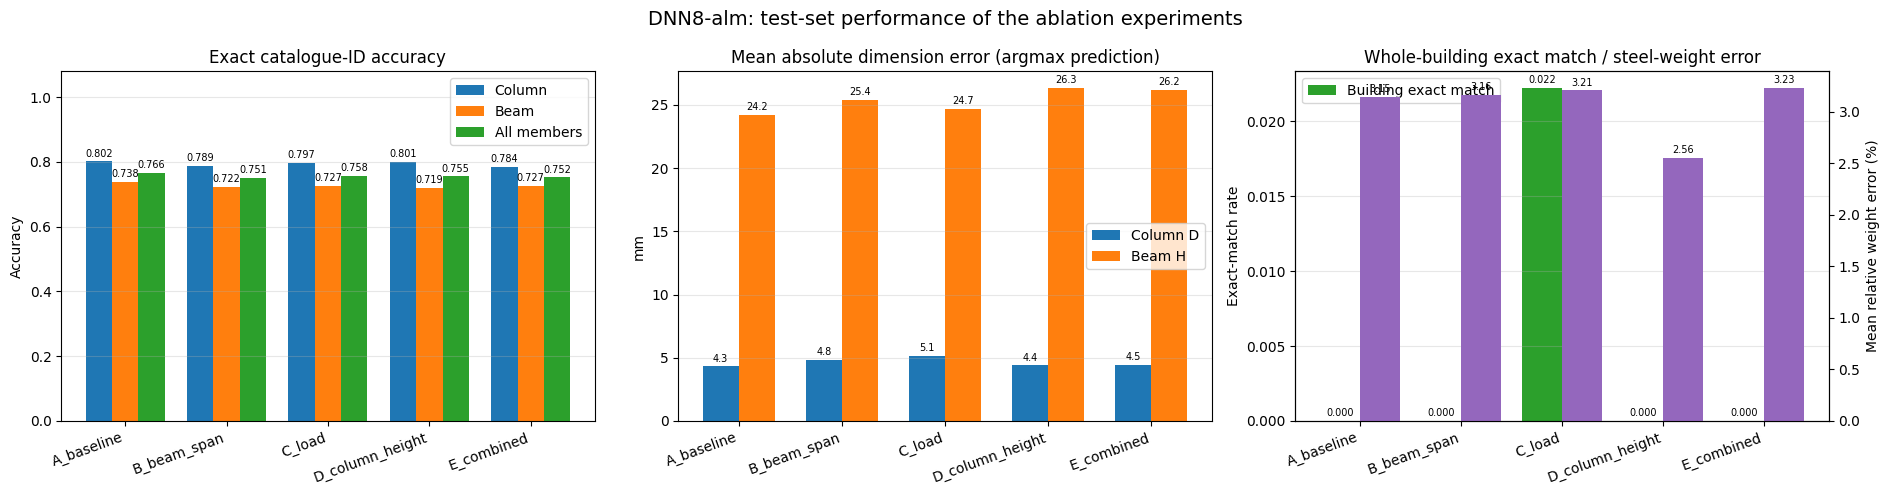

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-test-metrics-bars.png


PosixPath('/content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-test-metrics-bars.png')

In [5]:
# ============================================================
# A. Test metrics per experiment  (computed from the prediction files, so they are always available)
# ============================================================
def metrics_from_predictions(d):
    col, beam = d['member'].eq('column'), ~d['member'].eq('column')
    out = dict(n_members=len(d), n_buildings=d['file_name'].nunique(),
               column_accuracy=d.loc[col, 'is_correct'].mean(), beam_accuracy=d.loc[beam, 'is_correct'].mean(),
               slot_accuracy=d['is_correct'].mean(), slot_accuracy_nominal=d['is_correct_nominal'].mean(),
               MAE_D_mm=(d.loc[col, 'pred_D'] - d.loc[col, 'true_D']).abs().mean(),
               MAE_H_mm=(d.loc[beam, 'pred_H'] - d.loc[beam, 'true_H']).abs().mean())
    out['building_exact_match'] = d.groupby('file_name')['is_correct'].all().mean()
    return out


metrics_df = pd.DataFrame({n: metrics_from_predictions(DF[n]) for n in EXPERIMENTS}).T
metrics_df.index.name = 'experiment'
print('Metrics computed from dnn8-test-predictions-*.csv  (MAE uses the nominal catalogue dimension H / D):')
save_table(metrics_df.round(4), f'{dnn}-test-metrics-from-predictions.csv')

SUMMARY_PATH = ALM_DIR / 'dnn8-alm-test-summary.csv'
summary_df = pd.read_csv(SUMMARY_PATH, index_col='experiment') if SUMMARY_PATH.is_file() else None
if summary_df is not None:
    summary_df = summary_df.loc[[n for n in EXPERIMENTS if n in summary_df.index]]
    core = [c for c in ['column_accuracy', 'beam_accuracy', 'slot_accuracy', 'building_exact_match', 'MAE_D_argmax_mm',
                        'MAE_H_argmax_mm', 'MAE_D_expected_mm', 'MAE_H_expected_mm', 'weight_error_rel'] if c in summary_df]
    print('\nSummary written by the ALM notebook (dnn8-alm-test-summary.csv):')
    save_table(summary_df[core].round(4), f'{dnn}-test-summary-core.csv')
else:
    print(f'NOTE: {SUMMARY_PATH.name} not found - constraint-violation and weight-error panels are skipped.')

# ---- grouped bar charts --------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
src = summary_df if summary_df is not None else metrics_df
x = np.arange(len(EXPERIMENTS)); w = 0.26
for k, (c, lab) in enumerate([('column_accuracy', 'Column'), ('beam_accuracy', 'Beam'), ('slot_accuracy', 'All members')]):
    b = ax[0].bar(x + (k - 1) * w, src.loc[EXPERIMENTS, c], w, label=lab)
    ax[0].bar_label(b, fmt='%.3f', fontsize=7, padding=2)
ax[0].set(title='Exact catalogue-ID accuracy', ylabel='Accuracy', ylim=(0, 1.08))
dcol, hcol = ('MAE_D_argmax_mm', 'MAE_H_argmax_mm') if summary_df is not None else ('MAE_D_mm', 'MAE_H_mm')
for k, (c, lab) in enumerate([(dcol, 'Column D'), (hcol, 'Beam H')]):
    b = ax[1].bar(x + (k - 0.5) * 0.35, src.loc[EXPERIMENTS, c], 0.35, label=lab)
    ax[1].bar_label(b, fmt='%.1f', fontsize=7, padding=2)
ax[1].set(title='Mean absolute dimension error (argmax prediction)', ylabel='mm')
b = ax[2].bar(x - 0.2, src.loc[EXPERIMENTS, 'building_exact_match'], 0.4, label='Building exact match', color='tab:green')
ax[2].bar_label(b, fmt='%.3f', fontsize=7, padding=2)
ax[2].set(title='Whole-building exact match / steel-weight error', ylabel='Exact-match rate')
if summary_df is not None and 'weight_error_rel' in summary_df:
    a2 = ax[2].twinx()
    b = a2.bar(x + 0.2, summary_df.loc[EXPERIMENTS, 'weight_error_rel'] * 100, 0.4, color='tab:purple', label='Weight error (%)')
    a2.bar_label(b, fmt='%.2f', fontsize=7, padding=2); a2.set_ylabel('Mean relative weight error (%)')
for a in ax:
    a.set_xticks(x); a.set_xticklabels(EXPERIMENTS, rotation=20, ha='right'); a.grid(True, axis='y', alpha=0.3)
ax[0].legend(); ax[1].legend(); ax[2].legend(loc='upper left')
fig.suptitle(f'{dnn}: test-set performance of the ablation experiments', fontsize=14)
plt.tight_layout()
save_fig(fig, f'{dnn}-test-metrics-bars.png')

## B. Structural-monotonicity constraints on the test pairs

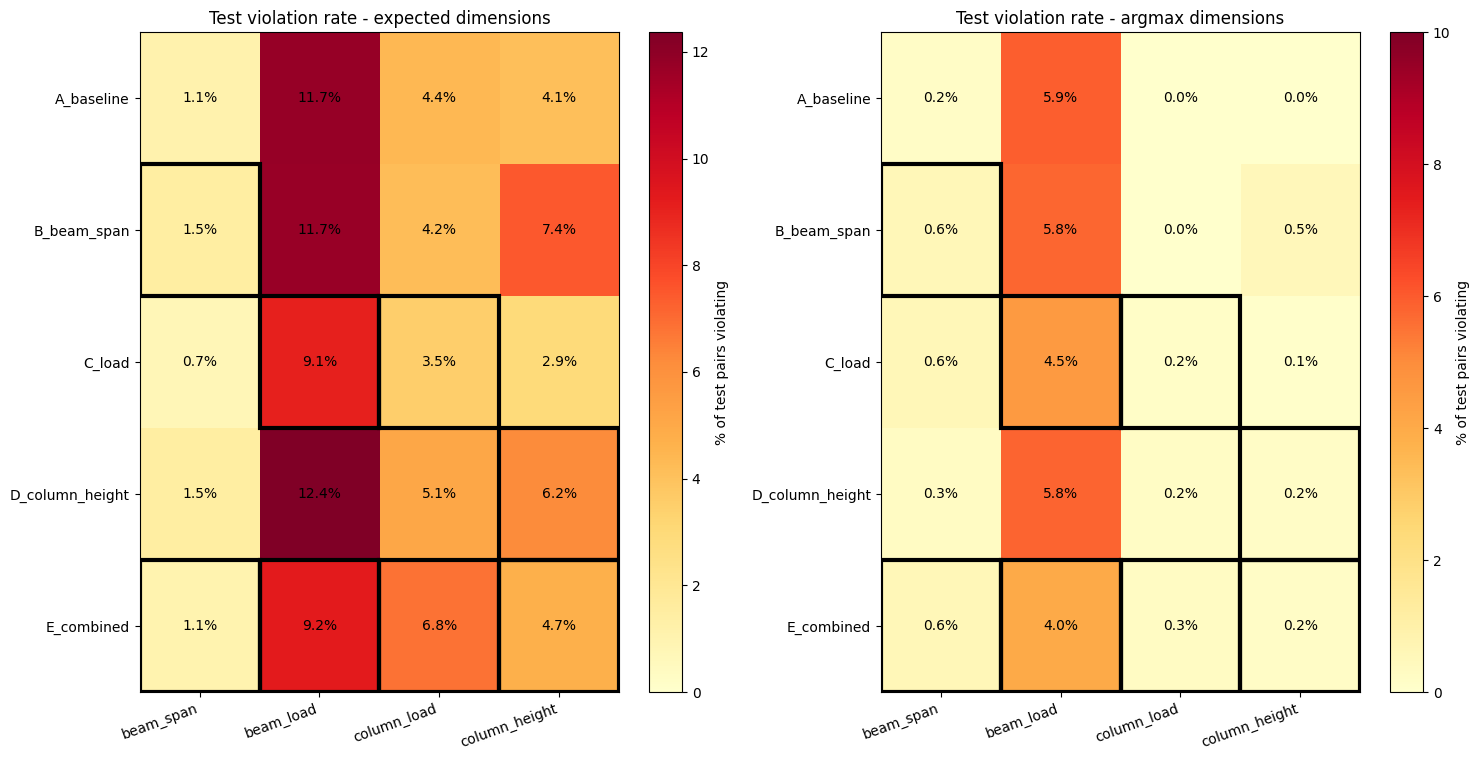

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-test-constraint-violation-heatmap.png
Violation rate [%] (expected):


,beam_span,beam_load,column_load,column_height
A_baseline,1.09,11.75,4.40,4.11
B_beam_span,1.49,11.71,4.19,7.45
C_load,0.75,9.08,3.51,2.91
D_column_height,1.46,12.37,5.11,6.20
E_combined,1.05,9.24,6.83,4.72


Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-test-violation-rate-expected.csv
Violation rate [%] (argmax):


,beam_span,beam_load,column_load,column_height
A_baseline,0.17,5.91,0.00,0.00
B_beam_span,0.58,5.75,0.03,0.53
C_load,0.58,4.54,0.15,0.05
D_column_height,0.27,5.79,0.20,0.16
E_combined,0.58,4.02,0.25,0.16


Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-test-violation-rate-argmax.csv
Mean violation depth [mm] of the argmax prediction (only violating pairs count towards the mean over all pairs):


,beam_span,beam_load,column_load,column_height
experiment,,,,
A_baseline,0.09,6.70,0.00,0.00
B_beam_span,0.29,6.22,0.01,0.26
C_load,0.27,4.62,0.08,0.03
D_column_height,0.13,6.33,0.10,0.08
E_combined,0.21,4.54,0.13,0.08


Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-test-violation-mm-argmax.csv


In [6]:
# ============================================================
# B. Structural-monotonicity constraints on the test pairs  (from dnn8-alm-test-summary.csv)
#    rate = share of test pairs that violate the prior.  Black frame = the constraint was ENFORCED in that experiment
#    (otherwise it is a diagnostic only).  'expected' = soft dimension used by the ALM, 'argmax' = final prediction.
# ============================================================
if summary_df is None:
    print('Skipped: dnn8-alm-test-summary.csv is missing.')
else:
    from matplotlib.patches import Rectangle
    fig, axes = plt.subplots(1, 2, figsize=(15, 0.9 * len(EXPERIMENTS) + 3.2))
    tabs = {}
    for ax, space in zip(axes, ('expected', 'argmax')):
        cols = [f'{f}|{space}|rate' for f in FAMILIES if f'{f}|{space}|rate' in summary_df]
        fams = [c.split('|')[0] for c in cols]
        M = summary_df.loc[EXPERIMENTS, cols].to_numpy(float) * 100
        tabs[space] = pd.DataFrame(M, index=EXPERIMENTS, columns=fams)
        im = ax.imshow(M, cmap='YlOrRd', vmin=0, vmax=max(10.0, np.nanmax(M)), aspect='auto')
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                ax.text(j, i, f'{M[i, j]:.1f}%', ha='center', va='center', fontsize=10)
                if fams[j] in ENFORCED.get(EXPERIMENTS[i], set()):
                    ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, ec='black', lw=3))
        ax.set_xticks(range(len(fams))); ax.set_xticklabels(fams, rotation=20, ha='right')
        ax.set_yticks(range(len(EXPERIMENTS))); ax.set_yticklabels(EXPERIMENTS)
        ax.set_title(f'Test violation rate - {space} dimensions')
        plt.colorbar(im, ax=ax, label='% of test pairs violating')
    plt.tight_layout()
    save_fig(fig, f'{dnn}-test-constraint-violation-heatmap.png')
    for space, t in tabs.items():
        print(f'Violation rate [%] ({space}):'); save_table(t.round(2), f'{dnn}-test-violation-rate-{space}.csv')
    mm = [c for c in summary_df if c.endswith('|argmax|mean_violation_mm')]
    if mm:
        t = summary_df.loc[EXPERIMENTS, mm].rename(columns=lambda c: c.split('|')[0])
        print('Mean violation depth [mm] of the argmax prediction (only violating pairs count towards the mean over all pairs):')
        save_table(t.round(2), f'{dnn}-test-violation-mm-argmax.csv')

## C. Training histories

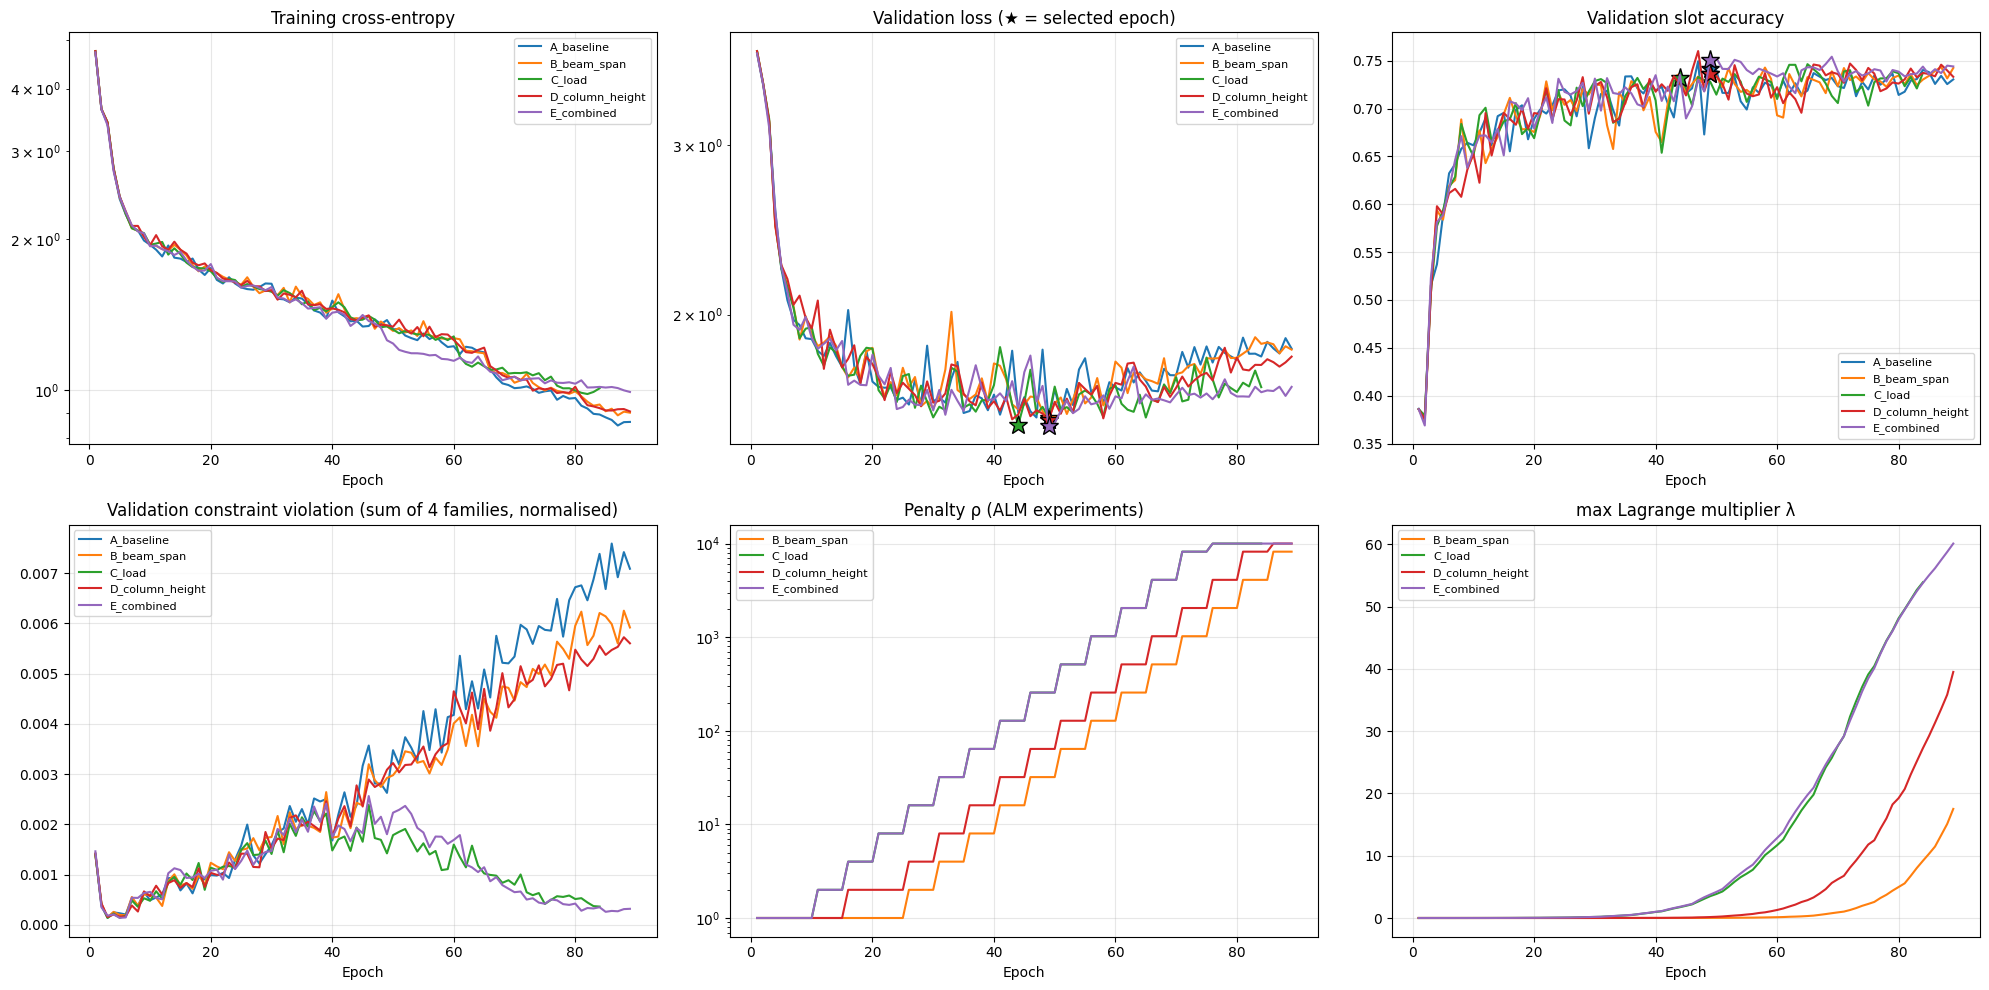

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-training-curves.png


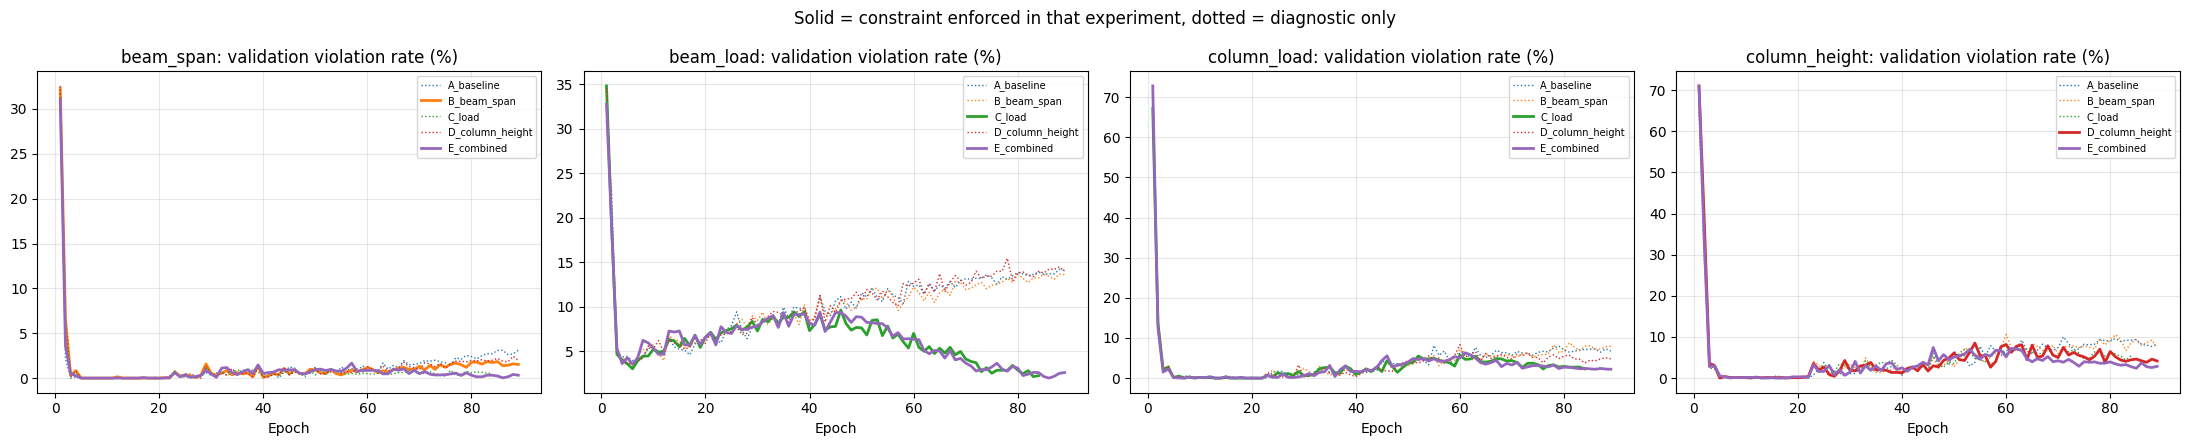

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-training-violation-by-family.png


,epochs_run,best_epoch,val_loss,val_slot_acc,final_rho,final_lambda_max
experiment,,,,,,
A_baseline,89,49,1.55424,0.74162,1.0,0.00000
B_beam_span,89,49,1.56065,0.73621,8192.0,17.51113
C_load,84,44,1.53608,0.73232,10000.0,53.88578
D_column_height,89,49,1.55307,0.73570,10000.0,39.49820
E_combined,89,49,1.53398,0.75093,10000.0,60.10409


Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-training-overview.csv


In [7]:
# ============================================================
# C. Training histories of the experiments  (dnn8-training-history-<experiment>.csv)
# ============================================================
HIST = {n: pd.read_csv(ALM_DIR / f'dnn8-training-history-{n}.csv') for n in EXPERIMENTS
        if (ALM_DIR / f'dnn8-training-history-{n}.csv').is_file()}
if not HIST:
    print('No training-history files found - section skipped.')
else:
    fig, ax = plt.subplots(2, 3, figsize=(20, 10)); ax = ax.ravel()
    for n, h in HIST.items():
        kw = dict(label=n, color=COLORS[n])
        ax[0].plot(h['epoch'], h['train_classification_loss'], **kw)
        ax[1].plot(h['epoch'], h['validation_loss'], **kw)
        ax[2].plot(h['epoch'], h['validation_slot_accuracy'], **kw)
        ax[3].plot(h['epoch'], sum(h[f'{f}_violation'] for f in FAMILIES if f'{f}_violation' in h), **kw)
        if (h['rho'] > 0).any() and h.get('lambda_max', pd.Series([0])).max() > 0:
            ax[4].plot(h['epoch'], h['rho'], **kw); ax[5].plot(h['epoch'], h['lambda_max'], **kw)
        be = h['selection_metric'].idxmin()
        for a, col in ((ax[1], 'validation_loss'), (ax[2], 'validation_slot_accuracy')):
            a.plot(h.loc[be, 'epoch'], h.loc[be, col], marker='*', ms=14, color=COLORS[n], mec='k')
    ax[0].set(title='Training cross-entropy', yscale='log'); ax[1].set(title='Validation loss (★ = selected epoch)', yscale='log')
    ax[2].set(title='Validation slot accuracy'); ax[3].set(title='Validation constraint violation (sum of 4 families, normalised)')
    ax[4].set(title='Penalty ρ (ALM experiments)', yscale='log'); ax[5].set(title='max Lagrange multiplier λ')
    for a in ax:
        a.set_xlabel('Epoch'); a.grid(True, alpha=0.3); a.legend(fontsize=8)
    plt.tight_layout(); save_fig(fig, f'{dnn}-training-curves.png')

    fig, ax = plt.subplots(1, 4, figsize=(22, 4.5))
    for a, f in zip(ax, FAMILIES):
        for n, h in HIST.items():
            if f'{f}_violation_rate' in h:
                a.plot(h['epoch'], h[f'{f}_violation_rate'] * 100, color=COLORS[n], label=n, lw=2 if f in ENFORCED.get(n, ()) else 1,
                       ls='-' if f in ENFORCED.get(n, ()) else ':')
        a.set(title=f'{f}: validation violation rate (%)', xlabel='Epoch'); a.grid(True, alpha=0.3); a.legend(fontsize=7)
    plt.suptitle('Solid = constraint enforced in that experiment, dotted = diagnostic only'); plt.tight_layout()
    save_fig(fig, f'{dnn}-training-violation-by-family.png')

    rows = []
    for n, h in HIST.items():
        be = h['selection_metric'].idxmin()
        rows.append(dict(experiment=n, epochs_run=len(h), best_epoch=int(h.loc[be, 'epoch']),
                         val_loss=h.loc[be, 'validation_loss'], val_slot_acc=h.loc[be, 'validation_slot_accuracy'],
                         final_rho=h['rho'].iloc[-1], final_lambda_max=h['lambda_max'].iloc[-1]))
    save_table(pd.DataFrame(rows).set_index('experiment').round(5), f'{dnn}-training-overview.csv')

## D. Error analysis (parity, signed error, accuracy by story / parameter)

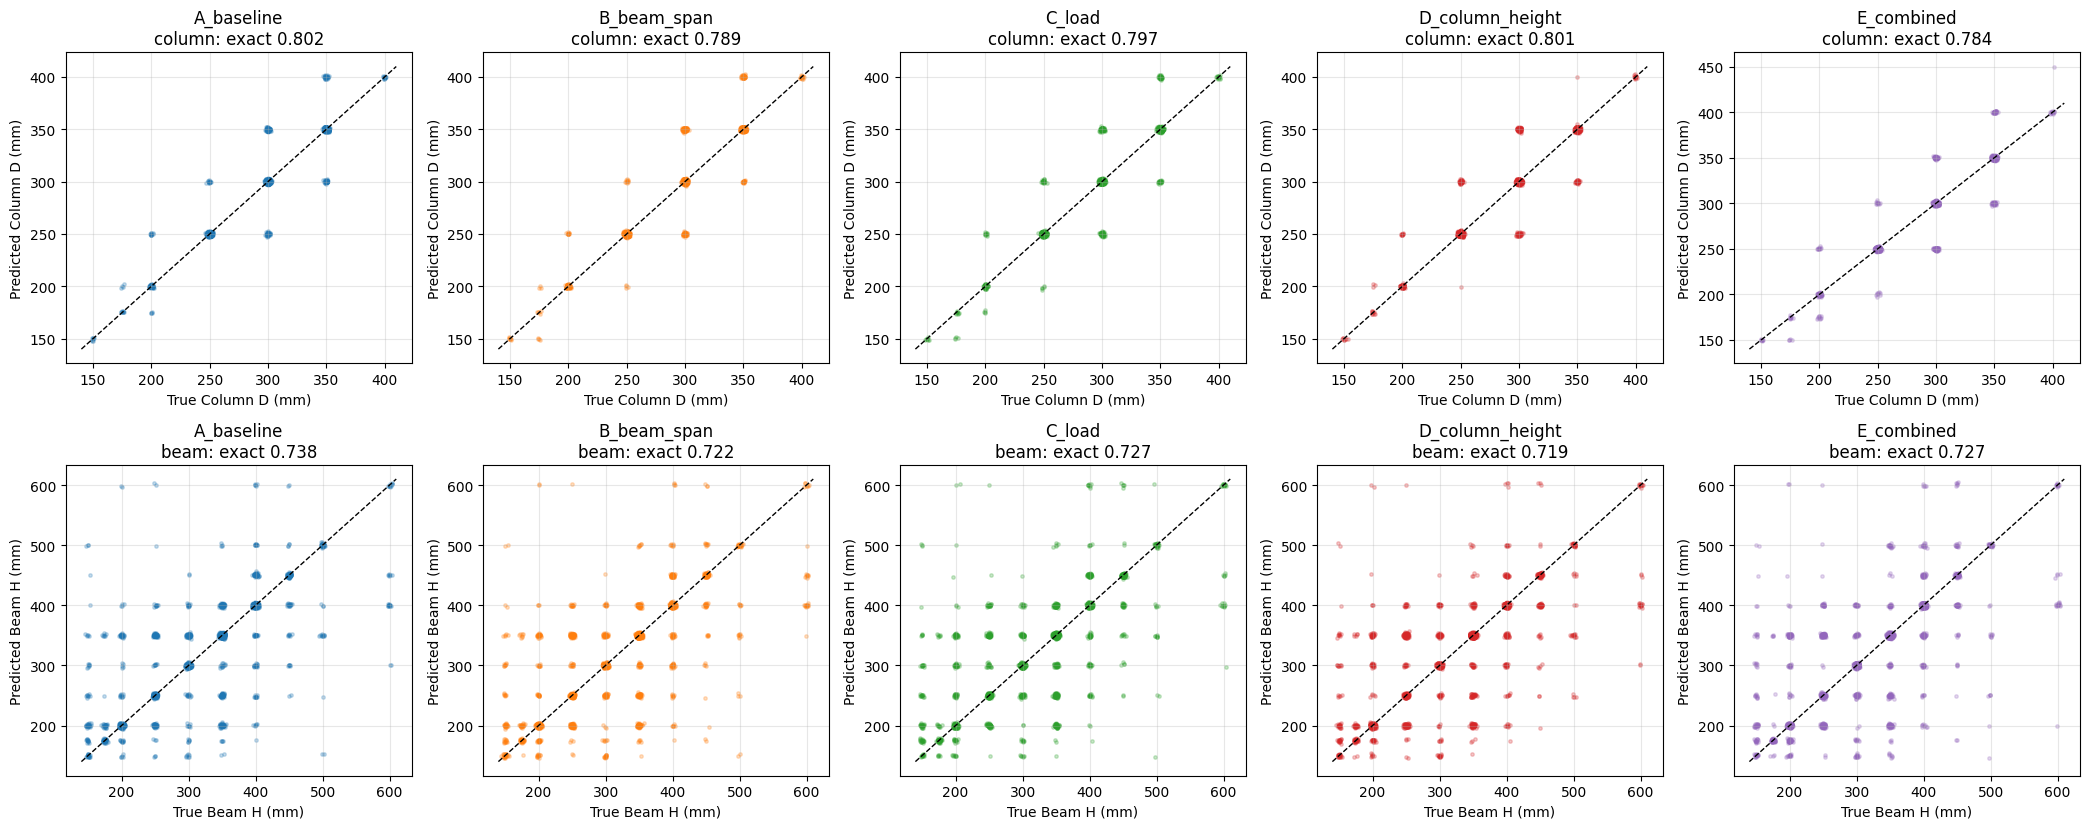

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-parity-plots.png


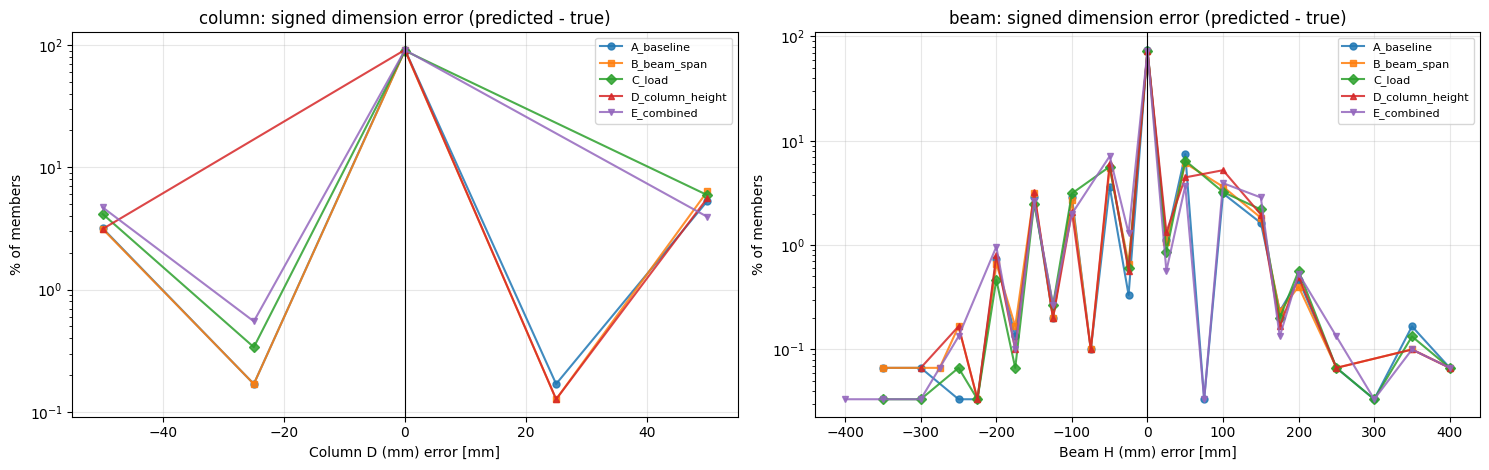

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-error-distribution.png
Over-/under-sized = predicted catalogue dimension larger/smaller than the optimised (teacher) one. Under-sizing is the safety-relevant direction, but the DNN output must still be checked by structural analysis.


n  exact_pct  oversized_pct  undersized_pct  \
member experiment                                                        
column A_baseline       2364     91.201          5.457           3.342   
       B_beam_span      2364     90.228          6.472           3.299   
       C_load           2364     89.594          5.922           4.484   
       D_column_height  2364     91.159          5.711           3.130   
       E_combined       2364     90.821          3.934           5.245   
beam   A_baseline       3006     74.518         14.405          11.078   
       B_beam_span      3006     73.054         13.473          13.473   
       C_load           3006     73.353         13.806          12.841   
       D_column_height  3006     72.655         13.872          13.473   
       E_combined       3006     73.253         12.076          14.671   

                        bias_mm  MAE_mm  RMSE_mm  P95_abs_mm  
member experiment                                             
column A_baseline         1.058   4.315   14.616        50.0  
       B_beam_span        1.597   4.812   15.451        50.0  
       C_load             0.804   5.118   15.931        50.0  
       D_column_height    1.258   4.389   14.787        50.0  
       E_combined        -0.518   4.452   14.804        50.0  
beam   A_baseline         0.366  23.752   55.581       150.0  
       B_beam_span       -1.497  24.834   56.180       150.0  
       C_load             0.757  24.127   54.849       150.0  
       D_column_height   -0.158  25.757   57.190       150.0  
       E_combined        -0.549  25.699   58.497       150.0

Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-error-table.csv


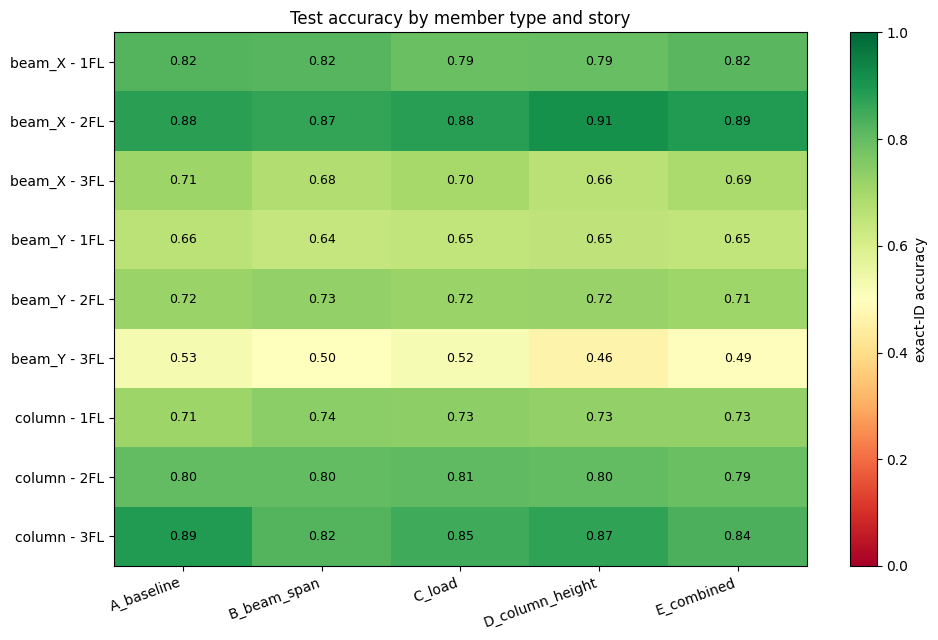

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-accuracy-by-member-story.png
Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-accuracy-by-member-story.csv


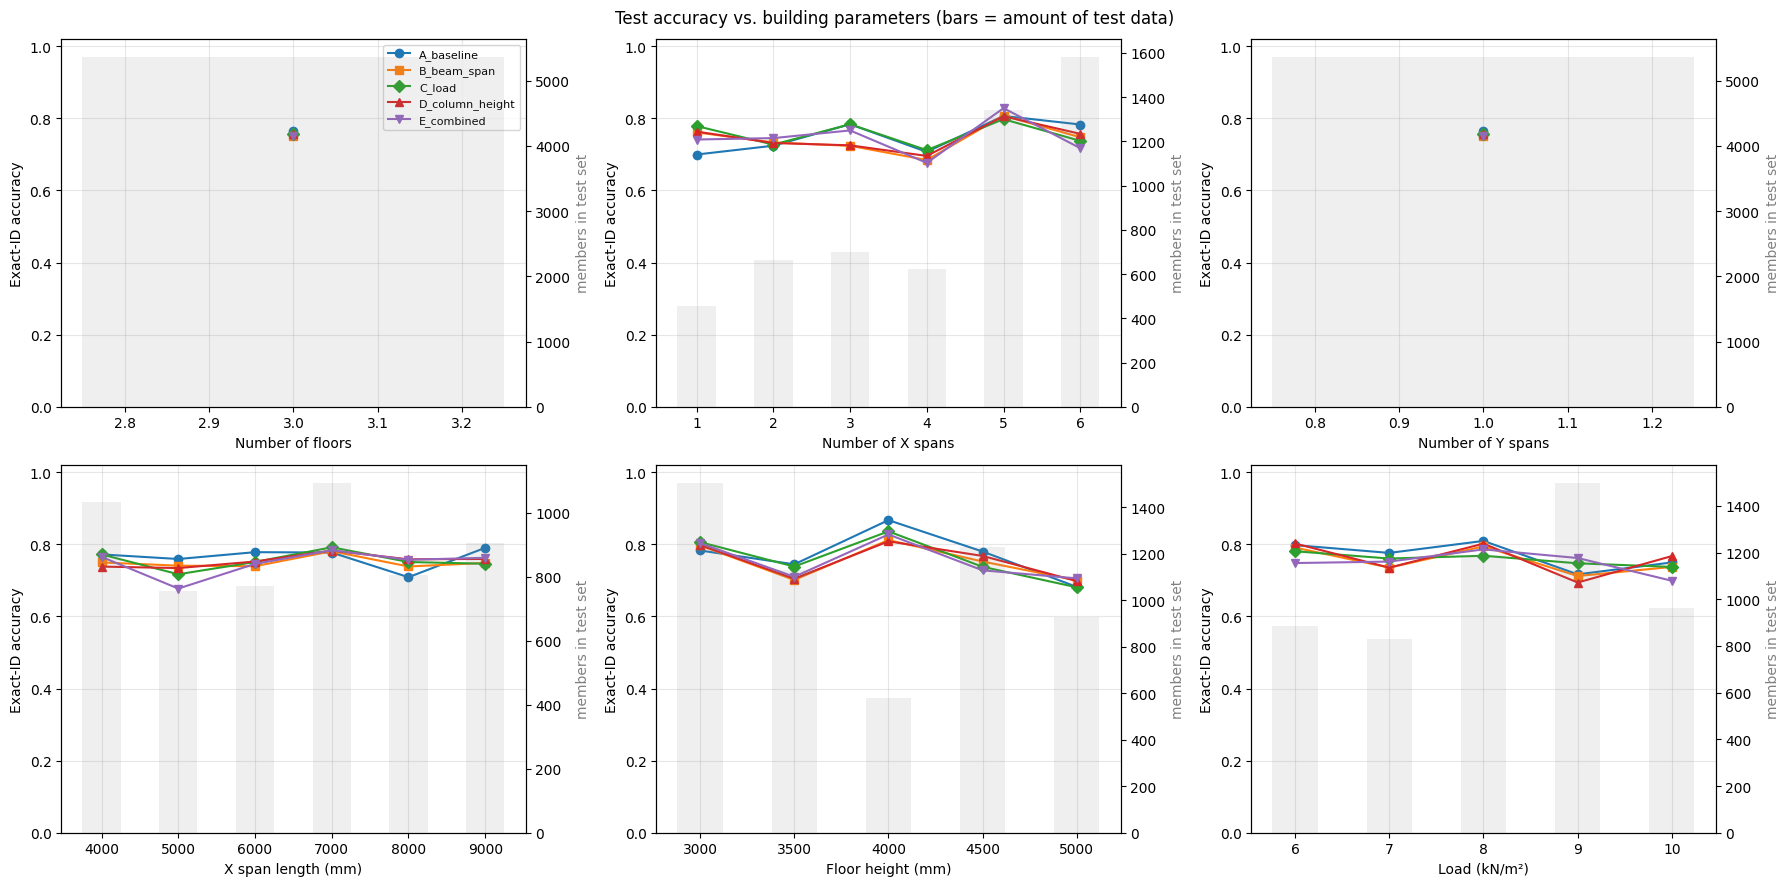

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-accuracy-vs-building-parameters.png
Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-accuracy-vs-building-parameters.csv


PosixPath('/content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-accuracy-vs-building-parameters.csv')

In [8]:
# ============================================================
# D. Error analysis of the test predictions
#    parity plots, signed-error distributions (over-/under-sized), accuracy by member x story and by building parameter
# ============================================================
SIDE = {'column': ('D', 'Column D (mm)'), 'beam': ('H', 'Beam H (mm)')}
def _side(d, kind):
    m = d['member'].eq('column') if kind == 'column' else ~d['member'].eq('column')
    return d[m]

# ---- D1  parity plots (pred vs. true, jittered) ---------------------------
rng_plot = np.random.default_rng(0)
fig, axes = plt.subplots(2, len(EXPERIMENTS), figsize=(4.2 * len(EXPERIMENTS), 8.4), squeeze=False)
for c, n in enumerate(EXPERIMENTS):
    for r, kind in enumerate(('column', 'beam')):
        dim, lab = SIDE[kind]; s = _side(DF[n], kind); a = axes[r, c]
        t, p = s[f'true_{dim}'].to_numpy(), s[f'pred_{dim}'].to_numpy()
        jit = 0.004 * (np.nanmax(t) - np.nanmin(t))
        a.scatter(t + rng_plot.normal(0, jit, len(t)), p + rng_plot.normal(0, jit, len(p)), s=6, alpha=0.25, color=COLORS[n])
        lim = [np.nanmin(t) - 10, np.nanmax(t) + 10]; a.plot(lim, lim, 'k--', lw=1)
        a.set(title=f'{n}\n{kind}: exact {s["is_correct"].mean():.3f}', xlabel=f'True {lab}', ylabel=f'Predicted {lab}'); a.grid(alpha=0.3)
plt.tight_layout(); save_fig(fig, f'{dnn}-parity-plots.png')

# ---- D2  signed error distribution + over/under-sizing table ----------------
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8)); rows = []
for a, kind in zip(axes, ('column', 'beam')):
    dim, lab = SIDE[kind]
    for n in EXPERIMENTS:
        s = _side(DF[n], kind); e = (s[f'pred_{dim}'] - s[f'true_{dim}']).to_numpy()
        vals, cnt = np.unique(e, return_counts=True)
        a.plot(vals, cnt / len(e) * 100, marker=MARKERS[n], ms=5, color=COLORS[n], label=n, alpha=0.85)
        rows.append(dict(experiment=n, member=kind, n=len(e), exact_pct=(e == 0).mean() * 100,
                         oversized_pct=(e > 0).mean() * 100, undersized_pct=(e < 0).mean() * 100, bias_mm=e.mean(),
                         MAE_mm=np.abs(e).mean(), RMSE_mm=np.sqrt((e ** 2).mean()), P95_abs_mm=np.percentile(np.abs(e), 95)))
    a.axvline(0, color='k', lw=0.8); a.set(title=f'{kind}: signed dimension error (predicted - true)', xlabel=f'{lab} error [mm]',
                                            ylabel='% of members', yscale='log'); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); save_fig(fig, f'{dnn}-error-distribution.png')
err_df = pd.DataFrame(rows).round(3)
print('Over-/under-sized = predicted catalogue dimension larger/smaller than the optimised (teacher) one. '
      'Under-sizing is the safety-relevant direction, but the DNN output must still be checked by structural analysis.')
save_table(err_df.set_index(['member', 'experiment']), f'{dnn}-error-table.csv')

# ---- D3  accuracy by member x story ----------------------------------------
def acc_by_member_story(d):
    g = d.assign(kind=np.where(d['member'].eq('column'), 'column', d['member'])).groupby(['kind', 'story'])['is_correct'].mean()
    return g
acc_ms = pd.DataFrame({n: acc_by_member_story(DF[n]) for n in EXPERIMENTS})
fig, ax = plt.subplots(figsize=(1.4 * len(EXPERIMENTS) + 3, 0.5 * len(acc_ms) + 2))
im = ax.imshow(acc_ms.to_numpy(float), cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
for i in range(acc_ms.shape[0]):
    for j in range(acc_ms.shape[1]):
        ax.text(j, i, f'{acc_ms.iat[i, j]:.2f}', ha='center', va='center', fontsize=9)
ax.set_xticks(range(len(EXPERIMENTS))); ax.set_xticklabels(EXPERIMENTS, rotation=20, ha='right')
ax.set_yticks(range(len(acc_ms))); ax.set_yticklabels([f'{k} - {s}FL' for k, s in acc_ms.index])
plt.colorbar(im, label='exact-ID accuracy'); ax.set_title('Test accuracy by member type and story'); plt.tight_layout()
save_fig(fig, f'{dnn}-accuracy-by-member-story.png')
save_table(acc_ms.round(4), f'{dnn}-accuracy-by-member-story.csv', show=False)

# ---- D4  accuracy vs. building parameter -----------------------------------
PARAMS = [('n_floors', 'Number of floors'), ('n_x_spans', 'Number of X spans'), ('n_y_spans', 'Number of Y spans'),
          ('x_span_length', 'X span length (mm)'), ('floor_height', 'Floor height (mm)'), ('load', 'Load (kN/m²)')]
fig, axes = plt.subplots(2, 3, figsize=(18, 9)); tab = {}
for a, (c, lab) in zip(axes.ravel(), PARAMS):
    for n in EXPERIMENTS:
        g = DF[n].dropna(subset=[c]).groupby(c)['is_correct'].agg(['mean', 'size'])
        a.plot(g.index, g['mean'], marker=MARKERS[n], color=COLORS[n], label=n); tab[(c, n)] = g['mean']
    cnt = DF[REF].dropna(subset=[c]).groupby(c).size()
    a2 = a.twinx(); a2.bar(cnt.index, cnt.values, alpha=0.12, width=(np.ptp(cnt.index) / max(len(cnt), 1)) * 0.6 or 0.5, color='gray')
    a2.set_ylabel('members in test set', color='gray'); a.set(xlabel=lab, ylabel='Exact-ID accuracy', ylim=(0, 1.02)); a.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8); plt.suptitle('Test accuracy vs. building parameters (bars = amount of test data)'); plt.tight_layout()
save_fig(fig, f'{dnn}-accuracy-vs-building-parameters.png')
save_table(pd.DataFrame(tab).round(4), f'{dnn}-accuracy-vs-building-parameters.csv', show=False)

## E. Plan view of the worst and best test building

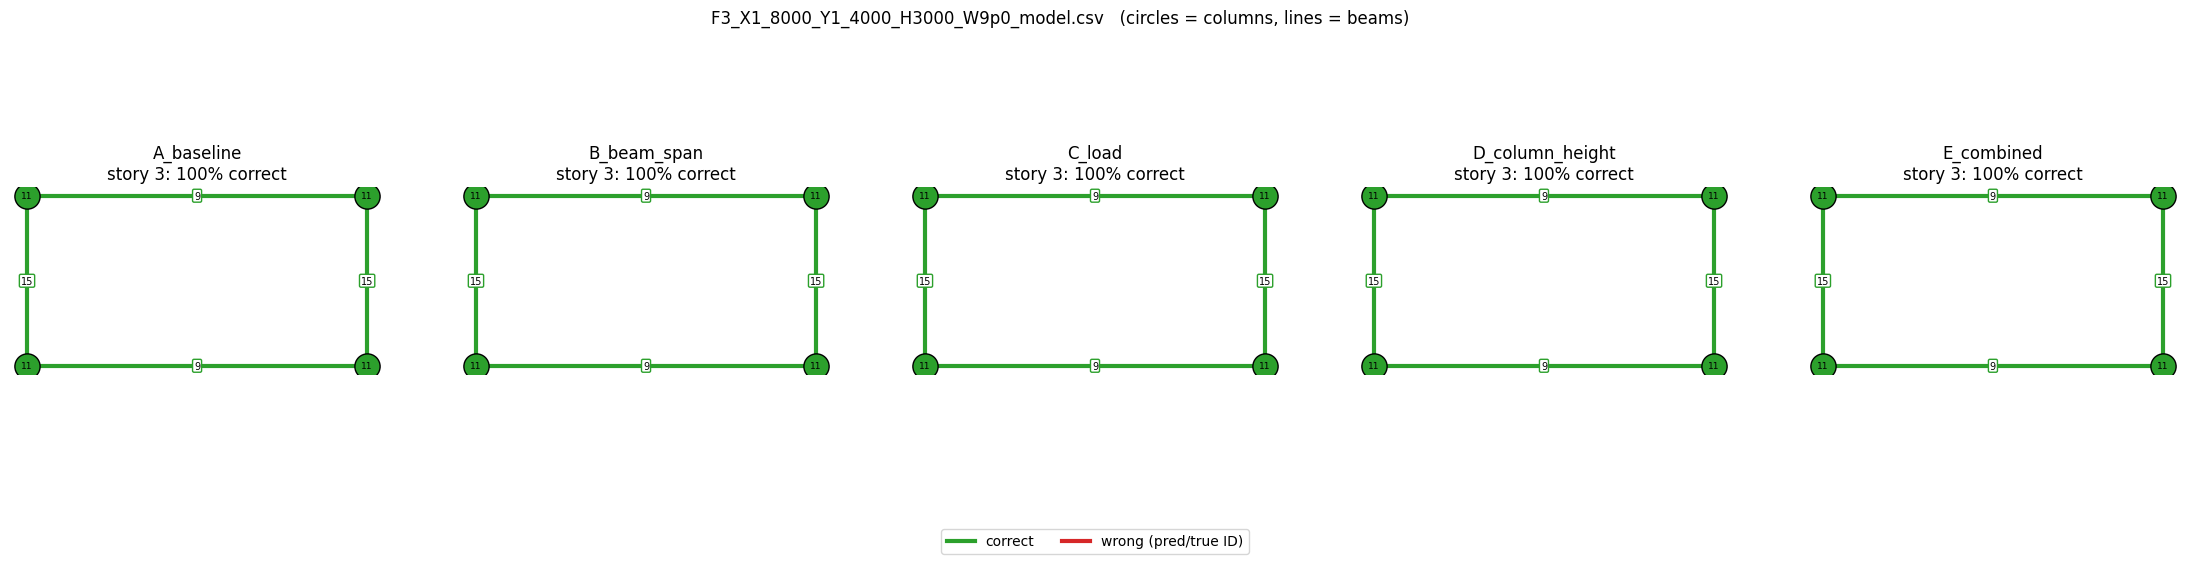

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-plan-F3_X1_8000_Y1_4000_H3000_W9p0_model-story3.png


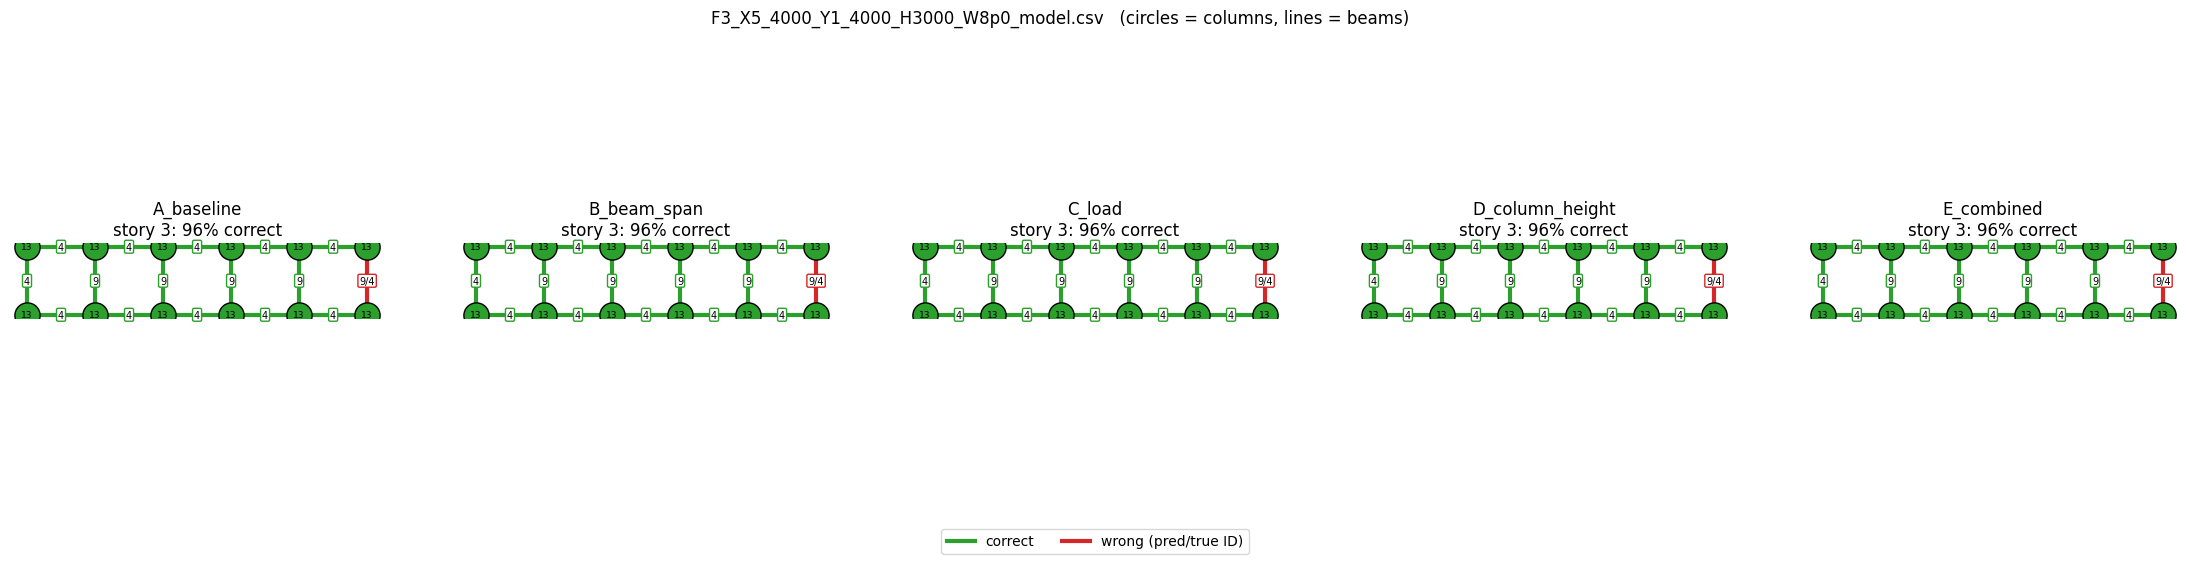

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-plan-F3_X5_4000_Y1_4000_H3000_W8p0_model-story3.png


In [9]:
# ============================================================
# E. Plan view of one test building: where is the DNN right / wrong?
#    green = correct, red = wrong (label = predicted ID / true ID).  Spans are drawn uniform (from the file name).
# ============================================================
def plot_building_plan(dfs, file_name=None, story=None, which='worst', experiments=None, show=True):
    names = list(experiments or dfs)
    base = dfs[names[0]]
    acc = base.groupby('file_name')['is_correct'].mean().sort_values()
    if file_name is None:
        file_name = acc.index[0] if which == 'worst' else acc.index[-1]
    b = base[base['file_name'] == file_name]
    story = story or int(b['story'].max())
    xl, yl = b['x_span_length'].iloc[0], b['y_span_length'].iloc[0]
    fig, axes = plt.subplots(1, len(names), figsize=(5.6 * len(names), 5.6), squeeze=False)
    for a, n in zip(axes[0], names):
        d = dfs[n]; d = d[(d['file_name'] == file_name) & (d['story'] == story)]
        for _, r in d.iterrows():
            x0, y0 = (r['x_line'] - 1) * xl, (r['y_line'] - 1) * yl
            ok = bool(r['is_correct']); c = 'tab:green' if ok else 'tab:red'
            txt = f'{int(r["predicted_id"])}' if ok else f'{int(r["predicted_id"])}/{int(r["true_id"])}'
            if r['member'] == 'column':
                a.scatter([x0], [y0], s=330, color=c, zorder=3, edgecolor='k')
                a.text(x0, y0, txt, ha='center', va='center', fontsize=6.5, zorder=4, color='white' if not ok else 'k')
            else:
                dx, dy = (xl, 0) if r['member'] == 'beam_X' else (0, yl)
                a.plot([x0, x0 + dx], [y0, y0 + dy], color=c, lw=3, zorder=2)
                a.text(x0 + dx / 2, y0 + dy / 2, txt, ha='center', va='center', fontsize=7,
                       bbox=dict(fc='white', ec=c, boxstyle='round,pad=0.15'), zorder=4)
        a.set_title(f'{n}\nstory {story}: {d["is_correct"].mean():.0%} correct'); a.set_aspect('equal'); a.axis('off')
    handles = [Line2D([0], [0], color='tab:green', lw=3, label='correct'), Line2D([0], [0], color='tab:red', lw=3, label='wrong (pred/true ID)')]
    fig.legend(handles=handles, loc='lower center', ncol=2)
    fig.suptitle(f'{file_name}   (circles = columns, lines = beams)')
    save_fig(fig, f'{dnn}-plan-{Path(file_name).stem}-story{story}.png', show=show)
    return file_name

worst_file = plot_building_plan(DF, which='worst')       # test building with the lowest accuracy (reference experiment)
best_file = plot_building_plan(DF, which='best')

## F. Plot function: member dimension vs. one varying parameter (all experiments)

`plot_dim_vs_variable(DF, member, dim, vary, position, experiments=None)` — `member`: `beam_X` / `beam_Y` / `column`; `dim`: `H` (beams) or `D` (columns); `vary`: `x_span` / `load` / `story` / `floor_height`; `position`: e.g. `X1-Y1`. Pass `experiments=['A_baseline','E_combined']` to show only some.

In [10]:
# ============================================================
# Plot : member dimension vs. one varying building parameter, for ALL experiments at once
#
#    dfs    : dict {experiment: transformed dataframe}  (or a single dataframe)
#    member : 'beam_X' | 'beam_Y' | 'column'
#    dim    : 'H' (beam depth) | 'D' (column width)
#    vary   : 'x_span' | 'load' | 'story' | 'floor_height'
#    position : grid position such as 'X1-Y1'.  story_fixed : floor to use when vary != 'story'
#
#    Everything except the varying parameter is held constant: the file name (varying token masked) + the slot form one
#    "building condition key"; the key covering the most distinct values of the varying parameter is used.
#    The condition key is chosen on the reference experiment; the other experiments are looked up for the same members.
# ============================================================
VARY = {
    'x_span': dict(col='x_span_length', mask=(r'_X\d+_\d+_', '_XSPAN_'), xlabel='X-Span Length (mm)', name='X_Span_Length'),
    'load':   dict(col='load', mask=(r'_W\d+p\d+_', '_WLOAD_'), xlabel='Building Load (kN/m²)', name='Building_Load'),
    'floor_height': dict(col='floor_height', mask=(r'_H\d+_', '_HFLOOR_'), xlabel='Floor Height (mm)', name='Floor_Height'),
    'story':  dict(col='story', mask=None, xlabel='Floor', name='Floor'),
}
DIM_LABEL = {'H': 'Member H-Length (mm)', 'D': 'Column D-Dimension (mm)'}


def plot_dim_vs_variable(dfs, member, dim, vary, position=None, story_fixed=None, experiments=None, show=True):
    dfs = {dnn: dfs} if isinstance(dfs, pd.DataFrame) else dict(dfs)
    names = list(experiments or dfs)
    v = VARY[vary]
    section_type = 'box' if member == 'column' else 'h'
    if (member == 'column') != (dim == 'D'):
        raise ValueError("dim must be 'D' for columns and 'H' for beams")

    d = dfs[names[0]]
    d = d[(d['member'] == member) & (d['section_type'] == section_type)].copy()
    if position is not None:
        d = d[d['grid_position'] == position]
    if story_fixed is not None and vary != 'story':
        d = d[d['story'] == story_fixed]
    d = d.dropna(subset=[v['col'], f'pred_{dim}', f'true_{dim}'])

    fname, slot = d['file_name'], d['slot']
    if v['mask'] is not None:
        fname = fname.str.replace(v['mask'][0], v['mask'][1], regex=True)
    if vary == 'story':                                   # mask the floor inside the slot
        slot = slot.str.replace(r':\d+FL:', ':FL:', regex=True)
        fname = d['file_name']
    d['building_condition_key'] = fname + ' | ' + slot

    cover = d.groupby('building_condition_key')[v['col']].nunique()
    if cover.empty:
        raise ValueError('No data for the requested member / position / floor.')
    best = cover[cover == cover.max()].sort_index().index[0]      # deterministic tie-break
    summary = (d[d['building_condition_key'] == best]
               .sort_values([v['col'], 'file_name', 'slot'])
               .drop_duplicates(subset=v['col'], keep='first').reset_index(drop=True))
    summary = summary[['file_name', 'slot', 'grid_position', v['col'], f'true_{dim}']].copy()
    for n in names:                                                # predicted value of every experiment, same member
        look = dfs[n].drop_duplicates(['file_name', 'slot']).set_index(['file_name', 'slot'])[f'pred_{dim}']
        summary[f'pred_{dim}|{n}'] = [look.get((f, s), np.nan) for f, s in zip(summary['file_name'], summary['slot'])]

    # ---- plot ------------------------------------------------
    nrow = len(summary)
    fig = plt.figure(figsize=(14, 9 + 0.32 * nrow))
    gs = fig.add_gridspec(2, 1, height_ratios=[9, 0.32 * nrow + 0.4], hspace=0.22)
    ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
    x = summary[v['col']]
    for n in names:
        ax.plot(x, summary[f'pred_{dim}|{n}'], marker=MARKERS.get(n, 'o'), linestyle='--', color=COLORS.get(n, 'blue'),
                linewidth=1.8, markersize=8, alpha=0.9, label=f'Predicted  {n}')
    ax.plot(x, summary[f'true_{dim}'], marker='x', linestyle='-', color='red', linewidth=2.5, markersize=11,
            label='Ground Truth')
    for i, (_, r) in enumerate(summary.iterrows(), start=1):
        ax.annotate(str(i), xy=(r[v['col']], r[f'true_{dim}']), xytext=(7, -17), textcoords='offset points',
                    color='red', fontsize=10, fontweight='bold')
    ax.legend(loc='best', fontsize=9, frameon=True)
    if vary == 'story':
        ax.set_xticks(sorted(x.unique()))
    ax.set_xlabel(v['xlabel'], fontsize=12)
    ax.set_ylabel(DIM_LABEL[dim], fontsize=12)
    pos_txt = summary['grid_position'].iloc[0]
    ax.set_title(f'{DIM_LABEL[dim]} vs. {v["xlabel"]}  [{member} @ {pos_txt}]  ({dnn})', fontsize=14)
    ax.grid(True, alpha=0.3)

    axt.axis('off')                                                # numbered point -> file, true and predicted values
    lines = []
    for i, (_, r) in enumerate(summary.iterrows(), start=1):
        preds = '  '.join(f'{n.split("_")[0]}={r[f"pred_{dim}|{n}"]:g}' for n in names)
        lines.append(f'{i}. {r["file_name"]} | {r["slot"]}   GT {dim}={r[f"true_{dim}"]:g}   |   {preds}')
    axt.text(0, 1, '\n'.join(lines), va='top', ha='left', fontsize=8, family='monospace', transform=axt.transAxes)

    out = save_fig(fig, f'{dnn}-{member}-{dim}-vs-{v["name"]}-{pos_txt}.png', dpi=300, show=show)
    save_table(summary, f'{dnn}-{member}-{dim}-vs-{v["name"]}-{pos_txt}.csv', index=False, show=False)
    print(f'Building condition key: {best}')
    print(f'Distinct values plotted ({vary}): {summary[v["col"]].tolist()}')
    return summary

### Beam H vs. X-span

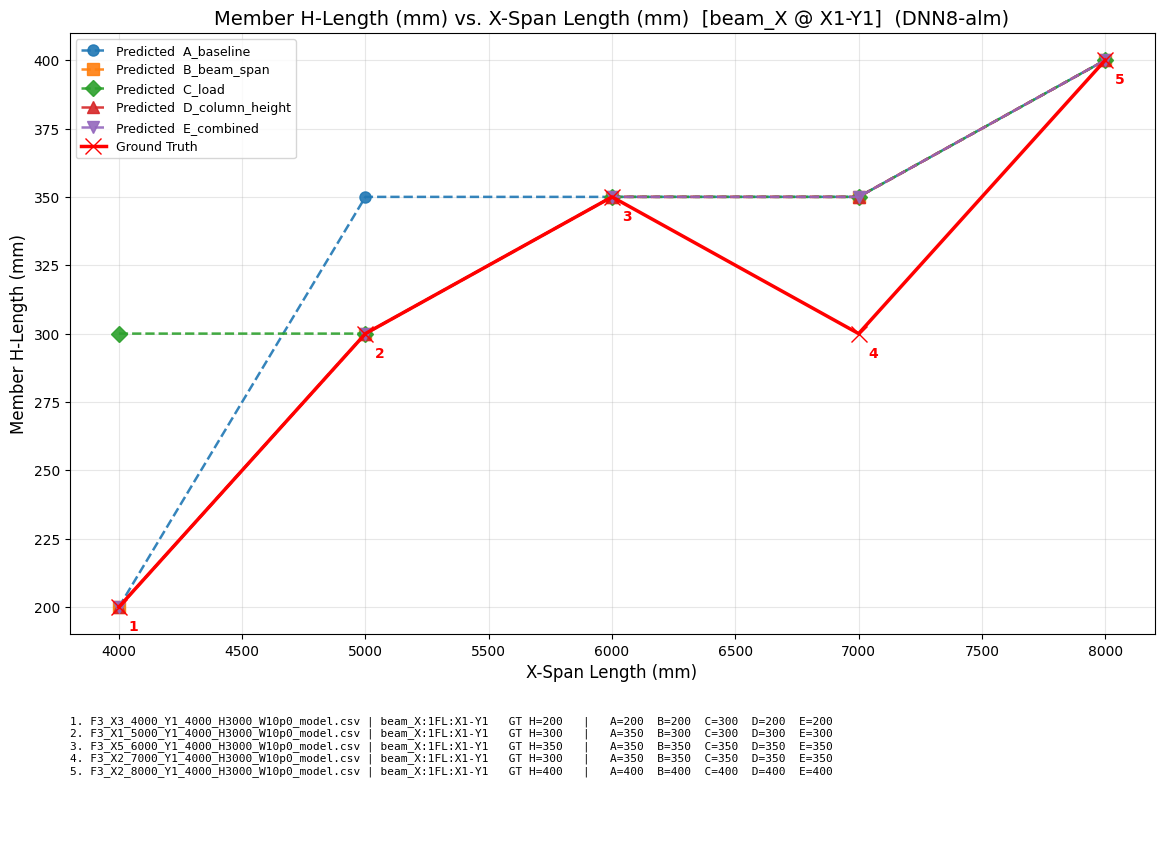

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-beam_X-H-vs-X_Span_Length-X1-Y1.png
Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-beam_X-H-vs-X_Span_Length-X1-Y1.csv
Building condition key: F3_XSPAN_Y1_4000_H3000_W10p0_model.csv | beam_X:1FL:X1-Y1
Distinct values plotted (x_span): [4000, 5000, 6000, 7000, 8000]


In [11]:
summary_1 = plot_dim_vs_variable(DF, member='beam_X', dim='H', vary='x_span', position='X1-Y1')

### Beam H vs. X-span (X2-Y2)

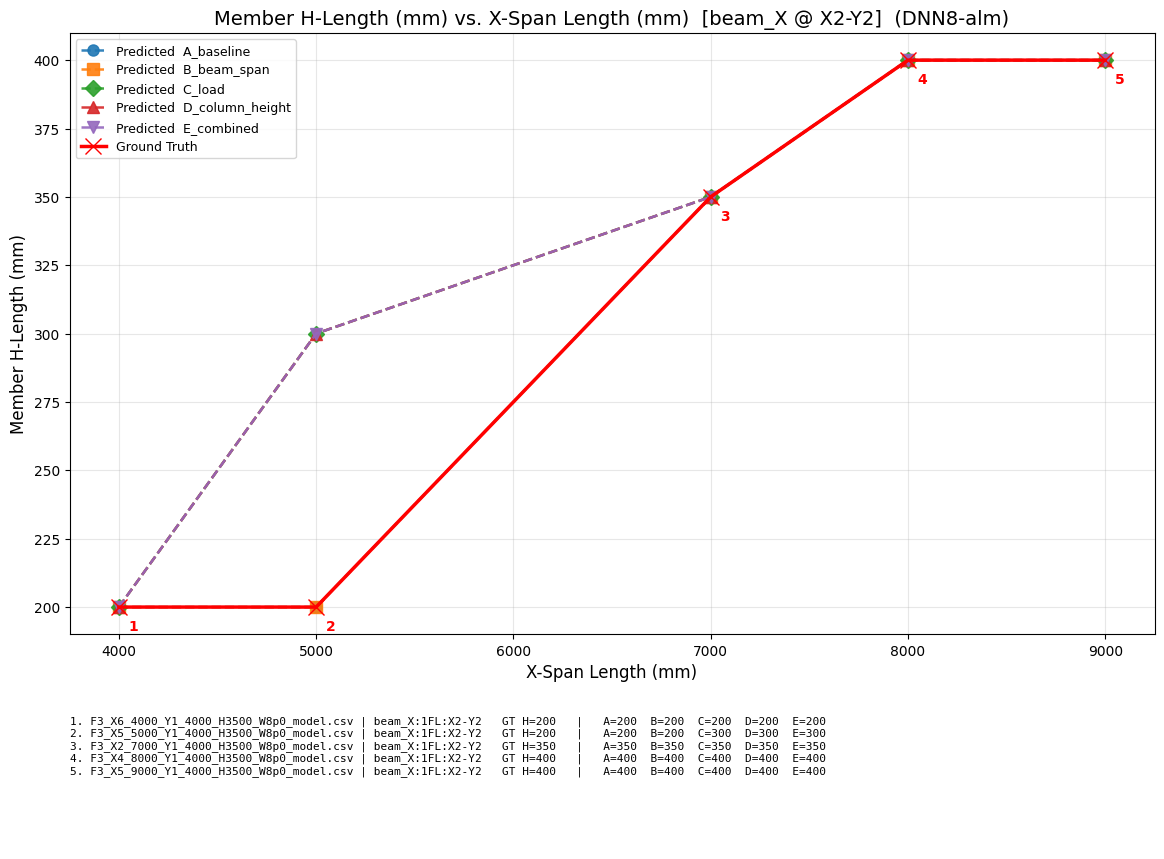

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-beam_X-H-vs-X_Span_Length-X2-Y2.png
Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-beam_X-H-vs-X_Span_Length-X2-Y2.csv
Building condition key: F3_XSPAN_Y1_4000_H3500_W8p0_model.csv | beam_X:1FL:X2-Y2
Distinct values plotted (x_span): [4000, 5000, 7000, 8000, 9000]


In [12]:
summary_1_2 = plot_dim_vs_variable(DF, member='beam_X', dim='H', vary='x_span', position='X2-Y2')

### Beam H vs. building load

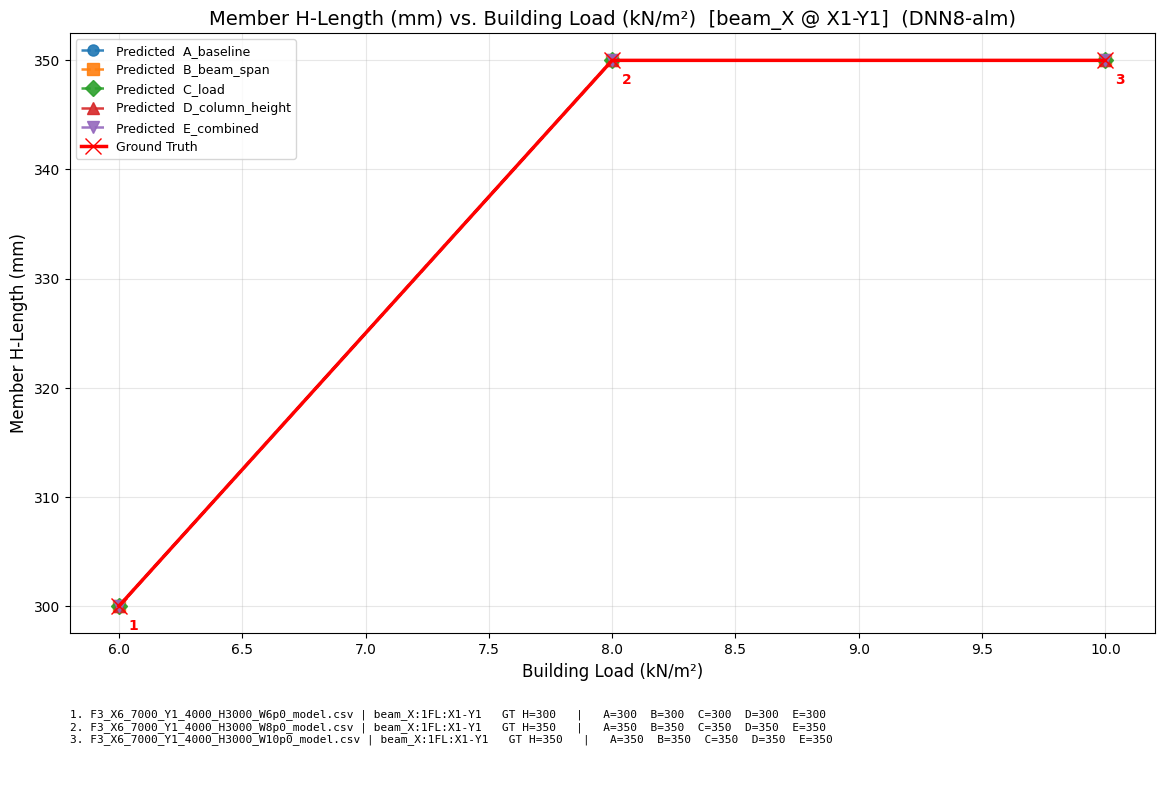

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-beam_X-H-vs-Building_Load-X1-Y1.png
Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-beam_X-H-vs-Building_Load-X1-Y1.csv
Building condition key: F3_X6_7000_Y1_4000_H3000_WLOAD_model.csv | beam_X:1FL:X1-Y1
Distinct values plotted (load): [6.0, 8.0, 10.0]


In [13]:
summary_2 = plot_dim_vs_variable(DF, member='beam_X', dim='H', vary='load', position='X1-Y1')

### Column D vs. building load

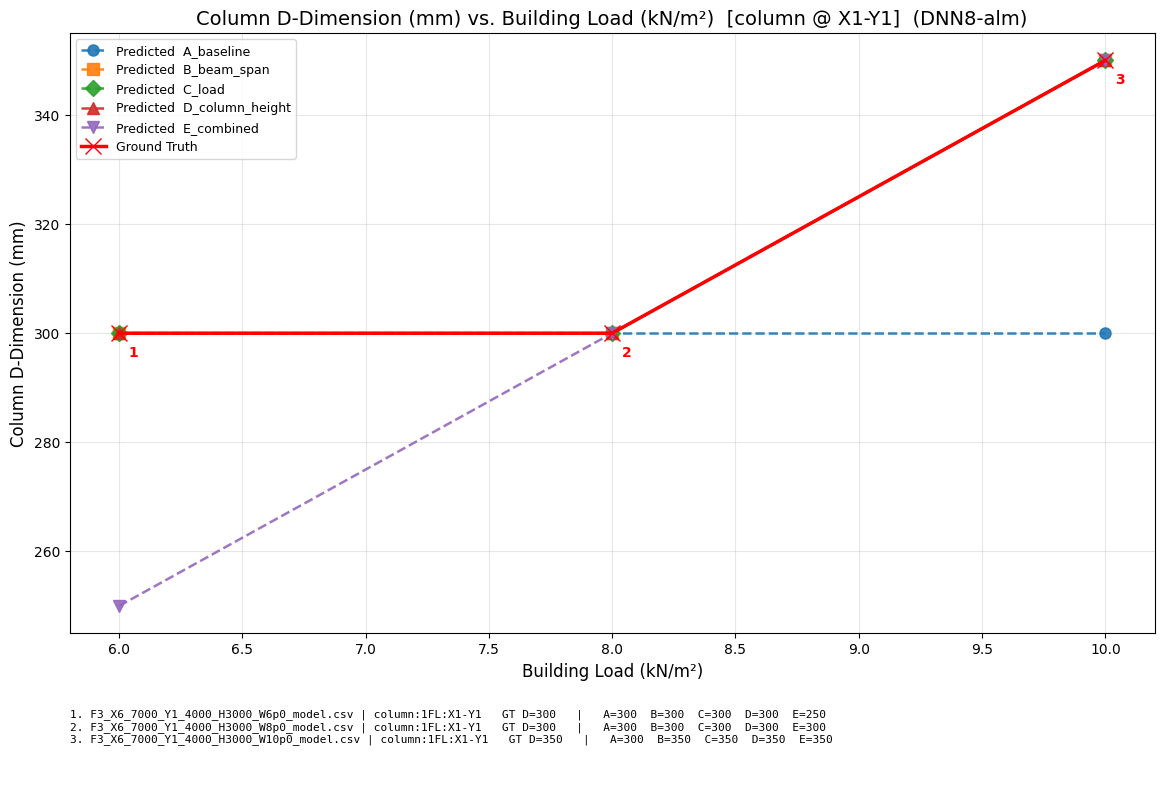

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-column-D-vs-Building_Load-X1-Y1.png
Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-column-D-vs-Building_Load-X1-Y1.csv
Building condition key: F3_X6_7000_Y1_4000_H3000_WLOAD_model.csv | column:1FL:X1-Y1
Distinct values plotted (load): [6.0, 8.0, 10.0]


In [14]:
summary_3 = plot_dim_vs_variable(DF, member='column', dim='D', vary='load', position='X1-Y1')

### Column D vs. floor

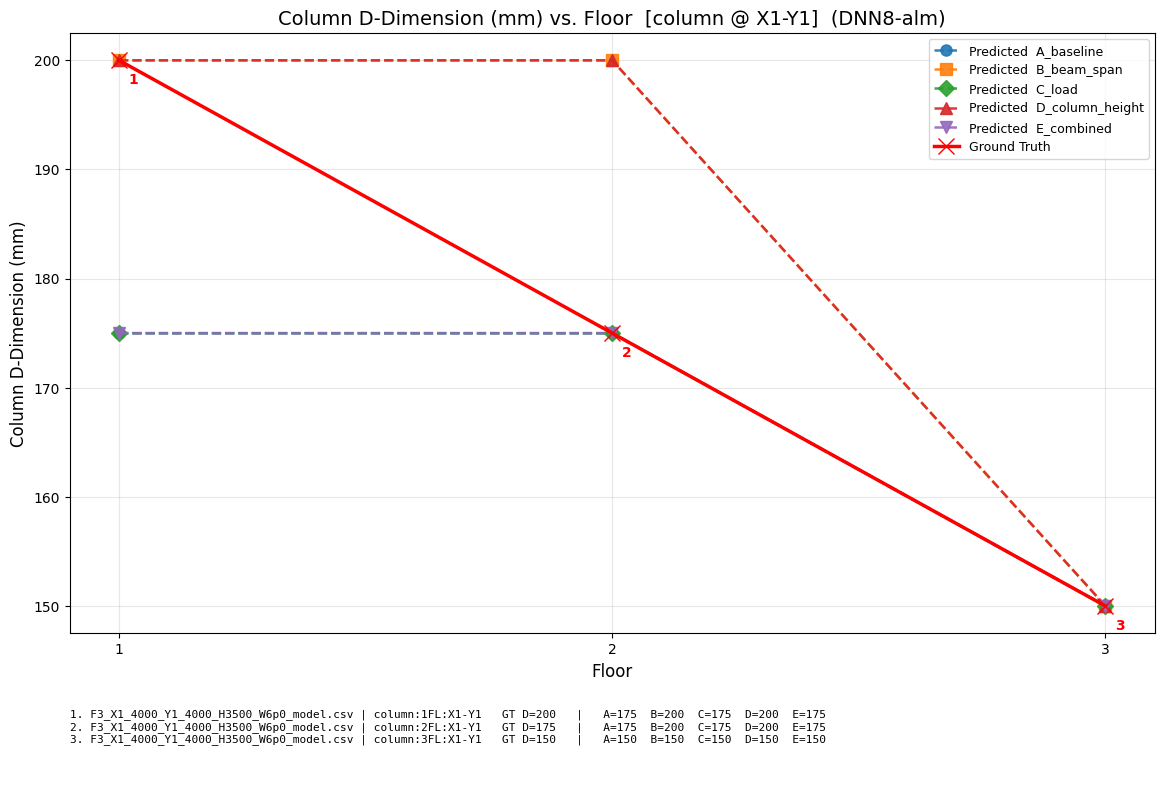

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-column-D-vs-Floor-X1-Y1.png
Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-column-D-vs-Floor-X1-Y1.csv
Building condition key: F3_X1_4000_Y1_4000_H3500_W6p0_model.csv | column:FL:X1-Y1
Distinct values plotted (story): [1, 2, 3]


In [15]:
summary_4 = plot_dim_vs_variable(DF, member='column', dim='D', vary='story', position='X1-Y1')

### Beam H vs. floor height

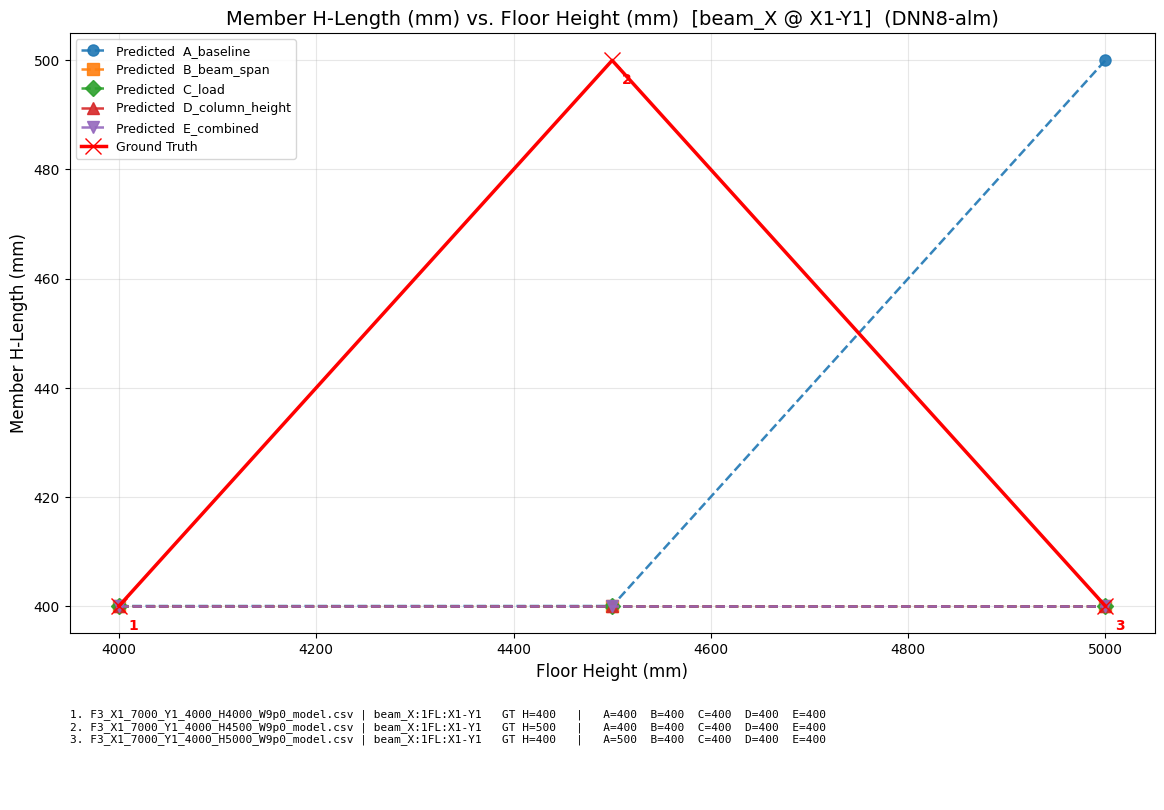

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-beam_X-H-vs-Floor_Height-X1-Y1.png
Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-beam_X-H-vs-Floor_Height-X1-Y1.csv
Building condition key: F3_X1_7000_Y1_4000_HFLOOR_W9p0_model.csv | beam_X:1FL:X1-Y1
Distinct values plotted (floor_height): [4000, 4500, 5000]


In [16]:
summary_5 = plot_dim_vs_variable(DF, member='beam_X', dim='H', vary='floor_height', position='X1-Y1')

### Column D vs. floor height

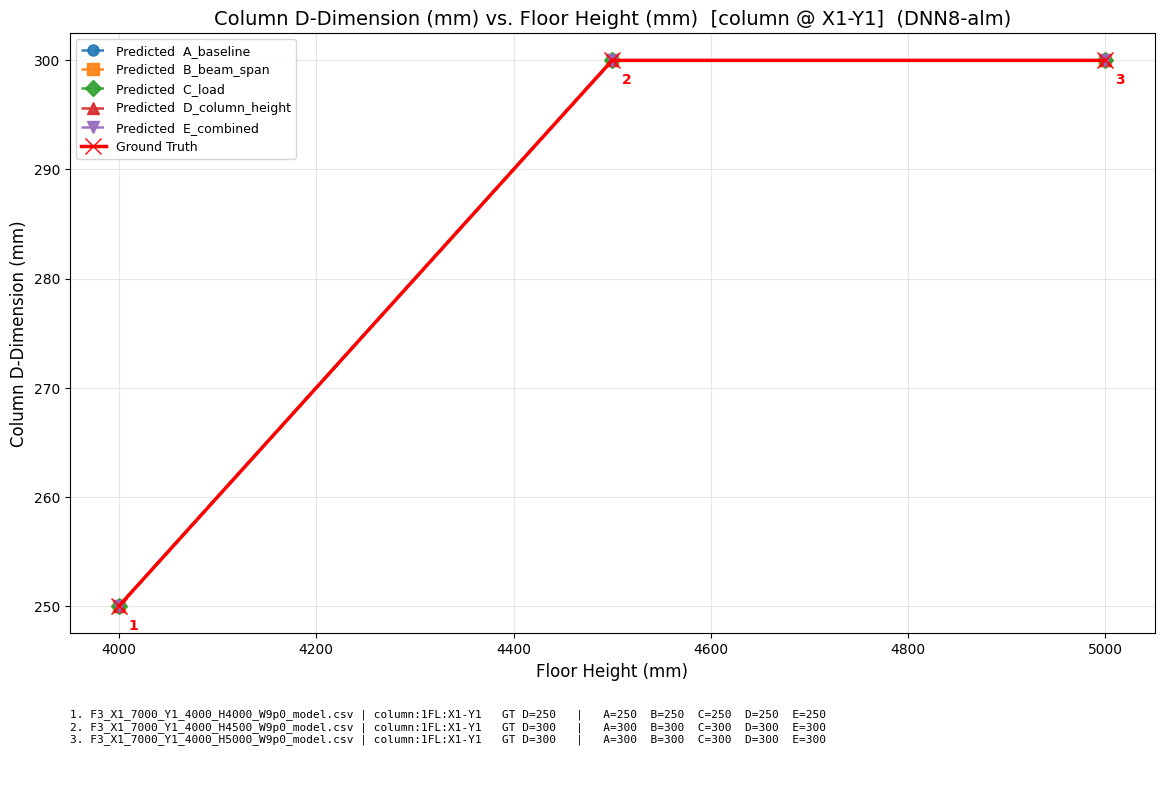

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/DNN8-alm-column-D-vs-Floor_Height-X1-Y1.png
Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/DNN8-alm-column-D-vs-Floor_Height-X1-Y1.csv
Building condition key: F3_X1_7000_Y1_4000_HFLOOR_W9p0_model.csv | column:1FL:X1-Y1
Distinct values plotted (floor_height): [4000, 4500, 5000]


In [17]:
summary_6 = plot_dim_vs_variable(DF, member='column', dim='D', vary='floor_height', position='X1-Y1')

# Part 2 — Validity of the training / validation / test datasets

The cells below re-read the original building CSVs (`dataset/train|val|test`) with the same parser as the training notebook.
The first run parses every file (a cache is stored in `analysis/dataset-audit-cache.pkl`; set `FORCE_REPARSE = True` after changing the data).
Only buildings that the DNN notebook would actually use (no disabled / unknown sections) enter the statistics.

In [18]:
# ============================================================
# Dataset parser  (same logic as the training notebook, plus: reported total weight and the bracing length Lb)
# ============================================================
def read_rows(path):
    """Read a CSV into a list of rows. Handles UTF-8 (with BOM) and Shift-JIS."""
    for enc in ("utf-8-sig", "cp932"):
        try:
            with open(path, encoding=enc, newline="") as f:
                return list(csv.reader(f))
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Cannot decode {path}")

def norm_name(s):
    s = s.strip().replace("×", "x").replace("－", "-").replace(" ", "").lower()
    return re.sub(r"^[^\-]*-", "", s)

class DisabledSectionError(KeyError):
    pass

class Catalog:
    """Enabled catalogue rows = DNN output classes (class index k = row k of the enabled catalogue)."""
    def __init__(self, path, size_col):
        for enc in ("utf-8-sig", "cp932"):
            try:
                df_all = pd.read_csv(path, encoding=enc); break
            except UnicodeDecodeError:
                continue
        self.df = df_all[df_all["enabled"].astype(int) == 1].reset_index(drop=True)
        self.disabled_keys = {norm_name(n) for n in df_all.loc[df_all["enabled"].astype(int) != 1, "name"].astype(str)}
        self.n, self.ids = len(self.df), self.df["id"].to_numpy(dtype=int)
        self.names = self.df["name"].astype(str).to_numpy()
        self.mass = self.df["mass_kg_m"].to_numpy(dtype=float)
        self.size = self.df[size_col].to_numpy(dtype=float)
        self.key2idx = {norm_name(n): k for k, n in enumerate(self.names)}
    def index_of(self, name):
        key = norm_name(name)
        if key not in self.key2idx:
            if key in self.disabled_keys:
                raise DisabledSectionError(f"Section '{name}' is disabled (enabled=0)")
            raise KeyError(f"Section '{name}' is not in the catalog")
        return self.key2idx[key]

cat_col = Catalog(CATALOG_ROOT / BOX_CATALOG_FILE, "D_mm")
cat_beam = Catalog(CATALOG_ROOT / H_CATALOG_FILE, "H_mm")
print(f"Column catalog: {cat_col.n} enabled sections | Beam catalog: {cat_beam.n} enabled sections")

def parse_sections(rows):
    secs, cur = {}, None
    for row in rows:
        if row and row[0].startswith("name="):
            cur = row[0][len("name="):].strip(); secs.setdefault(cur, [])
        elif cur is not None:
            if not any(c.strip() for c in row): cur = None
            else: secs[cur].append(row)
    return secs

def table(sec_rows):
    for k, r in enumerate(sec_rows):
        if r and r[0].strip() == "<data>":
            return sec_rows[k - 1], sec_rows[k + 1:]
    return sec_rows[0], sec_rows[1:]

def story_of_column_label(label):
    m = re.match(r"(\d+)", label.strip())
    if not m: raise ValueError(f"Unknown column floor label: {label}")
    return int(m.group(1))

def story_of_beam_label(label, n_floors):
    label = label.strip()
    if label.upper().startswith("R"): return n_floors
    m = re.match(r"(\d+)", label)
    if not m: raise ValueError(f"Unknown beam layer label: {label}")
    return int(m.group(1)) - 1

def parse_plan(plan_rows):
    x_cols, col_sym, xb_sym, yb_sym, pending = {}, {}, {}, {}, []
    for row in plan_rows:
        cells = [c.strip() for c in row]
        if cells[0] == "通り":
            x_cols = {p: int(c[1:]) - 1 for p, c in enumerate(cells) if re.fullmatch(r"X\d+", c)}
            continue
        m = re.fullmatch(r"Y(\d+)", cells[0])
        if m and x_cols:
            j = int(m.group(1)) - 1
            for p, c in enumerate(cells):
                mc = re.search(r"●\s*([^\s─│●]+)", c)
                if mc and p in x_cols: col_sym[(j, x_cols[p])] = mc.group(1)
                mb = re.search(r"─+\s*([^\s─│●]+)\s*─+", c)
                if mb:
                    left = max(xi for q, xi in x_cols.items() if q < p)
                    xb_sym[(j, left)] = mb.group(1)
            for p, sym in pending: yb_sym[(j, x_cols[p])] = sym
            pending = []
        elif x_cols and cells[0] == "" and any("│" in c for c in cells):
            for p, c in enumerate(cells):
                mb = re.search(r"│\s*([^\s─│●]+)", c)
                if mb: pending.append((p, mb.group(1)))
    return col_sym, xb_sym, yb_sym

def parse_member_table(sec_rows, story_fn):
    hdr, data = table(sec_rows); syms = [h.strip() for h in hdr[1:]]; out = {}
    for row in data:
        if not row or not row[0].strip(): continue
        story = story_fn(row[0])
        for s, v in zip(syms, row[1:]):
            if s and v.strip(): out[(story, s)] = v.strip()
    return out

def find_col(hdr, key):
    for k, h in enumerate(hdr):
        if key in h: return k
    raise KeyError(f"Header '{key}' not found in {hdr}")

def parse_building(path):
    rows = read_rows(path); secs = parse_sections(rows)
    for key in ("平面図（全階共通）", "建物条件", "スパン割", "階高"):
        if key not in secs: raise ValueError(f"Block 'name={key}' missing")
    hdr, data = table(secs["建物条件"]); d = data[0]
    n_floors = int(float(d[find_col(hdr, "階数")])); nx = int(float(d[find_col(hdr, "Xスパン数")]))
    ny = int(float(d[find_col(hdr, "Yスパン数")])); load = float(d[find_col(hdr, "鉛直面荷重")])
    try:                                                     # bracing length Lb: not an input of the DNN (checked below)
        lb = float(d[find_col(hdr, "Lb")])
    except (KeyError, ValueError, IndexError):
        lb = np.nan
    hdr, data = table(secs["スパン割"])
    span_cols = [k for k, h in enumerate(hdr) if h.strip().startswith("スパン")]; spans = {}
    for row in data:
        if row[0].strip() in ("X", "Y"):
            spans[row[0].strip()] = [float(row[k]) for k in span_cols if k < len(row) and row[k].strip()]
    x_spans, y_spans = spans["X"], spans["Y"]
    if len(x_spans) != nx or len(y_spans) != ny: raise ValueError("span count does not match the building conditions")
    hdr, data = table(secs["階高"])
    heights = {story_of_column_label(r[0]): float(r[1]) for r in data if r and r[0].strip()}
    for s in range(1, n_floors + 1):
        if s not in heights: raise ValueError(f"story height of story {s} missing")
    col_sym, xb_sym, yb_sym = parse_plan(secs["平面図（全階共通）"])
    if "柱断面リスト" not in secs or "梁断面リスト" not in secs: raise ValueError("teacher section lists missing")
    w_rep = np.nan                                           # reported total steel weight (header row 総鋼材重量)
    for r in rows[:6]:
        if r and "総鋼材重量" in r[0]:
            try: w_rep = float(r[1])
            except (ValueError, IndexError): pass
    return dict(path=path, n_floors=n_floors, nx=nx, ny=ny, load=load, lb=lb, w_reported=w_rep,
                x_spans=x_spans, y_spans=y_spans, heights=heights, col_sym=col_sym, xb_sym=xb_sym, yb_sym=yb_sym,
                col_names=parse_member_table(secs["柱断面リスト"], story_of_column_label),
                beam_names=parse_member_table(secs["梁断面リスト"], lambda l: story_of_beam_label(l, n_floors)))

def label_arrays(b, spec):
    """Catalogue class index (-1 = no member) and dimension (NaN = no member) of every grid position."""
    F, NY, NX = spec
    ck, bk = -np.ones((F, NY, NX), int), -np.ones((F, NY, NX, 2), int)
    for f in range(b["n_floors"]):
        for (j, i), s in b["col_sym"].items():
            ck[f, j, i] = cat_col.index_of(b["col_names"][(f + 1, s)])
        for (j, i), s in b["xb_sym"].items():
            if i < b["nx"]: bk[f, j, i, 0] = cat_beam.index_of(b["beam_names"][(f + 1, s)])
        for (j, i), s in b["yb_sym"].items():
            if j < b["ny"]: bk[f, j, i, 1] = cat_beam.index_of(b["beam_names"][(f + 1, s)])
    colD = np.where(ck >= 0, cat_col.size[np.maximum(ck, 0)], np.nan)
    beamH = np.where(bk >= 0, cat_beam.size[np.maximum(bk, 0)], np.nan)
    return ck, bk, colD, beamH

Column catalog: 63 enabled sections | Beam catalog: 27 enabled sections


## Load the dataset

In [19]:
# ============================================================
# Parse train / val / test and build the dataset tables  (cached; set FORCE_REPARSE = True after changing the data)
# ============================================================
import pickle, time
FORCE_REPARSE = False
CACHE = OUTPUT_DIR / 'dataset-audit-cache.pkl'

file_list = {s: sorted(glob.glob(str(DATASET_ROOT / s / '*.csv'))) for s in SPLITS}
fingerprint = {s: [(os.path.basename(p), os.path.getsize(p)) for p in ps] for s, ps in file_list.items()}
for s in SPLITS:
    if not file_list[s]: raise FileNotFoundError(f'No CSV files in {DATASET_ROOT / s}')

def _progress(it, desc):
    try:
        from tqdm.auto import tqdm
        return tqdm(it, desc=desc)
    except ImportError:
        return it

if CACHE.is_file() and not FORCE_REPARSE:
    cached = pickle.load(open(CACHE, 'rb'))
    if cached['fingerprint'] == fingerprint:
        parsed, errors = cached['parsed'], cached['errors']; print('Loaded parsed dataset from cache:', CACHE.name)
    else:
        cached = None
else:
    cached = None
if cached is None:
    parsed, errors = {s: [] for s in SPLITS}, []
    t0 = time.time()
    for s in SPLITS:
        for p in _progress(file_list[s], f'parsing {s}'):
            try:
                parsed[s].append(parse_building(p))
            except Exception as e:
                errors.append(dict(split=s, file=os.path.basename(p), status='parse_error', reason=str(e)[:150]))
    pickle.dump(dict(fingerprint=fingerprint, parsed=parsed, errors=errors), open(CACHE, 'wb'))
    print(f'Parsed in {time.time() - t0:.0f} s')

all_b = [b for s in SPLITS for b in parsed[s]]
SPEC = (max(b['n_floors'] for b in all_b), max(b['ny'] for b in all_b) + 1, max(b['nx'] for b in all_b) + 1)
print('Grid spec (F, NY, NX) =', SPEC, '(largest building over all splits; smaller buildings are zero-padded)')

# ---- ranges the DNN input normalisation was designed for (same constants as the training notebook) -------------
RANGES = dict(n_floors=(1, 5), nx=(1, 6), ny=(1, 6), span=(4000.0, 9000.0), height=(3000.0, 5000.0), load=(6.0, 10.0))

# ---- one record per building, plus the label grids ----------------------------------
BLD, rec = [], []
for s in SPLITS:
    for b in parsed[s]:
        name = os.path.basename(b['path']); status, reason = 'used', ''
        try:
            ck, bk, colD, beamH = label_arrays(b, SPEC)
        except DisabledSectionError as e:
            status, reason = 'skipped_disabled_section', str(e)[:150]
        except Exception as e:
            status, reason = 'label_error', f'{type(e).__name__}: {e}'[:150]
        F = b['n_floors']; hs = tuple(b['heights'][k] for k in range(1, F + 1))
        xs, ys = tuple(b['x_spans']), tuple(b['y_spans'])
        area = sum(xs) * sum(ys) / 1e6 * F
        r = dict(split=s, file=name, status=status, reason=reason, n_floors=F, nx=b['nx'], ny=b['ny'],
                 x_span_mean=np.mean(xs), x_span_min=min(xs), x_span_max=max(xs), y_span_mean=np.mean(ys),
                 y_span_min=min(ys), y_span_max=max(ys), height_mean=np.mean(hs), height_min=min(hs), height_max=max(hs),
                 load=b['load'], Lb=b['lb'], w_reported=b['w_reported'], floor_area_m2=area,
                 sig=repr((F, b['nx'], b['ny'], xs, ys, hs, b['load'])))
        if status == 'used':
            r.update(n_columns=int((ck >= 0).sum()), n_beam_x=int((bk[..., 0] >= 0).sum()), n_beam_y=int((bk[..., 1] >= 0).sum()))
            r['n_members'] = r['n_columns'] + r['n_beam_x'] + r['n_beam_y']
            wc = sum(cat_col.mass[ck[f, j, i]] * hs[f] / 1000 for f, j, i in np.argwhere(ck >= 0))
            wb = sum(cat_beam.mass[bk[f, j, i, 0]] * xs[i] / 1000 for f, j, i in np.argwhere(bk[..., 0] >= 0)) + \
                 sum(cat_beam.mass[bk[f, j, i, 1]] * ys[j] / 1000 for f, j, i in np.argwhere(bk[..., 1] >= 0))
            r['w_recalc'] = wc + wb
            BLD.append(dict(idx=len(rec), split=s, b=b, ck=ck, bk=bk, colD=colD, beamH=beamH, hs=hs))
        rec.append(r)
bdf = pd.DataFrame(rec)
bdf['used'] = bdf['status'].eq('used')
if errors:
    err_df_ds = pd.DataFrame(errors); print(f'{len(err_df_ds)} file(s) could not be parsed:'); display(err_df_ds.head(20))
UB = bdf[bdf['used']].rename_axis('bidx').reset_index()   # buildings that actually reach the DNN (bidx = row in bdf)
UB['w_per_area'] = UB['w_reported'] / UB['floor_area_m2']
print(UB.groupby('split').size().to_dict(), '<- buildings used by the DNN')

# ---- long member table (one row per column / beam) -----------------------------------
mem = []
for it in BLD:
    b, f_idx = it['b'], it['idx']
    for f, j, i in np.argwhere(it['ck'] >= 0):
        mem.append((it['split'], f_idx, 'column', f + 1, i + 1, j + 1, it['ck'][f, j, i], it['colD'][f, j, i], it['hs'][f], 0.0))
    for a, kind in enumerate(('beam_X', 'beam_Y')):
        for f, j, i in np.argwhere(it['bk'][..., a] >= 0):
            L = b['x_spans'][i] if a == 0 else b['y_spans'][j]
            mem.append((it['split'], f_idx, kind, f + 1, i + 1, j + 1, it['bk'][f, j, i, a], it['beamH'][f, j, i, a], it['hs'][f], L))
MEM = pd.DataFrame(mem, columns=['split', 'bidx', 'member', 'story', 'x_line', 'y_line', 'k', 'size_mm', 'story_height', 'span'])
MEM['kind'] = np.where(MEM['member'].eq('column'), 'column', 'beam')
MEM = MEM.merge(bdf[['load', 'n_floors', 'nx', 'ny']], left_on='bidx', right_index=True)
print(f'{len(MEM):,} labelled members;', MEM.groupby(['split', 'kind']).size().unstack().to_dict('index'))

parsing train:   0%|          | 0/720 [00:00<?, ?it/s]

parsing val:   0%|          | 0/90 [00:00<?, ?it/s]

parsing test:   0%|          | 0/90 [00:00<?, ?it/s]

Parsed in 82 s
Grid spec (F, NY, NX) = (3, 2, 7) (largest building over all splits; smaller buildings are zero-padded)
{'test': 90, 'train': 720, 'val': 90} <- buildings used by the DNN
55,350 labelled members; {'test': {'beam': 3006, 'column': 2364}, 'train': {'beam': 24714, 'column': 19356}, 'val': {'beam': 3330, 'column': 2580}}


## DS-1/2  Split sizes and parameter ranges

Grid capacity per building (F x NY x NX x [column + 2 beams]) = 126 slots; mean occupancy of used buildings = 48.8%  (the rest is zero padding / masked in the loss)


,files_found,parse_errors,skipped_disabled_section,skipped_label_error,buildings_used,columns,beams_X,beams_Y,members_total,members_per_building,share_of_buildings_%,share_of_members_%
split,,,,,,,,,,,,
train,720.0,0.0,0.0,0.0,720.0,19356.0,15036.0,9678.0,44070.0,61.21,80.0,79.62
val,90.0,0.0,0.0,0.0,90.0,2580.0,2040.0,1290.0,5910.0,65.67,10.0,10.68
test,90.0,0.0,0.0,0.0,90.0,2364.0,1824.0,1182.0,5370.0,59.67,10.0,9.70
total,900.0,0.0,0.0,0.0,900.0,24300.0,18900.0,12150.0,55350.0,61.50,100.0,100.00


Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/dataset-1-split-overview.csv


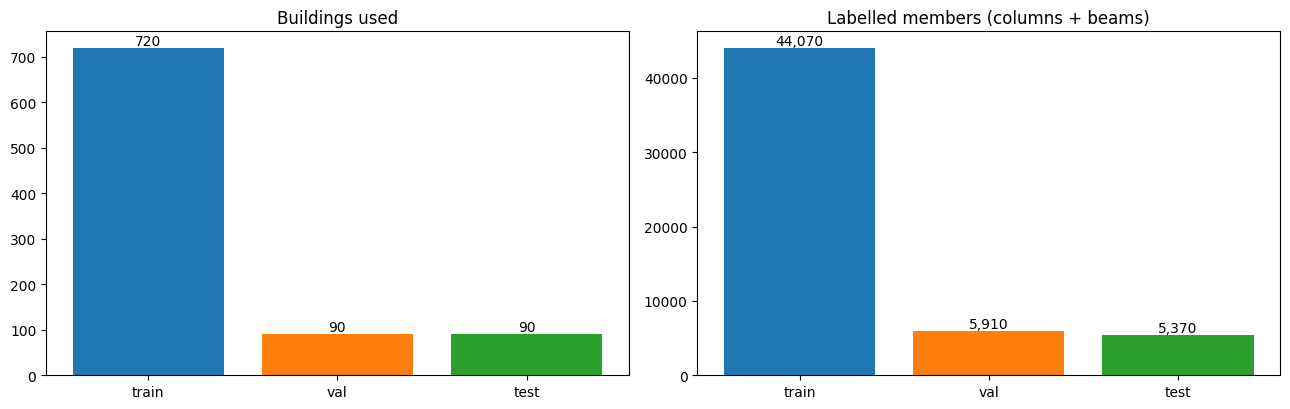

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/dataset-1-split-sizes.png
Ranges per split.  inside_norm_range=False would break the DNN input normalisation; inside_train_range=False means the split asks the DNN to EXTRAPOLATE.


min     max  n_unique norm_range  inside_norm_range  \
parameter  split                                                           
n_floors   train     3.0     3.0         1        1-5               True   
           val       3.0     3.0         1        1-5               True   
           test      3.0     3.0         1        1-5               True   
nx         train     1.0     6.0         6        1-6               True   
           val       1.0     6.0         6        1-6               True   
           test      1.0     6.0         6        1-6               True   
ny         train     1.0     1.0         1        1-6               True   
           val       1.0     1.0         1        1-6               True   
           test      1.0     1.0         1        1-6               True   
x_span_min train  4000.0  9000.0         6  4000-9000               True   
           val    4000.0  9000.0         6  4000-9000               True   
           test   4000.0  9000.0         6  4000-9000               True   
x_span_max train  4000.0  9000.0         6  4000-9000               True   
           val    4000.0  9000.0         6  4000-9000               True   
           test   4000.0  9000.0         6  4000-9000               True   
y_span_min train  4000.0  4000.0         1  4000-9000               True   
           val    4000.0  4000.0         1  4000-9000               True   
           test   4000.0  4000.0         1  4000-9000               True   
y_span_max train  4000.0  4000.0         1  4000-9000               True   
           val    4000.0  4000.0         1  4000-9000               True   
           test   4000.0  4000.0         1  4000-9000               True   
height_min train  3000.0  5000.0         5  3000-5000               True   
           val    3000.0  5000.0         5  3000-5000               True   
           test   3000.0  5000.0         5  3000-5000               True   
height_max train  3000.0  5000.0         5  3000-5000               True   
           val    3000.0  5000.0         5  3000-5000               True   
           test   3000.0  5000.0         5  3000-5000               True   
load       train     6.0    10.0         5       6-10               True   
           val       6.0    10.0         5       6-10               True   
           test      6.0    10.0         5       6-10               True   

                  inside_train_range  n_buildings_outside_train_range  
parameter  split                                                       
n_floors   train                True                                0  
           val                  True                                0  
           test                 True                                0  
nx         train                True                                0  
           val                  True                                0  
           test                 True                                0  
ny         train                True                                0  
           val                  True                                0  
           test                 True                                0  
x_span_min train                True                                0  
           val                  True                                0  
           test                 True                                0  
x_span_max train                True                                0  
           val                  True                                0  
           test                 True                                0  
y_span_min train                True                                0  
           val                  True                                0  
           test                 True                                0  
y_span_max train                True                                0  
           val                  True                                0  
    

Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/dataset-2-parameter-ranges.csv


PosixPath('/content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/dataset-2-parameter-ranges.csv')

In [20]:
# ============================================================
# DS-1  Split overview: size, usable fraction, members
# ============================================================
rows = []
for s in SPLITS:
    a, u = bdf[bdf['split'] == s], UB[UB['split'] == s]
    m = MEM[MEM['split'] == s]
    rows.append({'split': s, 'files_found': len(file_list[s]), 'parse_errors': int(sum(e['split'] == s for e in errors)),
                 'skipped_disabled_section': int((a['status'] == 'skipped_disabled_section').sum()),
                 'skipped_label_error': int((a['status'] == 'label_error').sum()), 'buildings_used': len(u),
                 'columns': int((m['member'] == 'column').sum()), 'beams_X': int((m['member'] == 'beam_X').sum()),
                 'beams_Y': int((m['member'] == 'beam_Y').sum()), 'members_total': len(m),
                 'members_per_building': len(m) / max(len(u), 1)})
ov = pd.DataFrame(rows).set_index('split')
ov.loc['total'] = ov.sum(numeric_only=True); ov.loc['total', 'members_per_building'] = ov.loc['total', 'members_total'] / ov.loc['total', 'buildings_used']
ov['share_of_buildings_%'] = ov['buildings_used'] / ov.loc['total', 'buildings_used'] * 100
ov['share_of_members_%'] = ov['members_total'] / ov.loc['total', 'members_total'] * 100
cap = SPEC[0] * SPEC[1] * SPEC[2] * 3
print(f'Grid capacity per building (F x NY x NX x [column + 2 beams]) = {cap} slots; mean occupancy of used buildings = '
      f'{UB[["n_members"]].mean().iloc[0] / cap:.1%}  (the rest is zero padding / masked in the loss)')
save_table(ov.round(2), 'dataset-1-split-overview.csv')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].bar(SPLITS, [ov.loc[s, 'buildings_used'] for s in SPLITS], color=['tab:blue', 'tab:orange', 'tab:green'])
ax[1].bar(SPLITS, [ov.loc[s, 'members_total'] for s in SPLITS], color=['tab:blue', 'tab:orange', 'tab:green'])
for a, t in zip(ax, ('Buildings used', 'Labelled members (columns + beams)')):
    a.set_title(t)
    for p in a.patches: a.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
plt.tight_layout(); save_fig(fig, 'dataset-1-split-sizes.png')

# ============================================================
# DS-2  Parameter ranges per split vs. the normalisation range and vs. the training range
# ============================================================
P = [('n_floors', 'n_floors', 'n_floors'), ('nx', 'nx', 'nx'), ('ny', 'ny', 'ny'), ('x_span_min', 'span', 'x_span_min'),
     ('x_span_max', 'span', 'x_span_max'), ('y_span_min', 'span', 'y_span_min'), ('y_span_max', 'span', 'y_span_max'),
     ('height_min', 'height', 'height_min'), ('height_max', 'height', 'height_max'), ('load', 'load', 'load')]
rows = []
for col, rk, _ in P:
    lo, hi = RANGES[rk]; tr = UB[UB['split'] == 'train'][col]
    for s in SPLITS:
        v = UB[UB['split'] == s][col]
        rows.append(dict(parameter=col, split=s, min=v.min(), max=v.max(), n_unique=v.nunique(),
                         norm_range=f'{lo:g}-{hi:g}', inside_norm_range=bool(v.min() >= lo and v.max() <= hi),
                         inside_train_range=bool(v.min() >= tr.min() and v.max() <= tr.max()),
                         n_buildings_outside_train_range=int(((v < tr.min()) | (v > tr.max())).sum())))
rng_df = pd.DataFrame(rows)
print('Ranges per split.  inside_norm_range=False would break the DNN input normalisation; '
      'inside_train_range=False means the split asks the DNN to EXTRAPOLATE.')
save_table(rng_df.set_index(['parameter', 'split']), 'dataset-2-parameter-ranges.csv')

## DS-3/4  Distributions and coverage of parameter combinations

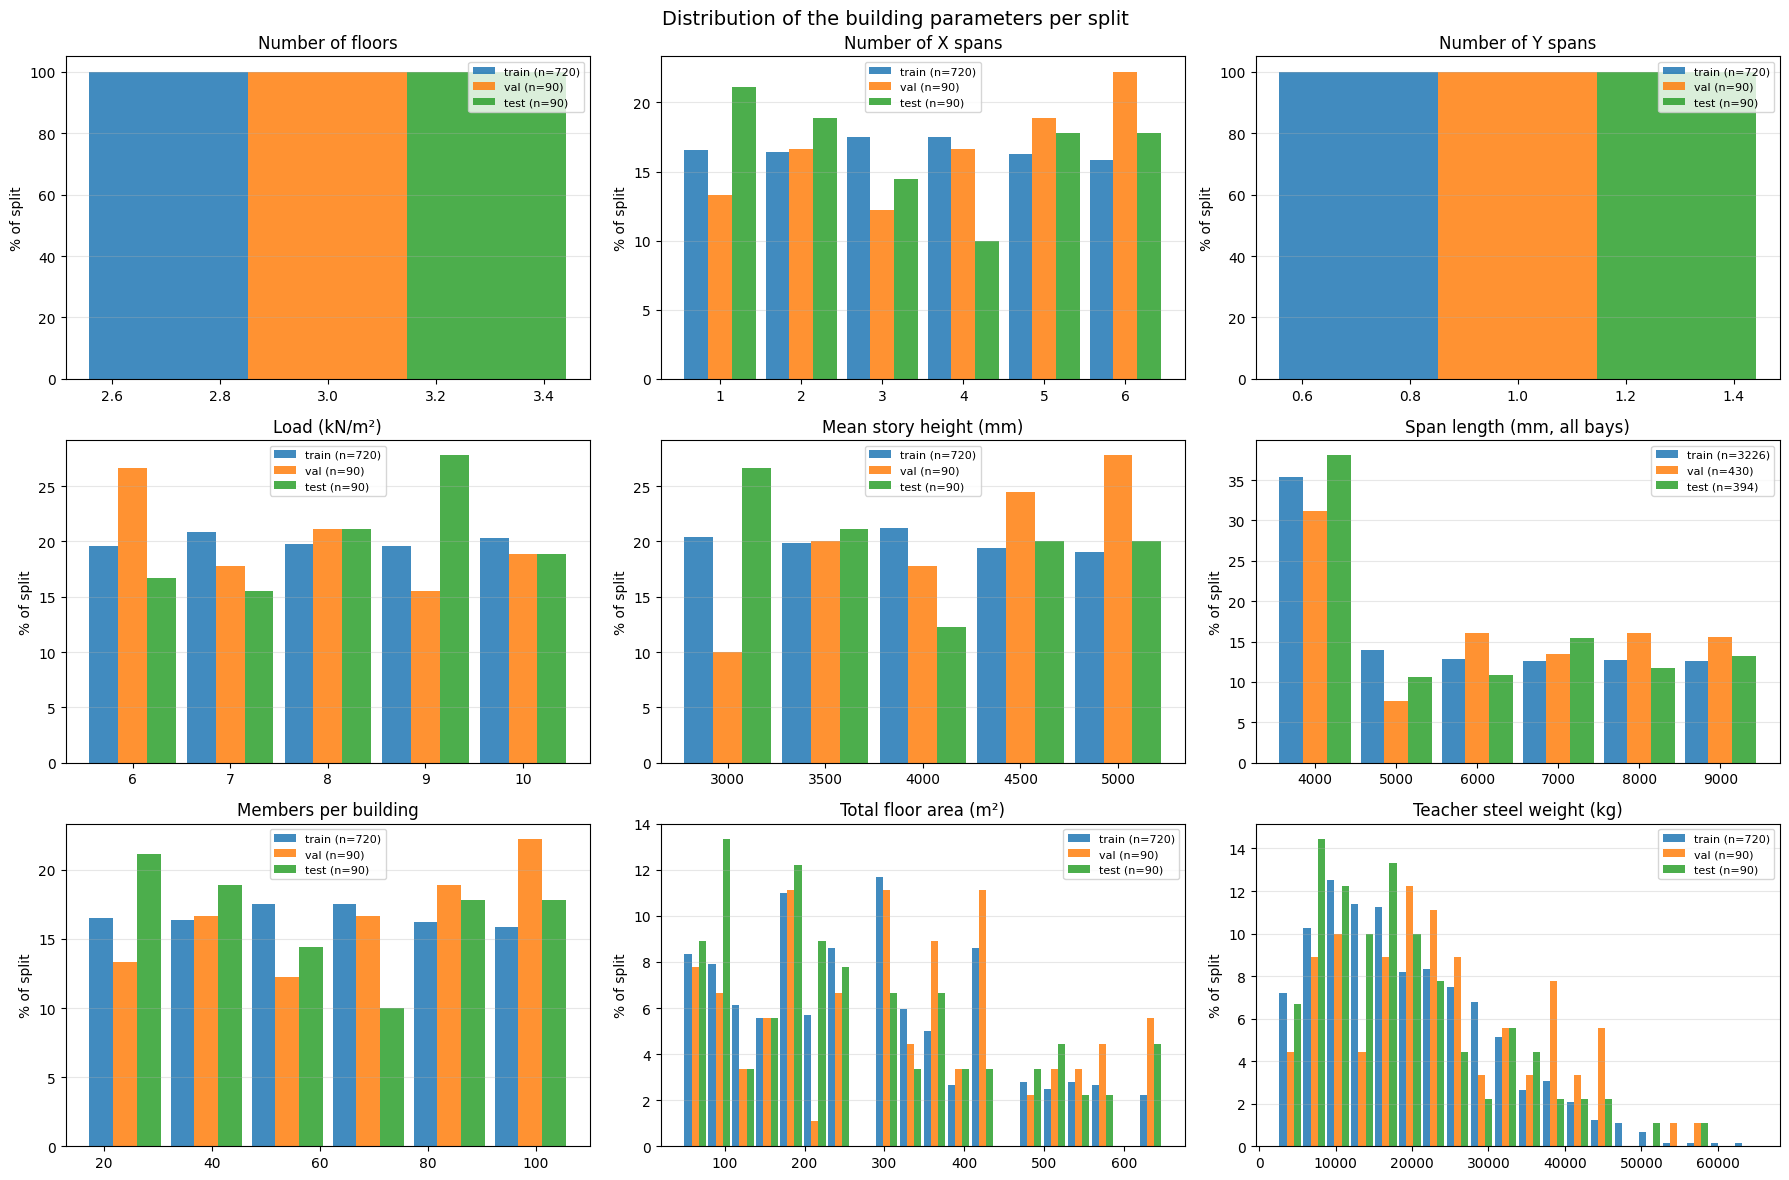

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/dataset-3-parameter-distributions.png
JS distance: 0 = identical distributions, 1 = disjoint (rule of thumb: < 0.1 similar).  KS p-value is only indicative (buildings of a full-factorial grid are not independent draws).


JS_distance  KS_statistic  KS_pvalue  mean_train  \
parameter     comparison                                                        
n_floors      train vs val        0.0000        0.0000     1.0000      3.0000   
              train vs test       0.0000        0.0000     1.0000      3.0000   
nx            train vs val        0.0965        0.0903     0.5101      3.4806   
              train vs test       0.1088        0.0708     0.7968      3.4806   
ny            train vs val        0.0000        0.0000     1.0000      1.0000   
              train vs test       0.0000        0.0000     1.0000      1.0000   
load          train vs val        0.0826        0.0708     0.7968      8.0014   
              train vs test       0.0954        0.0819     0.6331      8.0014   
height_mean   train vs val        0.1491        0.1375     0.0902   3984.0278   
              train vs test       0.1102        0.0750     0.7372   3984.0278   
span          train vs val        0.1077        0.1048     0.0004   5910.7254   
              train vs test       0.0615        0.0270     0.9529   5910.7254   
n_members     train vs val        0.0965        0.0903     0.5101     61.2083   
              train vs test       0.1088        0.0708     0.7968     61.2083   
floor_area_m2 train vs val        0.1750        0.1306     0.1220    269.8000   
              train vs test       0.1840        0.0764     0.7167    269.8000   
w_reported    train vs val        0.2482        0.1889     0.0059  19600.5074   
              train vs test       0.1740        0.1083     0.2886  19600.5074   

                             mean_other  
parameter     comparison                 
n_floors      train vs val       3.0000  
              train vs test      3.0000  
nx            train vs val       3.7778  
              train vs test      3.3778  
ny            train vs val       1.0000  
              train vs test      1.0000  
load          train vs val       7.8222  
              train vs test      8.1667  
height_mean   train vs val    4200.0000  
              train vs test   3927.7778  
span          train vs val    6223.2558  
              train vs test   5916.2437  
n_members     train vs val      65.6667  
              train vs test     59.6667  
floor_area_m2 train vs val     308.8000  
              train vs test    262.8000  
w_reported    train vs val   23211.8856  
              train vs test  18895.5900

Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/dataset-3-distribution-similarity.csv


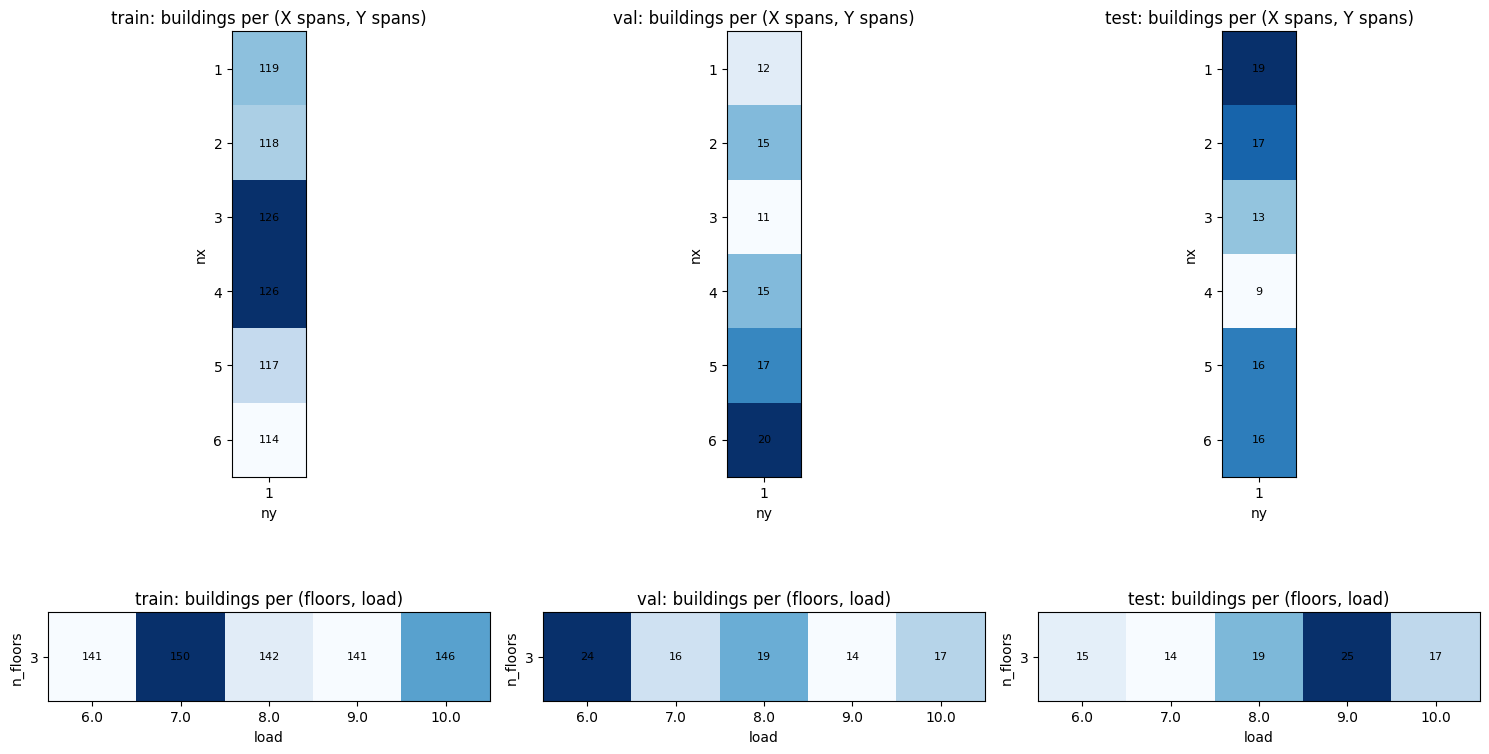

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/dataset-4-combination-coverage.png


PosixPath('/content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/dataset-4-combination-coverage.png')

In [21]:
# ============================================================
# DS-3  Distribution of the building parameters in train / val / test   (+ similarity statistics)
# ============================================================
def js_distance(a, b, bins):
    """Jensen-Shannon distance (base 2, 0 = identical, 1 = disjoint) of two samples on common bins."""
    pa, pb = np.histogram(a, bins)[0] / max(len(a), 1), np.histogram(b, bins)[0] / max(len(b), 1)
    m = 0.5 * (pa + pb)
    kl = lambda p, q: np.sum(p[p > 0] * np.log2(p[p > 0] / q[p > 0]))
    return float(np.sqrt(0.5 * kl(pa, m) + 0.5 * kl(pb, m)))

# building-level parameters + every individual span (X and Y bays) of every building
span_rows = [(it['split'], s_) for it in BLD for s_ in list(it['b']['x_spans']) + list(it['b']['y_spans'])]
SPANS = pd.DataFrame(span_rows, columns=['split', 'span'])
DIST = [('n_floors', 'Number of floors', UB), ('nx', 'Number of X spans', UB), ('ny', 'Number of Y spans', UB),
        ('load', 'Load (kN/m²)', UB), ('height_mean', 'Mean story height (mm)', UB), ('span', 'Span length (mm, all bays)', SPANS),
        ('n_members', 'Members per building', UB), ('floor_area_m2', 'Total floor area (m²)', UB), ('w_reported', 'Teacher steel weight (kg)', UB)]
fig, axes = plt.subplots(3, 3, figsize=(18, 12)); stats = []; cols = {'train': 'tab:blue', 'val': 'tab:orange', 'test': 'tab:green'}
from scipy import stats as sps
for a, (c, lab, src) in zip(axes.ravel(), DIST):
    allv = src[c].dropna(); discrete = allv.nunique() <= 12
    bins = (np.sort(allv.unique()) if discrete else np.linspace(allv.min(), allv.max(), 21))
    edges = np.append(bins - 0.5 * np.min(np.diff(bins)) if discrete and len(bins) > 1 else bins, [])
    if discrete and len(bins) > 1:
        edges = np.append(bins - np.min(np.diff(bins)) / 2, bins[-1] + np.min(np.diff(bins)) / 2)
    elif discrete:
        edges = np.array([bins[0] - 0.5, bins[0] + 0.5])
    for k, s in enumerate(SPLITS):
        v = src[src['split'] == s][c].dropna()
        h = np.histogram(v, edges)[0] / max(len(v), 1) * 100
        ctr = 0.5 * (edges[:-1] + edges[1:]); wd = (edges[1] - edges[0]) / 3.4
        a.bar(ctr + (k - 1) * wd, h, wd, color=cols[s], label=f'{s} (n={len(v)})', alpha=0.85)
    a.set(title=lab, ylabel='% of split'); a.legend(fontsize=8); a.grid(alpha=0.3, axis='y')
    tr = src[src['split'] == 'train'][c].dropna()
    for s in ('val', 'test'):
        v = src[src['split'] == s][c].dropna()
        stats.append(dict(parameter=c, comparison=f'train vs {s}', JS_distance=js_distance(tr, v, edges),
                          KS_statistic=sps.ks_2samp(tr, v).statistic, KS_pvalue=sps.ks_2samp(tr, v).pvalue,
                          mean_train=tr.mean(), mean_other=v.mean()))
plt.suptitle('Distribution of the building parameters per split', fontsize=14); plt.tight_layout()
save_fig(fig, 'dataset-3-parameter-distributions.png')
dist_df = pd.DataFrame(stats).set_index(['parameter', 'comparison'])
print('JS distance: 0 = identical distributions, 1 = disjoint (rule of thumb: < 0.1 similar).  KS p-value is only indicative '
      '(buildings of a full-factorial grid are not independent draws).')
save_table(dist_df.round(4), 'dataset-3-distribution-similarity.csv')

# ============================================================
# DS-4  Coverage of parameter combinations  (counts per split)
# ============================================================
def heat(ax, d, r, c, title):
    t = d.groupby([r, c]).size().unstack(fill_value=0)
    ax.imshow(t.to_numpy(), cmap='Blues'); ax.set_xticks(range(t.shape[1])); ax.set_xticklabels(t.columns)
    ax.set_yticks(range(t.shape[0])); ax.set_yticklabels(t.index); ax.set(xlabel=c, ylabel=r, title=title)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]): ax.text(j, i, int(t.iat[i, j]), ha='center', va='center', fontsize=8)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for k, s in enumerate(SPLITS):
    d = UB[UB['split'] == s]
    heat(axes[0, k], d, 'nx', 'ny', f'{s}: buildings per (X spans, Y spans)')
    heat(axes[1, k], d.assign(load=d['load'].round(1)), 'n_floors', 'load', f'{s}: buildings per (floors, load)')
plt.tight_layout(); save_fig(fig, 'dataset-4-combination-coverage.png')

## DS-5/6  Leakage, duplicates, conflicting labels, nearest-neighbour distance

Number of IDENTICAL building conditions shared between splits (diagonal = distinct conditions in the split):


,train,val,test
train,720.0,0.0,0.0
val,0.0,90.0,0.0
test,0.0,0.0,90.0


Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/dataset-5-signature-overlap.csv
Same file name in two splits : {'train&val': 0, 'train&test': 0, 'val&test': 0}
Duplicate conditions inside a split: {'train': 0, 'val': 0, 'test': 0}
0 condition(s) occur more than once; 0 of them across splits (LEAKAGE); 0 have differing teacher labels (label noise).


ValueError: Too many bins for data range. Cannot create 25 finite-sized bins.

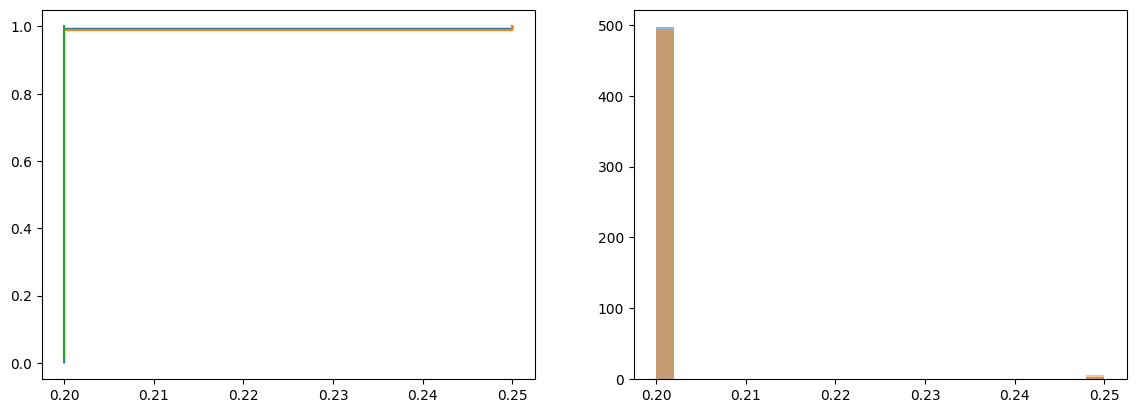

In [22]:
# ============================================================
# DS-5  Leakage / duplicates / conflicting labels
#   signature = (floors, nx, ny, X spans, Y spans, story heights, load) = everything the DNN sees about a building
# ============================================================
sig_sets = {s: set(UB.loc[UB['split'] == s, 'sig']) for s in SPLITS}
ov_m = pd.DataFrame(index=SPLITS, columns=SPLITS, dtype=int)
for a in SPLITS:
    for b in SPLITS:
        ov_m.loc[a, b] = len(sig_sets[a] & sig_sets[b])
print('Number of IDENTICAL building conditions shared between splits (diagonal = distinct conditions in the split):')
save_table(ov_m, 'dataset-5-signature-overlap.csv')
names_sets = {s: set(bdf.loc[bdf['split'] == s, 'file']) for s in SPLITS}
file_overlap = {f'{a}&{b}': sorted(names_sets[a] & names_sets[b]) for a, b in (('train', 'val'), ('train', 'test'), ('val', 'test'))}
dup_within = {s: int(UB[UB['split'] == s]['sig'].duplicated().sum()) for s in SPLITS}
print('Same file name in two splits :', {k: len(v) for k, v in file_overlap.items()})
print('Duplicate conditions inside a split:', dup_within)

# labels of identical conditions: do they agree?  (identical input but different teacher output = label noise ceiling)
lab_hash = {}
for it in BLD:
    lab_hash[it['idx']] = (it['ck'].tobytes(), it['bk'].tobytes())
UB['label_hash'] = UB['bidx'].map(lambda i: hash(lab_hash[i]))
g = UB.groupby('sig').agg(n=('sig', 'size'), n_splits=('split', 'nunique'), n_label_versions=('label_hash', 'nunique'))
dups = g[g['n'] > 1]
conflict = dups[dups['n_label_versions'] > 1]
leak = dups[dups['n_splits'] > 1]
print(f'{len(dups)} condition(s) occur more than once; {len(leak)} of them across splits (LEAKAGE); '
      f'{len(conflict)} have differing teacher labels (label noise).')
if len(dups):
    show = UB[UB['sig'].isin(dups.index)].sort_values('sig')[['split', 'file', 'n_floors', 'nx', 'ny', 'x_span_mean', 'height_mean', 'load']]
    save_table(show, 'dataset-5-duplicate-conditions.csv', index=False)

# ============================================================
# DS-6  Nearest-neighbour distance in the (normalised) building-parameter space
#   val/test -> nearest TRAINING building, compared with train -> nearest OTHER training building (leave-one-out).
#   If test distances are much larger than the LOO distances the test set asks the DNN to extrapolate.
# ============================================================
FEATS = ['n_floors', 'nx', 'ny', 'x_span_mean', 'y_span_mean', 'height_mean', 'load']
LO = np.array([RANGES['n_floors'][0], RANGES['nx'][0], RANGES['ny'][0], RANGES['span'][0], RANGES['span'][0], RANGES['height'][0], RANGES['load'][0]], float)
HI = np.array([RANGES['n_floors'][1], RANGES['nx'][1], RANGES['ny'][1], RANGES['span'][1], RANGES['span'][1], RANGES['height'][1], RANGES['load'][1]], float)
Z = (UB[FEATS].to_numpy(float) - LO) / (HI - LO)
tr_idx = np.where(UB['split'] == 'train')[0]

def nn_dist(q_idx, loo=False, chunk=500):
    out = np.empty(len(q_idx)); T = Z[tr_idx]
    for s in range(0, len(q_idx), chunk):
        q = Z[q_idx[s:s + chunk]]; d = np.sqrt(((q[:, None, :] - T[None, :, :]) ** 2).sum(-1))
        if loo:
            d[np.arange(len(q)), np.searchsorted(tr_idx, q_idx[s:s + chunk])] = np.inf
        out[s:s + chunk] = d.min(1)
    return out
UB['nn_dist_to_train'] = np.nan
UB.loc[tr_idx, 'nn_dist_to_train'] = nn_dist(tr_idx, loo=True)
for s in ('val', 'test'):
    idx = np.where(UB['split'] == s)[0]; UB.loc[idx, 'nn_dist_to_train'] = nn_dist(idx)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8)); q_rows = []
for s, c, lab in (('train', 'tab:blue', 'train -> other train (leave-one-out)'), ('val', 'tab:orange', 'val -> train'), ('test', 'tab:green', 'test -> train')):
    v = np.sort(UB.loc[UB['split'] == s, 'nn_dist_to_train'].to_numpy())
    ax[0].step(v, np.arange(1, len(v) + 1) / len(v), color=c, label=lab, where='post')
    ax[1].hist(v, bins=25, alpha=0.5, color=c, density=True, label=lab)
    q_rows.append(dict(split=s, n=len(v), median=np.median(v), p90=np.percentile(v, 90), max=v.max(), share_zero=(v < 1e-9).mean()))
ax[0].set(xlabel='Nearest-neighbour distance (normalised parameters)', ylabel='ECDF', title='Distance to the nearest training building')
ax[1].set(xlabel='distance', ylabel='density', title='Histogram'); [a.grid(alpha=0.3) or a.legend(fontsize=8) for a in ax]
plt.tight_layout(); save_fig(fig, 'dataset-6-nearest-neighbour-distance.png')
nn_tab = pd.DataFrame(q_rows).set_index('split')
print('Features:', FEATS, '(each scaled to [0,1] with the normalisation ranges). share_zero = identical to a training building.')
save_table(nn_tab.round(4), 'dataset-6-nearest-neighbour-distance.csv')

## DS-7/8  Label coverage, class balance, baselines and label trends

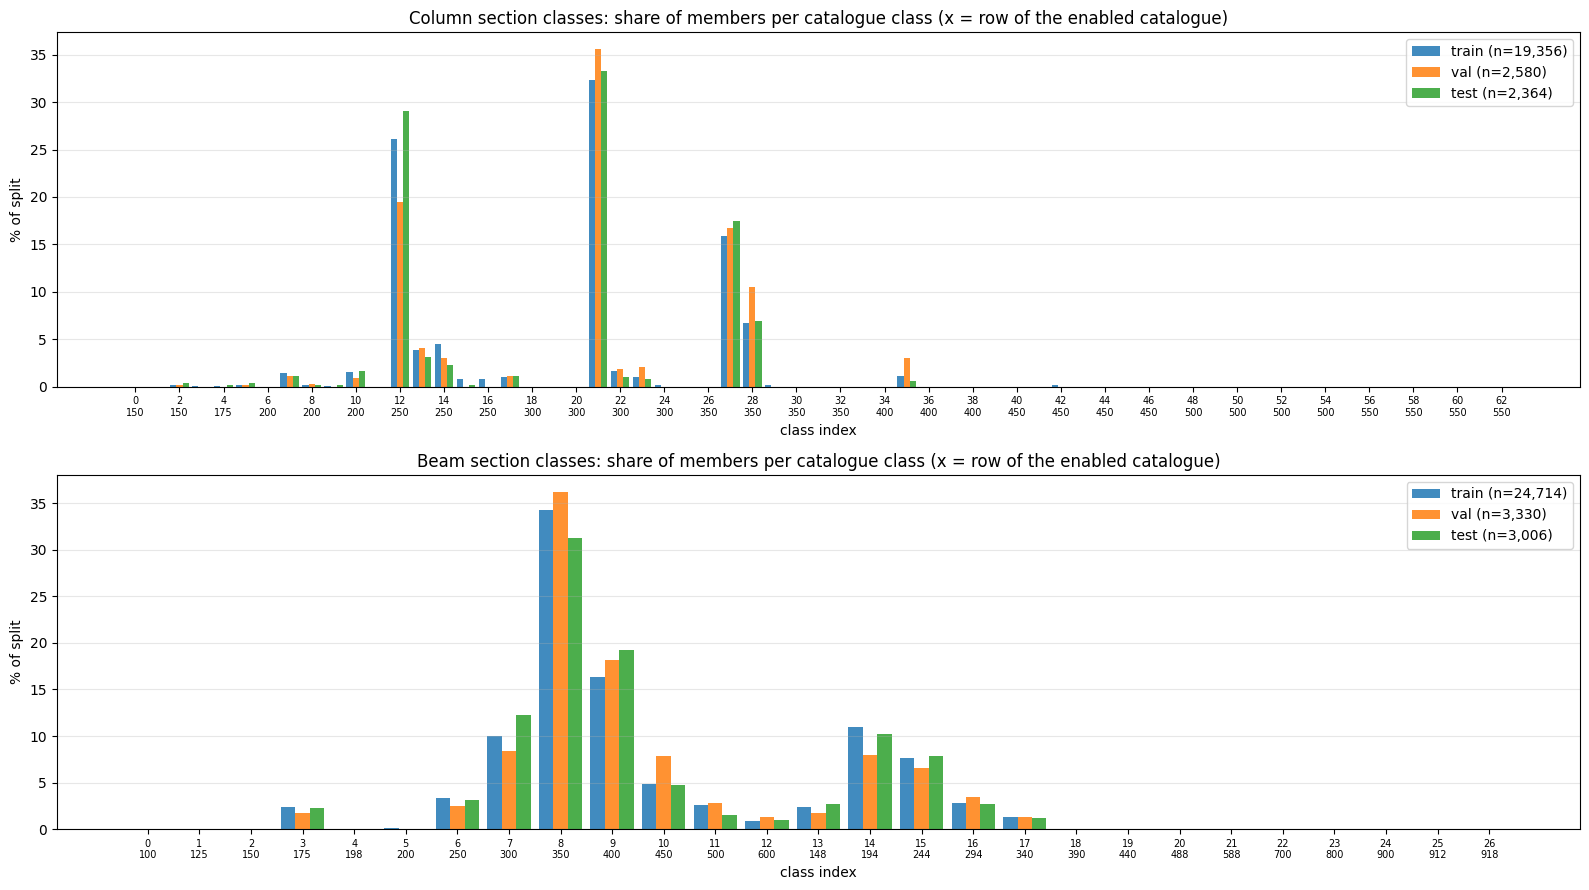

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/dataset-7-class-distribution.png
max_achievable_acc = 100 - share of members whose class never appears in the training set (no model can learn those).
majority_baseline = always predict the most frequent training class of that member type: a DNN must beat this clearly.


n_members  classes_in_catalog  classes_used  \
member split                                                
column train      19356                  63            23   
       val         2580                  63            15   
       test        2364                  63            18   
beam   train      24714                  27            18   
       val         3330                  27            14   
       test        3006                  27            14   

              classes_unused_in_train  members_with_class_unseen_in_train  \
member split                                                                
column train                        0                                   0   
       val                          0                                   0   
       test                         0                                   0   
beam   train                        0                                   0   
       val                          0                                   0   
       test                         0                                   0   

              unseen_pct  max_achievable_acc_pct  majority_baseline_acc_pct  \
member split                                                                  
column train         0.0                   100.0                      32.36   
       val           0.0                   100.0                      35.58   
       test          0.0                   100.0                      33.33   
beam   train         0.0                   100.0                      34.30   
       val           0.0                   100.0                      36.25   
       test          0.0                   100.0                      31.24   

              effective_n_classes  train_classes_below_10_samples  
member split                                                       
column train                 7.00                            40.0  
       val                   6.65                             NaN  
       test                  5.92                             NaN  
beam   train                 7.99                            13.0  
       val                   7.62                             NaN  
       test                  7.93                             NaN

Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/dataset-7-label-coverage-and-baselines.csv


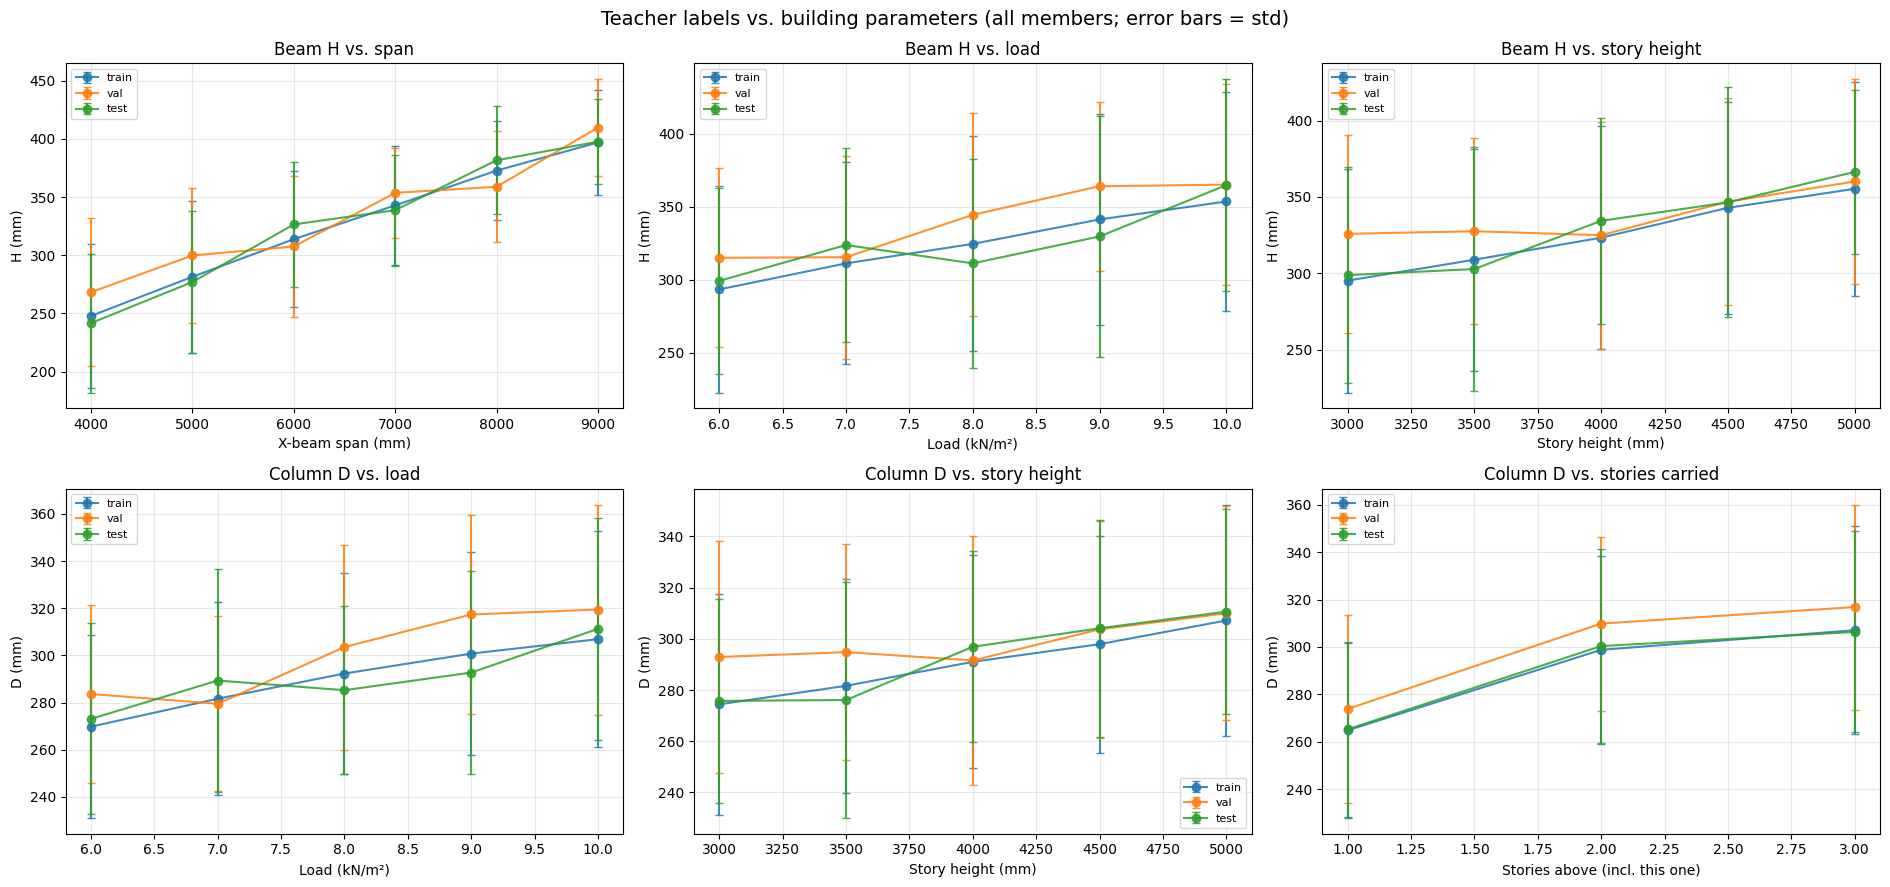

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/dataset-8-label-trends.png


PosixPath('/content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/dataset-8-label-trends.png')

In [23]:
# ============================================================
# DS-7  Label (section class) coverage, class balance and trivial baselines
# ============================================================
rows, cls_cnt = [], {}
fig, axes = plt.subplots(2, 1, figsize=(16, 9))
for a, (kind, cat, lab) in zip(axes, (('column', cat_col, 'Column'), ('beam', cat_beam, 'Beam'))):
    M = MEM[MEM['kind'] == kind]; tr = M[M['split'] == 'train']
    maj = tr['k'].value_counts().idxmax(); seen = set(tr['k'])
    for k_, s in enumerate(SPLITS):
        v = M[M['split'] == s]['k']; cnt = np.bincount(v, minlength=cat.n); cls_cnt[(kind, s)] = cnt
        a.bar(np.arange(cat.n) + (k_ - 1) * 0.28, cnt / max(len(v), 1) * 100, 0.28, label=f'{s} (n={len(v):,})', color=cols[s], alpha=0.85)
        p = cnt / max(cnt.sum(), 1); ent = -(p[p > 0] * np.log(p[p > 0])).sum()
        unseen = v[~v.isin(seen)]
        rows.append(dict(member=kind, split=s, n_members=len(v), classes_in_catalog=cat.n, classes_used=int((cnt > 0).sum()),
                         classes_unused_in_train=int(((cnt > 0) & (np.bincount(tr['k'], minlength=cat.n) == 0)).sum()),
                         members_with_class_unseen_in_train=len(unseen), unseen_pct=len(unseen) / max(len(v), 1) * 100,
                         max_achievable_acc_pct=100 - len(unseen) / max(len(v), 1) * 100,
                         majority_baseline_acc_pct=(v == maj).mean() * 100, effective_n_classes=float(np.exp(ent)),
                         train_classes_below_10_samples=int(((np.bincount(tr['k'], minlength=cat.n) < 10)).sum()) if s == 'train' else np.nan))
    a.set(title=f'{lab} section classes: share of members per catalogue class (x = row of the enabled catalogue)', ylabel='% of split', xlabel='class index'); a.legend(); a.grid(alpha=0.3, axis='y')
    tk = np.arange(0, cat.n, max(1, cat.n // 25)); a.set_xticks(tk); a.set_xticklabels([f'{i}\n{int(cat.size[i])}' for i in tk], fontsize=7)
plt.tight_layout(); save_fig(fig, 'dataset-7-class-distribution.png')
lab_df = pd.DataFrame(rows).set_index(['member', 'split'])
print('max_achievable_acc = 100 - share of members whose class never appears in the training set (no model can learn those).\n'
      'majority_baseline = always predict the most frequent training class of that member type: a DNN must beat this clearly.')
save_table(lab_df.round(2), 'dataset-7-label-coverage-and-baselines.csv')

# ============================================================
# DS-8  Do the labels behave physically, and identically in all splits?  (mean +- std of the catalogue dimension)
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(19, 9)); axes = axes.ravel()
def trend(a, d, x, xlabel, title, ylab):
    for s in SPLITS:
        g = d[d['split'] == s].groupby(x)['size_mm'].agg(['mean', 'std', 'size'])
        a.errorbar(g.index, g['mean'], yerr=g['std'].fillna(0), marker='o', capsize=3, color=cols[s], label=s, alpha=0.85)
    a.set(xlabel=xlabel, ylabel=ylab, title=title); a.grid(alpha=0.3); a.legend(fontsize=8)
bx = MEM[MEM['member'] == 'beam_X']; col = MEM[MEM['member'] == 'column']
trend(axes[0], bx, 'span', 'X-beam span (mm)', 'Beam H vs. span', 'H (mm)')
trend(axes[1], bx.assign(load=bx['load'].round(1)), 'load', 'Load (kN/m²)', 'Beam H vs. load', 'H (mm)')
trend(axes[2], bx, 'story_height', 'Story height (mm)', 'Beam H vs. story height', 'H (mm)')
trend(axes[3], col.assign(load=col['load'].round(1)), 'load', 'Load (kN/m²)', 'Column D vs. load', 'D (mm)')
trend(axes[4], col, 'story_height', 'Story height (mm)', 'Column D vs. story height', 'D (mm)')
c2 = col.assign(floors_above=col['n_floors'] - col['story'] + 1)
trend(axes[5], c2, 'floors_above', 'Stories above (incl. this one)', 'Column D vs. stories carried', 'D (mm)')
plt.suptitle('Teacher labels vs. building parameters (all members; error bars = std)', fontsize=14); plt.tight_layout()
save_fig(fig, 'dataset-8-label-trends.png')

## DS-9  Teacher-data monotonicity audit

building_pairs  \
scope             constraint                    pair_type                          
all splits pooled beam_load                     single parameter            1800   
                  beam_span                     one bay                      375   
                                                several bays                7500   
                  column_height                 several stories             5400   
                  column_load                   single parameter            1800   
                  column_taper (upper <= lower) within building             1800   
train             beam_load                     single parameter            1148   
                  beam_span                     one bay                      234   
                                                several bays                4783   
                  column_height                 several stories             3447   
                  column_load                   single parameter            1148   
                  column_taper (upper <= lower) within building             1440   
val               beam_load                     single parameter              21   
                  beam_span                     one bay                        2   
                                                several bays                  84   
                  column_height                 several stories               45   
                  column_load                   single parameter              21   
                  column_taper (upper <= lower) within building              180   
test              beam_load                     single parameter              17   
                  beam_span                     one bay                        6   
                                                several bays                  71   
                  column_height                 several stories               75   
                  column_load                   single parameter              17   
                  column_taper (upper <= lower) within building              180   

                                                                  member_comparisons  \
scope             constraint                    pair_type                              
all splits pooled beam_load                     single parameter               62100   
                  beam_span                     one bay                         2250   
                                                several bays                   45000   
                  column_height                 several stories                48600   
                  column_load                   single parameter               48600   
                  column_taper (upper <= lower) within building                16200   
train             beam_load                     single parameter               39120   
                  beam_span                     one bay                         1404   
                                                several bays                   28698   
                  column_height                 several stories                30744   
                  column_load                   single parameter               30672   
                  column_taper (upper <= lower) within building                12904   
val               beam_load                     single parameter                 828   
                  beam_span                     one bay                           12   
                                                several bays                     504   
                  column_height                 several stories                  396   
                  column_load                   single parameter                 636   
                  column_taper (upper <= lower) within building                 1720   
test              beam_load                     single parameter                 555   
                  beam_span      

Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/dataset-9-teacher-monotonicity-audit.csv


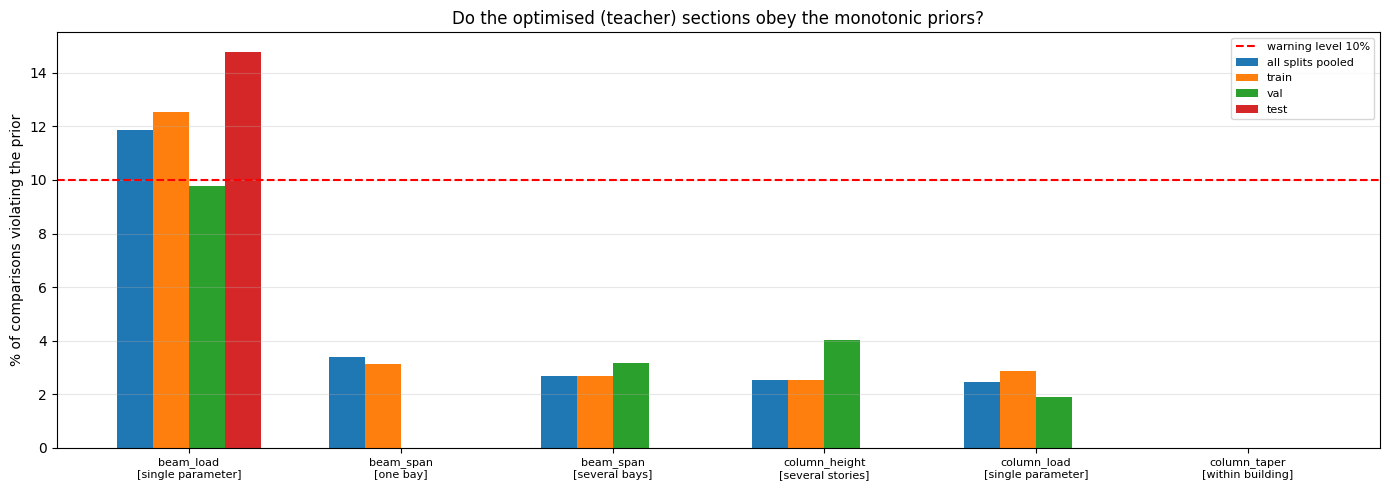

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/dataset-9-teacher-monotonicity-audit.png


In [24]:
# ============================================================
# DS-9  Teacher-data monotonicity audit (physical plausibility of the labels)
#   Building pairs identical except ONE parameter are compared member by member at the same grid position.
#   Expected: beam H grows with X-span and load, column D grows with load and story height, and a column
#   is not larger than the column of the story below.  Violations are reported, not hidden.
#   Rate = violating comparisons / all comparisons (higher-parameter member is SMALLER than the lower-parameter one).
# ============================================================
AUDIT_WARN_RATE = 0.10
def audit(items, max_group=60, seed=0):
    rng = np.random.default_rng(seed); acc = defaultdict(lambda: [0, 0, 0.0, 0])      # comps, viol, shortfall, pairs
    def tally(key, hi, lo):
        m = np.isfinite(hi) & np.isfinite(lo)
        n = int(m.sum())
        if n == 0: return
        short = (lo - hi)[m]; r = acc[key]; r[0] += n; r[1] += int((short > 1e-9).sum()); r[2] += float(np.clip(short, 0, None).sum()); r[3] += 1
    def groups(keyfn):
        g = defaultdict(list)
        for it in items: g[keyfn(it['b'])].append(it)
        for lst in g.values():
            if len(lst) > max_group: lst = [lst[i] for i in rng.choice(len(lst), max_group, replace=False)]
            for a in range(len(lst)):
                for c in range(a + 1, len(lst)): yield lst[a], lst[c]
    hts = lambda b: tuple(b['heights'][k] for k in range(1, b['n_floors'] + 1))
    for A, B in groups(lambda b: (b['n_floors'], b['nx'], b['ny'], tuple(b['x_spans']), tuple(b['y_spans']), hts(b))):     # load
        if A['b']['load'] == B['b']['load']: continue
        lo, hi = (A, B) if A['b']['load'] < B['b']['load'] else (B, A)
        tally(('beam_load', 'single parameter'), hi['beamH'], lo['beamH']); tally(('column_load', 'single parameter'), hi['colD'], lo['colD'])
    for A, B in groups(lambda b: (b['n_floors'], b['nx'], b['ny'], tuple(b['y_spans']), hts(b), b['load'])):               # X span
        d = [i for i, (p, q) in enumerate(zip(A['b']['x_spans'], B['b']['x_spans'])) if p != q]
        for i in d:
            lo, hi = (A, B) if A['b']['x_spans'][i] < B['b']['x_spans'][i] else (B, A)
            tally(('beam_span', 'one bay' if len(d) == 1 else 'several bays'), hi['beamH'][:, :, i, 0], lo['beamH'][:, :, i, 0])
    for A, B in groups(lambda b: (b['n_floors'], b['nx'], b['ny'], tuple(b['x_spans']), tuple(b['y_spans']), b['load'])):  # story height
        hA, hB = A['hs'], B['hs']; d = [f for f in range(len(hA)) if hA[f] != hB[f]]
        for f in d:
            lo, hi = (A, B) if hA[f] < hB[f] else (B, A)
            tally(('column_height', 'one story' if len(d) == 1 else 'several stories'), hi['colD'][f], lo['colD'][f])
    for it in items:                                                                                                       # taper
        D = it['colD']
        for f in range(it['b']['n_floors'] - 1): tally(('column_taper (upper <= lower)', 'within building'), D[f], D[f + 1])
    out = []
    for (c, t), (n, v, sh, npairs) in sorted(acc.items()):
        out.append(dict(constraint=c, pair_type=t, building_pairs=npairs, member_comparisons=n, violations=v,
                        violation_rate=v / n, mean_shortfall_mm_when_violated=sh / v if v else 0.0))
    return pd.DataFrame(out)

audit_frames = []
for scope, its in [('all splits pooled', BLD)] + [(s, [i for i in BLD if i['split'] == s]) for s in SPLITS]:
    a = audit(its)
    if len(a): audit_frames.append(a.assign(scope=scope))
AUDIT = pd.concat(audit_frames, ignore_index=True) if audit_frames else pd.DataFrame()
if AUDIT.empty:
    print('No comparable building pairs found - the priors cannot be audited from this dataset.')
else:
    AUDIT = AUDIT.set_index(['scope', 'constraint', 'pair_type'])
    save_table(AUDIT.round(4), 'dataset-9-teacher-monotonicity-audit.csv')
    d = AUDIT.reset_index(); d['lab'] = d['constraint'].str.replace(r' \(.*', '', regex=True) + '\n[' + d['pair_type'] + ']'
    fig, ax = plt.subplots(figsize=(14, 5)); labs = list(dict.fromkeys(d['lab'])); sc = list(dict.fromkeys(d['scope']))
    for k, s in enumerate(sc):
        v = d[d['scope'] == s].set_index('lab')['violation_rate'].reindex(labs) * 100
        ax.bar(np.arange(len(labs)) + (k - (len(sc) - 1) / 2) * 0.17, v, 0.17, label=s)
    ax.axhline(AUDIT_WARN_RATE * 100, color='r', ls='--', label=f'warning level {AUDIT_WARN_RATE:.0%}')
    ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs, fontsize=8); ax.set_ylabel('% of comparisons violating the prior')
    ax.set_title('Do the optimised (teacher) sections obey the monotonic priors?'); ax.legend(fontsize=8); ax.grid(alpha=0.3, axis='y')
    plt.tight_layout(); save_fig(fig, 'dataset-9-teacher-monotonicity-audit.png')

## DS-10  File-name consistency, weight plausibility, unused inputs

Buildings whose file name disagrees with the file contents (non-uniform spans / heights are not checkable): {'test': 0, 'train': 0, 'val': 0}
Buildings with non-uniform spans : 0 | with non-uniform story heights: 0


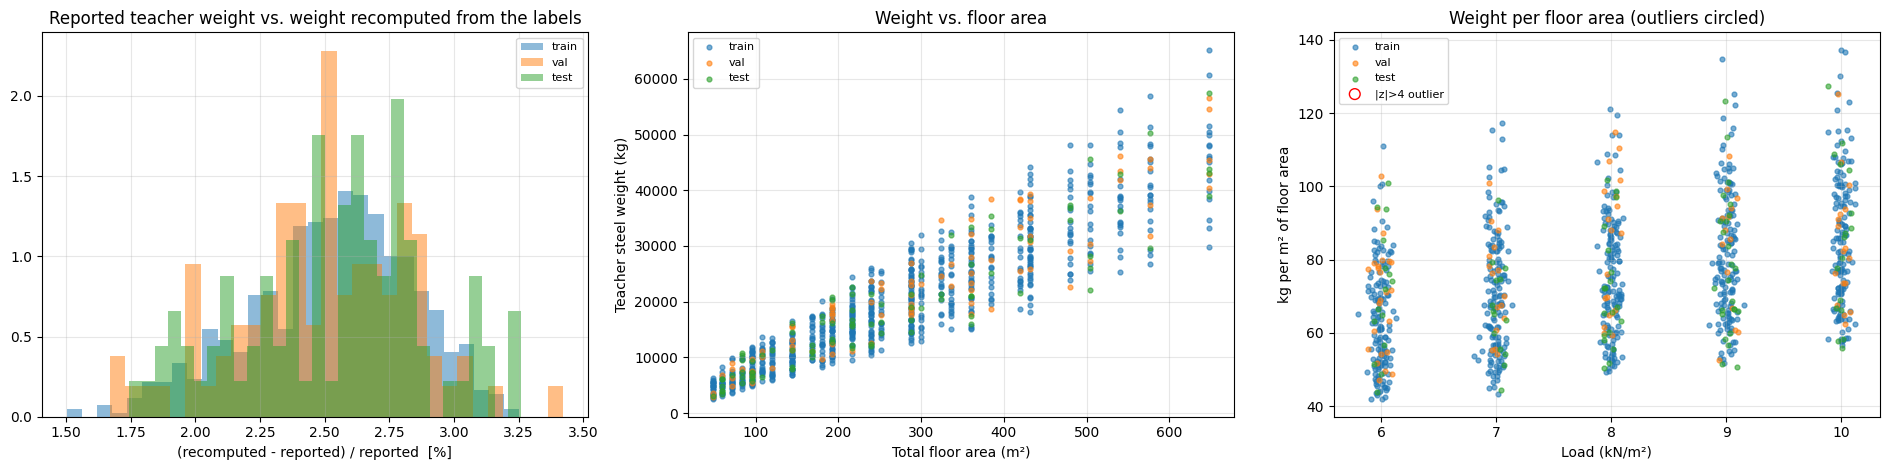

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/dataset-10-weight-plausibility.png
A systematic recompute difference means the catalogue masses / member lengths differ from what the optimiser used (connections, bases, ... may be included in the reported weight).


,n,weight_kg_mean,weight_per_m2_mean,weight_per_m2_std,recompute_diff_median_pct,recompute_diff_p95_abs_pct,outliers_z4
split,,,,,,,
test,90,18895.590,75.119,18.479,2.580,3.115,0
train,720,19600.507,75.256,18.092,2.559,3.014,0
val,90,23211.886,77.969,16.990,2.508,2.954,0


Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/dataset-10-weight-statistics.csv

Lateral bracing length Lb (read from the files, not an input channel of the DNN):


,min,max,nunique
split,,,
test,200.0,200.0,1
train,200.0,200.0,1
val,200.0,200.0,1


Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/dataset-10-Lb.csv


PosixPath('/content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/dataset-10-Lb.csv')

In [25]:
# ============================================================
# DS-10  Consistency checks: file name vs. contents, weight plausibility, unused inputs (Lb)
# ============================================================
# (a) file name vs. file contents
def name_check(row):
    p = parse_file_name(row['file'])
    if np.isnan(p[0]): return 'name_pattern_mismatch'
    f, nx, xs, ny, ys, h, w = p; bad = []
    if f != row['n_floors']: bad.append('floors')
    if nx != row['nx']: bad.append('nx')
    if ny != row['ny']: bad.append('ny')
    if row['x_span_min'] == row['x_span_max'] and xs != row['x_span_mean']: bad.append('x_span')
    if row['y_span_min'] == row['y_span_max'] and ys != row['y_span_mean']: bad.append('y_span')
    if row['height_min'] == row['height_max'] and h != row['height_mean']: bad.append('height')
    if abs(w - row['load']) > 1e-9: bad.append('load')
    return ','.join(bad)
UB['name_mismatch'] = UB.apply(name_check, axis=1)
nm = UB.groupby('split')['name_mismatch'].apply(lambda s: int((s != '').sum()))
print('Buildings whose file name disagrees with the file contents (non-uniform spans / heights are not checkable):', nm.to_dict())
if (UB['name_mismatch'] != '').any():
    display(UB.loc[UB['name_mismatch'] != '', ['split', 'file', 'name_mismatch']].head(20))
print('Buildings with non-uniform spans :', int((UB['x_span_min'] != UB['x_span_max']).sum() + (UB['y_span_min'] != UB['y_span_max']).sum()),
      '| with non-uniform story heights:', int((UB['height_min'] != UB['height_max']).sum()))

# (b) reported teacher weight vs. weight recomputed from labels x catalogue mass x member length
UB['w_rel_diff'] = (UB['w_recalc'] - UB['w_reported']) / UB['w_reported']
# (c) robust outliers of the weight per floor area, within groups of equal floor count
def robust_z(s):
    med = s.median(); mad = (s - med).abs().median() * 1.4826
    return (s - med) / (mad if mad > 0 else s.std() + 1e-9)
UB['w_area_z'] = UB.groupby('n_floors')['w_per_area'].transform(robust_z)
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
for s in SPLITS:
    v = UB[UB['split'] == s]
    ax[0].hist(v['w_rel_diff'].dropna() * 100, bins=30, alpha=0.5, color=cols[s], label=s, density=True)
    ax[1].scatter(v['floor_area_m2'], v['w_reported'], s=12, alpha=0.6, color=cols[s], label=s)
    ax[2].scatter(v['load'] + np.random.default_rng(0).normal(0, 0.05, len(v)), v['w_per_area'], s=12, alpha=0.6, color=cols[s], label=s)
out = UB[UB['w_area_z'].abs() > 4]; ax[2].scatter(out['load'], out['w_per_area'], s=60, facecolors='none', edgecolors='r', label='|z|>4 outlier')
ax[0].set(xlabel='(recomputed - reported) / reported  [%]', title='Reported teacher weight vs. weight recomputed from the labels')
ax[1].set(xlabel='Total floor area (m²)', ylabel='Teacher steel weight (kg)', title='Weight vs. floor area')
ax[2].set(xlabel='Load (kN/m²)', ylabel='kg per m² of floor area', title='Weight per floor area (outliers circled)')
[a.grid(alpha=0.3) or a.legend(fontsize=8) for a in ax]; plt.tight_layout(); save_fig(fig, 'dataset-10-weight-plausibility.png')
wt = UB.groupby('split').agg(n=('file', 'size'), weight_kg_mean=('w_reported', 'mean'), weight_per_m2_mean=('w_per_area', 'mean'),
                              weight_per_m2_std=('w_per_area', 'std'), recompute_diff_median_pct=('w_rel_diff', lambda s: s.median() * 100),
                              recompute_diff_p95_abs_pct=('w_rel_diff', lambda s: s.abs().quantile(0.95) * 100),
                              outliers_z4=('w_area_z', lambda s: int((s.abs() > 4).sum())))
print('A systematic recompute difference means the catalogue masses / member lengths differ from what the optimiser used '
      '(connections, bases, ... may be included in the reported weight).')
save_table(wt.round(3), 'dataset-10-weight-statistics.csv')
if len(out): save_table(out[['split', 'file', 'w_reported', 'w_per_area', 'w_area_z']].sort_values('w_area_z', key=abs, ascending=False).head(15).round(2), 'dataset-10-weight-outliers.csv', index=False)

# (d) input parameters present in the files but NOT encoded in the DNN input
lb = UB.groupby('split')['Lb'].agg(['min', 'max', 'nunique'])
print('\nLateral bracing length Lb (read from the files, not an input channel of the DNN):'); save_table(lb, 'dataset-10-Lb.csv')

## DS-11  Link to the test results

Test accuracy vs. the majority-class baseline and the ceiling imposed by classes missing from the training data:


DNN_accuracy_pct  majority_baseline_pct  \
member experiment                                                 
column A_baseline                  80.16                  33.33   
       B_beam_span                 78.89                  33.33   
       C_load                      79.70                  33.33   
       D_column_height             80.12                  33.33   
       E_combined                  78.43                  33.33   
beam   A_baseline                  73.75                  31.24   
       B_beam_span                 72.19                  31.24   
       C_load                      72.69                  31.24   
       D_column_height             71.92                  31.24   
       E_combined                  72.69                  31.24   

                        max_achievable_pct  gain_over_baseline_pts  
member experiment                                                   
column A_baseline                    100.0                   46.83  
       B_beam_span                   100.0                   45.56  
       C_load                        100.0                   46.36  
       D_column_height               100.0                   46.79  
       E_combined                    100.0                   45.09  
beam   A_baseline                    100.0                   42.51  
       B_beam_span                   100.0                   40.95  
       C_load                        100.0                   41.45  
       D_column_height               100.0                   40.69  
       E_combined                    100.0                   41.45

Saved table : /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/tables/dataset-11-accuracy-vs-baseline.csv


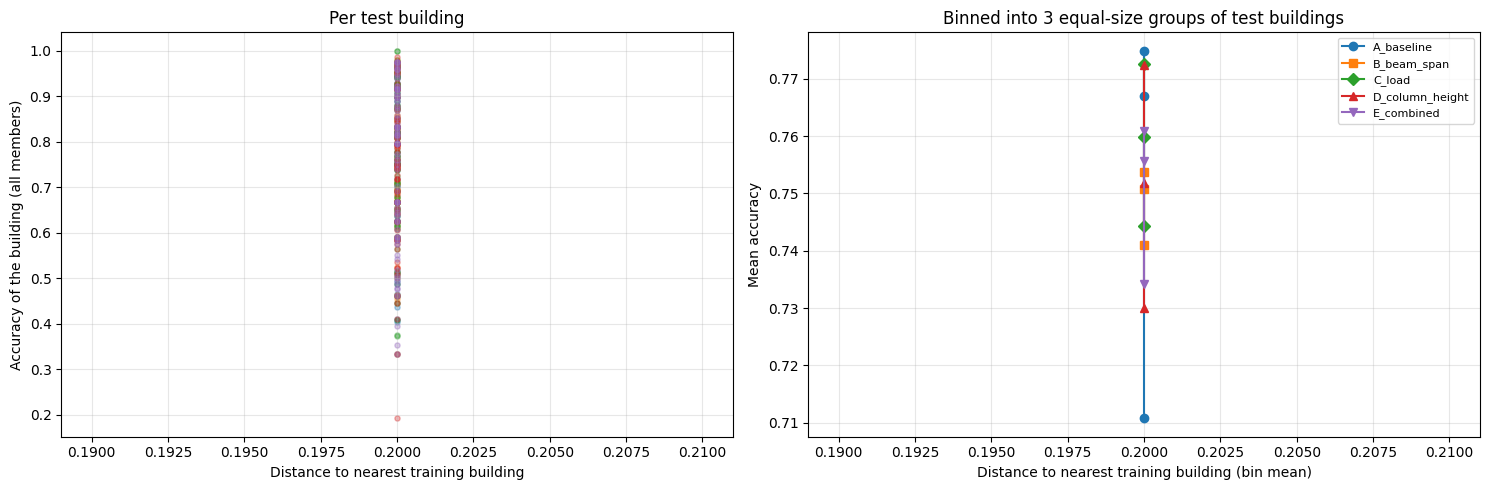

Saved figure: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/dataset-11-accuracy-vs-nn-distance.png
Spearman correlation (distance to train vs. building accuracy; negative = far-from-train buildings are predicted worse):
{'A_baseline': np.float64(-0.072), 'B_beam_span': np.float64(-0.012), 'C_load': np.float64(-0.028), 'D_column_height': np.float64(0.013), 'E_combined': np.float64(0.017)}


In [26]:
# ============================================================
# DS-11  Link between dataset validity and the test results
#   (a) DNN accuracy vs. trivial baselines and the label-coverage ceiling
#   (b) test accuracy vs. distance of the test building to the training set
# ============================================================
rows = []
for kind in ('column', 'beam'):
    for n in EXPERIMENTS:
        s = _side(DF[n], kind)
        rows.append(dict(member=kind, experiment=n, DNN_accuracy_pct=s['is_correct'].mean() * 100,
                         majority_baseline_pct=lab_df.loc[(kind, 'test'), 'majority_baseline_acc_pct'],
                         max_achievable_pct=lab_df.loc[(kind, 'test'), 'max_achievable_acc_pct']))
cmp_df = pd.DataFrame(rows).set_index(['member', 'experiment'])
cmp_df['gain_over_baseline_pts'] = cmp_df['DNN_accuracy_pct'] - cmp_df['majority_baseline_pct']
print('Test accuracy vs. the majority-class baseline and the ceiling imposed by classes missing from the training data:')
save_table(cmp_df.round(2), 'dataset-11-accuracy-vs-baseline.csv')

T = UB[UB['split'] == 'test'][['file', 'nn_dist_to_train', 'n_members', 'load', 'n_floors']].set_index('file')
pb = {n: DF[n].groupby('file_name')['is_correct'].mean() for n in EXPERIMENTS}
J = pd.DataFrame(pb).join(T, how='inner')
if len(J) < 8:
    print(f'Only {len(J)} test buildings could be matched with the dataset - nearest-neighbour analysis skipped.')
else:
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    nb = min(5, J['nn_dist_to_train'].nunique()); J['bin'] = pd.qcut(J['nn_dist_to_train'].rank(method='first'), nb, labels=False)
    centers = J.groupby('bin')['nn_dist_to_train'].mean()
    for n in EXPERIMENTS:
        ax[0].scatter(J['nn_dist_to_train'], J[n], s=14, alpha=0.35, color=COLORS[n])
        ax[1].plot(centers.values, J.groupby('bin')[n].mean().values, marker=MARKERS[n], color=COLORS[n], label=n)
    ax[0].set(xlabel='Distance to nearest training building', ylabel='Accuracy of the building (all members)', title='Per test building')
    ax[1].set(xlabel='Distance to nearest training building (bin mean)', ylabel='Mean accuracy', title=f'Binned into {nb} equal-size groups of test buildings')
    [a.grid(alpha=0.3) for a in ax]; ax[1].legend(fontsize=8); plt.tight_layout(); save_fig(fig, 'dataset-11-accuracy-vs-nn-distance.png')
    corr = {n: sps.spearmanr(J['nn_dist_to_train'], J[n])[0] for n in EXPERIMENTS}
    print('Spearman correlation (distance to train vs. building accuracy; negative = far-from-train buildings are predicted worse):')
    print({k: round(v, 3) for k, v in corr.items()})

## DS-12  Validity scorecard

In [27]:
# ============================================================
# DS-12  Validity scorecard  (thresholds are rules of thumb - edit them to your own acceptance criteria)
# ============================================================
TH = dict(max_skipped_pct=2.0, min_train_share_pct=60.0, max_js=0.15, max_unseen_pct=1.0, max_nn_ratio=1.5,
          max_audit_rate=AUDIT_WARN_RATE, max_recompute_median_pct=5.0)
chk = []
def add(name, value, ok, warn=None, note=''):
    chk.append(dict(check=name, value=value, status='PASS' if ok else ('WARN' if warn else 'FAIL'), note=note))
tot_files = sum(len(v) for v in file_list.values()); skipped = tot_files - len(UB)
add('Files skipped (parse error / disabled / unknown section)', f'{skipped}/{tot_files} ({skipped / tot_files:.1%})', skipped / tot_files * 100 <= TH['max_skipped_pct'], True)
sh = ov.loc['train', 'share_of_buildings_%']
add('Training share of all buildings', f'{sh:.1f} % (val {ov.loc["val", "share_of_buildings_%"]:.1f} %, test {ov.loc["test", "share_of_buildings_%"]:.1f} %)', sh >= TH['min_train_share_pct'], True)
add('All parameters inside the normalisation ranges', 'yes' if rng_df['inside_norm_range'].all() else 'NO', bool(rng_df['inside_norm_range'].all()), False, 'otherwise the DNN notebook raises an error')
ex = int(rng_df[rng_df['split'] != 'train']['n_buildings_outside_train_range'].sum())
add('Val/test parameters inside the training range', f'{ex} building-parameter cases outside', ex == 0, True, 'outside = extrapolation')
nleak = len(leak) + sum(len(v) for v in file_overlap.values())
add('No identical condition / file shared between splits', f'{len(leak)} shared conditions, {sum(len(v) for v in file_overlap.values())} shared file names', nleak == 0, False, 'leakage inflates test accuracy')
add('Duplicate conditions with conflicting labels', f'{len(conflict)}', len(conflict) == 0, True, 'label-noise ceiling for those inputs')
mj = dist_df.loc[[i for i in dist_df.index if i[0] in ('n_floors', 'nx', 'ny', 'load', 'height_mean', 'span')], 'JS_distance'].max()
add('Parameter distributions similar across splits (max JS distance)', f'{mj:.3f}', mj <= TH['max_js'], True, 'JS is biased upwards for small splits (few buildings)')
ratio = nn_tab.loc['test', 'median'] / max(nn_tab.loc['train', 'median'], 1e-9) if nn_tab.loc['train', 'median'] > 0 else (1.0 if nn_tab.loc['test', 'median'] == 0 else np.inf)
add('Test is as close to train as train is to itself (median NN ratio)', f'{ratio:.2f}', ratio <= TH['max_nn_ratio'], True, 'larger = test extrapolates')
for kind in ('column', 'beam'):
    u = lab_df.loc[(kind, 'test'), 'unseen_pct']
    add(f'Test {kind} classes missing from training', f'{u:.2f} % of members', u <= TH['max_unseen_pct'], True)
if not AUDIT.empty:
    worst = AUDIT.xs('all splits pooled', level='scope')['violation_rate'].max() if 'all splits pooled' in AUDIT.index.get_level_values(0) else np.nan
    add('Teacher labels obey the monotonic priors (worst violation rate)', f'{worst:.1%}', worst <= TH['max_audit_rate'], True, 'see dataset-9')
med = UB['w_rel_diff'].abs().median() * 100
add('Reported weight reproducible from labels (median |diff|)', f'{med:.2f} %', med <= TH['max_recompute_median_pct'], True)
add('File names consistent with file contents', f'{int((UB["name_mismatch"] != "").sum())} mismatches', not (UB['name_mismatch'] != '').any(), True)
add('Lb constant (not a DNN input)', f'{UB["Lb"].nunique()} distinct value(s)', UB['Lb'].nunique() <= 1, True, 'if Lb varies, the DNN cannot see it')
score = pd.DataFrame(chk).set_index('check')
def _color(v): return {'PASS': 'background-color:#c8e6c9', 'WARN': 'background-color:#fff59d', 'FAIL': 'background-color:#ffcdd2'}.get(v, '')
score.to_csv(TAB_DIR / 'dataset-12-validity-scorecard.csv', encoding='utf-8-sig')
try:
    display(score.style.map(_color, subset=['status']))
except Exception:
    display(score)
print(score['status'].value_counts().to_dict())
fig, ax = plt.subplots(figsize=(15, 0.45 * len(score) + 1)); ax.axis('off')
tb = ax.table(cellText=score.reset_index().values, colLabels=['check', 'value', 'status', 'note'], loc='center', cellLoc='left', colWidths=[0.38, 0.30, 0.07, 0.25])
tb.auto_set_font_size(False); tb.set_fontsize(8); tb.scale(1, 1.4)
for i, st in enumerate(score['status'], start=1):
    tb[i, 2].set_facecolor({'PASS': '#c8e6c9', 'WARN': '#fff59d', 'FAIL': '#ffcdd2'}[st])
save_fig(fig, 'dataset-12-validity-scorecard.png')

NameError: name 'nn_tab' is not defined

# Part 3 — Model visualization

In [28]:
# Compare the hard-coded numbers of the two architecture diagrams below with the checkpoint of the trained model.
# (The diagram cells contain fixed constants; the ALM notebook uses 19 input channels - see CHANNELS there.)
HARDCODED = dict(F=3, NY=2, NX=7, N_CH=16, K_COL=63, K_BEAM=27, params=3_390_770)
try:
    import torch
    ck_path = ALM_DIR / f'best-dnn8-grid-{REF}.pt'
    ck = torch.load(ck_path, map_location='cpu', weights_only=False)
    sp = ck['spec']; hid = tuple(ck['hidden'])
    n_ch, k_col, k_beam = len(ck['channels']), len(ck['col_catalog_ids']), len(ck['beam_catalog_ids'])
    n_par = sum(v.numel() for v in ck['model_state_dict'].values())
    real = dict(F=sp['F'], NY=sp['NY'], NX=sp['NX'], N_CH=n_ch, K_COL=k_col, K_BEAM=k_beam, params=n_par)
    print('checkpoint :', real, '| hidden', hid)
    print('diagram    :', HARDCODED)
    diff = {k: (HARDCODED[k], real[k]) for k in real if HARDCODED[k] != real[k]}
    print('-> diagram constants MATCH the trained model' if not diff else f'-> WARNING: the diagram constants below differ from the trained model {diff}. Edit the constants (F, NY, NX, N_CH, K_COL, K_BEAM, TOTAL_PARAMS) in the diagram cells.')
except Exception as e:
    print('Checkpoint check skipped:', type(e).__name__, e)

checkpoint : {'F': 3, 'NY': 2, 'NX': 7, 'N_CH': 19, 'K_COL': 63, 'K_BEAM': 27, 'params': 3455282} | hidden (512, 512, 512)
diagram    : {'F': 3, 'NY': 2, 'NX': 7, 'N_CH': 16, 'K_COL': 63, 'K_BEAM': 27, 'params': 3390770}
-> WARNING: the diagram constants below differ from the trained model {'N_CH': (16, 19), 'params': (3390770, 3455282)}. Edit the constants (F, NY, NX, N_CH, K_COL, K_BEAM, TOTAL_PARAMS) in the diagram cells.


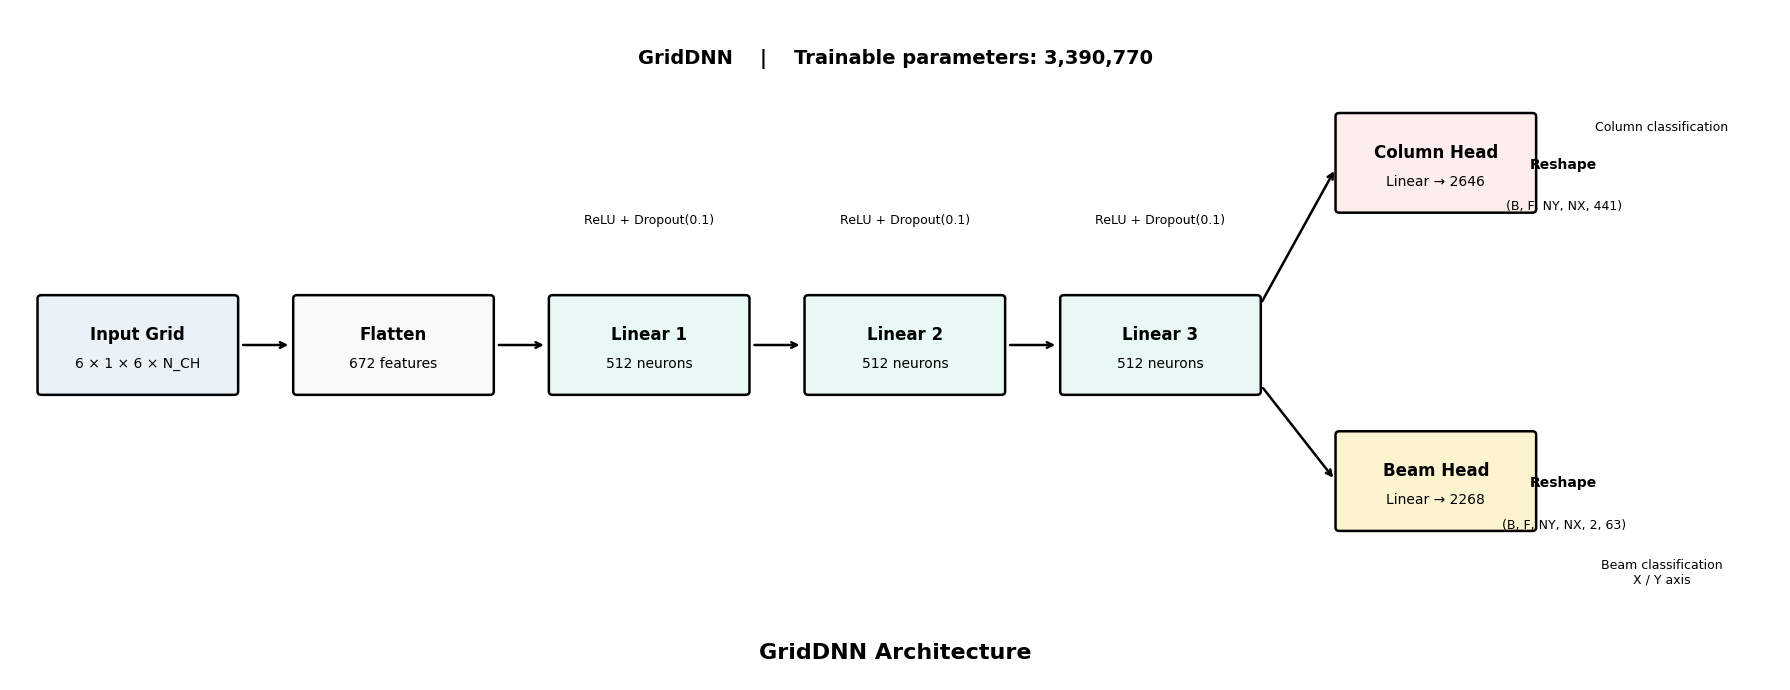

Saved to: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/GridDNN_architecture.png


In [29]:
# ============================================================
# GridDNN Architecture Visualization
# Google Colab
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# 1. Model dimensions
# ------------------------------------------------------------
N_CH = 1

F  = 6
NY = 1
NX = 6

K_COL  = 441       # 2646 / (F * NY * NX)
K_BEAM = 63        # 2268 / (F * NY * NX * 2)

INPUT_DIM = F * NY * NX * N_CH   # 216 if N_CH=1
# Your printed model has 672 input features.
#
# Therefore, use the actual model dimension for the diagram.
INPUT_DIM = 672

HIDDEN = [512, 512, 512]

COL_OUTPUT  = 2646
BEAM_OUTPUT = 2268

TOTAL_PARAMS = 3_390_770


# ------------------------------------------------------------
# 2. Helper functions
# ------------------------------------------------------------
def add_box(ax, x, y, width, height, title, subtitle="",
            fontsize=12, facecolor="white", edgecolor="black",
            linewidth=1.8):

    box = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.02,rounding_size=0.04",
        linewidth=linewidth,
        edgecolor=edgecolor,
        facecolor=facecolor,
    )

    ax.add_patch(box)

    ax.text(
        x + width / 2,
        y + height * 0.60,
        title,
        ha="center",
        va="center",
        fontsize=fontsize,
        fontweight="bold",
    )

    if subtitle:
        ax.text(
            x + width / 2,
            y + height * 0.30,
            subtitle,
            ha="center",
            va="center",
            fontsize=fontsize - 2,
        )

    return box


def add_arrow(ax, x1, y1, x2, y2, text=None, text_offset=(0, 0.12)):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=1.8,
            shrinkA=5,
            shrinkB=5,
        ),
    )

    if text:
        ax.text(
            (x1 + x2) / 2 + text_offset[0],
            (y1 + y2) / 2 + text_offset[1],
            text,
            ha="center",
            va="center",
            fontsize=9,
        )


# ------------------------------------------------------------
# 3. Create figure
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(18, 7))

ax.set_xlim(0, 18)
ax.set_ylim(0, 8)
ax.axis("off")


# ------------------------------------------------------------
# 4. Main network
# ------------------------------------------------------------

BOX_W = 2.0
BOX_H = 1.15

y_main = 4.0 - BOX_H / 2

# Input
add_box(
    ax,
    0.3,
    y_main,
    BOX_W,
    BOX_H,
    "Input Grid",
    f"{F} × {NY} × {NX} × N_CH",
    facecolor="#EAF2F8",
)

# Flatten
add_box(
    ax,
    2.9,
    y_main,
    BOX_W,
    BOX_H,
    "Flatten",
    f"{INPUT_DIM} features",
    facecolor="#F8F9F9",
)

# Hidden layers
x_hidden = [5.5, 8.1, 10.7]

for i, (x, width) in enumerate(zip(x_hidden, HIDDEN)):

    add_box(
        ax,
        x,
        y_main,
        BOX_W,
        BOX_H,
        f"Linear {i+1}",
        f"{width} neurons",
        facecolor="#E8F8F5",
    )

# Output heads
col_x = 13.5
beam_x = 13.5

col_y = 5.6
beam_y = 1.8

add_box(
    ax,
    col_x,
    col_y,
    BOX_W,
    BOX_H,
    "Column Head",
    f"Linear → {COL_OUTPUT}",
    facecolor="#FDEDEC",
)

add_box(
    ax,
    beam_x,
    beam_y,
    BOX_W,
    BOX_H,
    "Beam Head",
    f"Linear → {BEAM_OUTPUT}",
    facecolor="#FCF3CF",
)


# ------------------------------------------------------------
# 5. Arrows through network
# ------------------------------------------------------------

# Input → Flatten
add_arrow(
    ax,
    2.3,
    4.0,
    2.9,
    4.0,
)

# Flatten → Hidden 1
add_arrow(
    ax,
    4.9,
    4.0,
    5.5,
    4.0,
)

# Hidden 1 → Hidden 2
add_arrow(
    ax,
    7.5,
    4.0,
    8.1,
    4.0,
)

# Hidden 2 → Hidden 3
add_arrow(
    ax,
    10.1,
    4.0,
    10.7,
    4.0,
)

# Hidden 3 → Column head
add_arrow(
    ax,
    12.7,
    4.45,
    13.5,
    6.15,
)

# Hidden 3 → Beam head
add_arrow(
    ax,
    12.7,
    3.55,
    13.5,
    2.35,
)


# ------------------------------------------------------------
# 6. Layer operation labels
# ------------------------------------------------------------

ax.text(
    6.5,
    5.45,
    "ReLU + Dropout(0.1)",
    ha="center",
    fontsize=9,
)

ax.text(
    9.1,
    5.45,
    "ReLU + Dropout(0.1)",
    ha="center",
    fontsize=9,
)

ax.text(
    11.7,
    5.45,
    "ReLU + Dropout(0.1)",
    ha="center",
    fontsize=9,
)


# ------------------------------------------------------------
# 7. Output reshaping
# ------------------------------------------------------------

ax.text(
    15.8,
    6.15,
    "Reshape",
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
)

ax.text(
    15.8,
    5.65,
    f"(B, F, NY, NX, {K_COL})",
    ha="center",
    va="center",
    fontsize=9,
)

ax.text(
    15.8,
    2.35,
    "Reshape",
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
)

ax.text(
    15.8,
    1.85,
    f"(B, F, NY, NX, 2, {K_BEAM})",
    ha="center",
    va="center",
    fontsize=9,
)


# ------------------------------------------------------------
# 8. Head descriptions
# ------------------------------------------------------------

ax.text(
    16.8,
    6.55,
    "Column classification",
    ha="center",
    fontsize=9,
)

ax.text(
    16.8,
    1.15,
    "Beam classification\nX / Y axis",
    ha="center",
    fontsize=9,
)


# ------------------------------------------------------------
# 9. Parameter count
# ------------------------------------------------------------

ax.text(
    9.0,
    7.35,
    f"GridDNN    |    Trainable parameters: {TOTAL_PARAMS:,}",
    ha="center",
    fontsize=14,
    fontweight="bold",
)


# ------------------------------------------------------------
# 10. Title
# ------------------------------------------------------------

ax.text(
    9.0,
    0.25,
    "GridDNN Architecture",
    ha="center",
    fontsize=16,
    fontweight="bold",
)


plt.tight_layout()

# ------------------------------------------------------------
# 11. Save high-resolution figure
# ------------------------------------------------------------
output_path = FIG_DIR / "GridDNN_architecture.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Saved to: {output_path}")

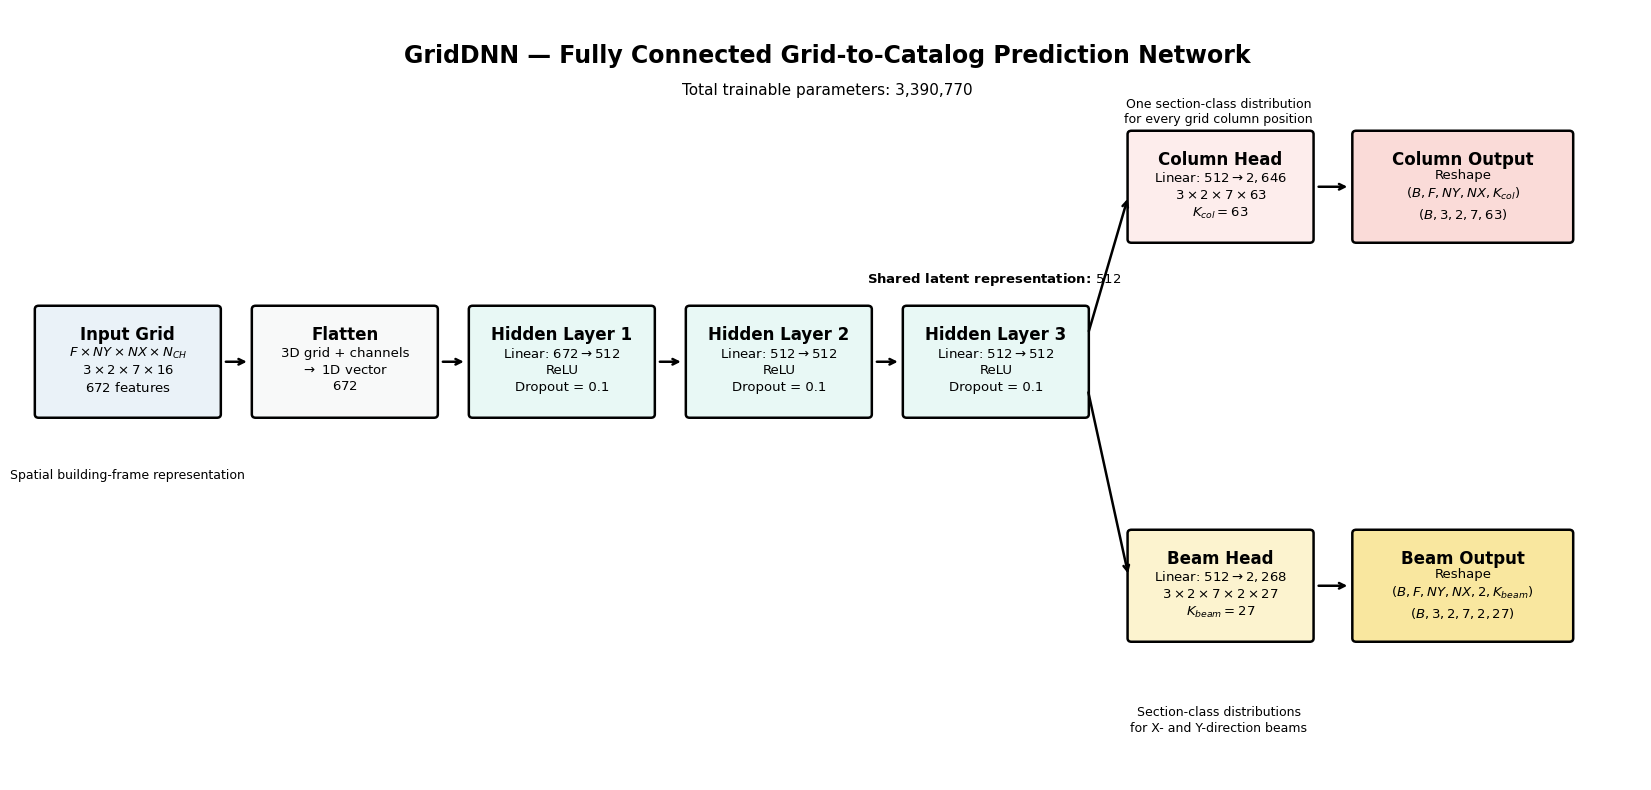

GridDNN architecture diagram generated
Input:        3 × 2 × 7 × 16 = 672
Hidden:       672 → 512 → 512 → 512
Column head:  3 × 2 × 7 × 63 = 2646
Beam head:    3 × 2 × 7 × 2 × 27 = 2268
Parameters:   3,390,770
Saved to:     /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/figures/GridDNN_architecture_detailed.png


In [30]:
# ============================================================
# GridDNN Architecture Visualization
# Detailed dimensional version
# Google Colab
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch


# ============================================================
# 1. GridDNN dimensions
# ============================================================

F = 3
NY = 2
NX = 7
N_CH = 16

INPUT_DIM = F * NY * NX * N_CH
# 3 × 2 × 7 × 16 = 672

HIDDEN = 512
DROPOUT = 0.1

K_COL = 63
K_BEAM = 27

COL_OUTPUT = F * NY * NX * K_COL
# 3 × 2 × 7 × 63 = 2646

BEAM_OUTPUT = F * NY * NX * 2 * K_BEAM
# 3 × 2 × 7 × 2 × 27 = 2268

TOTAL_PARAMS = 3_390_770


# ============================================================
# 2. Drawing functions
# ============================================================

def add_box(
    ax,
    x, y,
    width, height,
    title,
    lines,
    facecolor="white",
    edgecolor="black",
    title_size=12,
    text_size=9.5,
):

    box = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.025,rounding_size=0.05",
        linewidth=1.8,
        edgecolor=edgecolor,
        facecolor=facecolor,
    )

    ax.add_patch(box)

    # Title
    ax.text(
        x + width / 2,
        y + height * 0.75,
        title,
        ha="center",
        va="center",
        fontsize=title_size,
        fontweight="bold",
    )

    # Body
    if isinstance(lines, str):
        lines = [lines]

    body = "\n".join(lines)

    ax.text(
        x + width / 2,
        y + height * 0.42,
        body,
        ha="center",
        va="center",
        fontsize=text_size,
        linespacing=1.35,
    )

    return box


def add_arrow(ax, x1, y1, x2, y2, linewidth=1.8):

    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=linewidth,
            shrinkA=5,
            shrinkB=5,
        ),
    )


# ============================================================
# 3. Figure
# ============================================================

fig, ax = plt.subplots(figsize=(21, 10))

ax.set_xlim(0, 21)
ax.set_ylim(0, 11)
ax.axis("off")


# ============================================================
# 4. Box dimensions
# ============================================================

W = 2.35
H = 1.55


# ============================================================
# 5. Main network boxes
# ============================================================

y = 5.2

# ------------------------------------------------------------
# Input
# ------------------------------------------------------------

add_box(
    ax,
    0.3, y,
    W, H,
    "Input Grid",
    [
        r"$F \times NY \times NX \times N_{CH}$",
        r"$3 \times 2 \times 7 \times 16$",
        r"$672$ features",
    ],
    facecolor="#EAF2F8",
)


# ------------------------------------------------------------
# Flatten
# ------------------------------------------------------------

add_box(
    ax,
    3.1, y,
    W, H,
    "Flatten",
    [
        "3D grid + channels",
        r"$\rightarrow$ 1D vector",
        r"$672$",
    ],
    facecolor="#F8F9F9",
)


# ------------------------------------------------------------
# Hidden Layer 1
# ------------------------------------------------------------

add_box(
    ax,
    5.9, y,
    W, H,
    "Hidden Layer 1",
    [
        r"Linear: $672 \rightarrow 512$",
        "ReLU",
        "Dropout = 0.1",
    ],
    facecolor="#E8F8F5",
)


# ------------------------------------------------------------
# Hidden Layer 2
# ------------------------------------------------------------

add_box(
    ax,
    8.7, y,
    W, H,
    "Hidden Layer 2",
    [
        r"Linear: $512 \rightarrow 512$",
        "ReLU",
        "Dropout = 0.1",
    ],
    facecolor="#E8F8F5",
)


# ------------------------------------------------------------
# Hidden Layer 3
# ------------------------------------------------------------

add_box(
    ax,
    11.5, y,
    W, H,
    "Hidden Layer 3",
    [
        r"Linear: $512 \rightarrow 512$",
        "ReLU",
        "Dropout = 0.1",
    ],
    facecolor="#E8F8F5",
)


# ============================================================
# 6. Output heads
# ============================================================

# Column head
col_y = 7.7

add_box(
    ax,
    14.4, col_y,
    W, H,
    "Column Head",
    [
        r"Linear: $512 \rightarrow 2,646$",
        r"$3 \times 2 \times 7 \times 63$",
        r"$K_{col}=63$",
    ],
    facecolor="#FDEDEC",
)


# Beam head
beam_y = 2.0

add_box(
    ax,
    14.4, beam_y,
    W, H,
    "Beam Head",
    [
        r"Linear: $512 \rightarrow 2,268$",
        r"$3 \times 2 \times 7 \times 2 \times 27$",
        r"$K_{beam}=27$",
    ],
    facecolor="#FCF3CF",
)


# ============================================================
# 7. Output reshaping boxes
# ============================================================

add_box(
    ax,
    17.3, col_y,
    2.8, H,
    "Column Output",
    [
        r"Reshape",
        r"$(B,F,NY,NX,K_{col})$",
        r"$(B,3,2,7,63)$",
    ],
    facecolor="#FADBD8",
)


add_box(
    ax,
    17.3, beam_y,
    2.8, H,
    "Beam Output",
    [
        r"Reshape",
        r"$(B,F,NY,NX,2,K_{beam})$",
        r"$(B,3,2,7,2,27)$",
    ],
    facecolor="#F9E79F",
)


# ============================================================
# 8. Arrows: main body
# ============================================================

center_y = y + H / 2

add_arrow(
    ax,
    2.65, center_y,
    3.1, center_y,
)

add_arrow(
    ax,
    5.45, center_y,
    5.9, center_y,
)

add_arrow(
    ax,
    8.25, center_y,
    8.7, center_y,
)

add_arrow(
    ax,
    11.05, center_y,
    11.5, center_y,
)


# ============================================================
# 9. Branching arrows
# ============================================================

# Hidden 3 → Column head
add_arrow(
    ax,
    13.85, y + H * 0.72,
    14.4, col_y + H * 0.45,
)

# Hidden 3 → Beam head
add_arrow(
    ax,
    13.85, y + H * 0.28,
    14.4, beam_y + H * 0.55,
)


# ============================================================
# 10. Output arrows
# ============================================================

add_arrow(
    ax,
    16.75, col_y + H / 2,
    17.3, col_y + H / 2,
)

add_arrow(
    ax,
    16.75, beam_y + H / 2,
    17.3, beam_y + H / 2,
)


# ============================================================
# 11. Tensor descriptions
# ============================================================

# Input description
ax.text(
    1.47,
    4.35,
    "Spatial building-frame representation",
    ha="center",
    va="center",
    fontsize=9,
)

# Column description
ax.text(
    15.55,
    9.55,
    "One section-class distribution\nfor every grid column position",
    ha="center",
    va="center",
    fontsize=9,
)

# Beam description
ax.text(
    15.55,
    0.85,
    "Section-class distributions\nfor X- and Y-direction beams",
    ha="center",
    va="center",
    fontsize=9,
)


# ============================================================
# 12. Global model information
# ============================================================

ax.text(
    10.5,
    10.35,
    "GridDNN — Fully Connected Grid-to-Catalog Prediction Network",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold",
)

ax.text(
    10.5,
    9.85,
    f"Total trainable parameters: {TOTAL_PARAMS:,}",
    ha="center",
    va="center",
    fontsize=11,
)


# ============================================================
# 13. Add dimension annotations
# ============================================================

# Main latent representation
ax.text(
    12.65,
    7.15,
    r"Shared latent representation: $512$",
    ha="center",
    va="center",
    fontsize=9.5,
    fontweight="bold",
)


# ============================================================
# 14. Save
# ============================================================

output_path = FIG_DIR / "GridDNN_architecture_detailed.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("=" * 60)
print("GridDNN architecture diagram generated")
print("=" * 60)
print(f"Input:        {F} × {NY} × {NX} × {N_CH} = {INPUT_DIM}")
print(f"Hidden:       {INPUT_DIM} → {HIDDEN} → {HIDDEN} → {HIDDEN}")
print(f"Column head:  {F} × {NY} × {NX} × {K_COL} = {COL_OUTPUT}")
print(f"Beam head:    {F} × {NY} × {NX} × 2 × {K_BEAM} = {BEAM_OUTPUT}")
print(f"Parameters:   {TOTAL_PARAMS:,}")
print(f"Saved to:     {output_path}")
download_file(output_path)

## Bundle all results

In [31]:
# Bundle every figure and table produced by this notebook into one zip (downloaded automatically in Colab)
zip_path = OUTPUT_DIR / f'{dnn}-analysis-figures-and-tables.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in list(FIG_DIR.glob('*')) + list(TAB_DIR.glob('*')):
        z.write(p, arcname=f'{p.parent.name}/{p.name}')
print('Created:', zip_path)
if IN_COLAB:
    files.download(str(zip_path))

Created: /content/drive/MyDrive/research/dnn8/dnn-alm-results/analysis/DNN8-alm-analysis-figures-and-tables.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>